In [1]:
# ============================================================
# Parte 0 · Parámetros del grupo y generador aleatorio único
# ============================================================
# C1 y C2 son las cédulas de los integrantes (sin puntos ni espacios).
# La semilla del grupo es S = C1 + C2; todos los sorteos del notebook salen de `rng`.
import numpy as np

C1 = 1141318021   # integrante 1: Juan Pablo Vásquez
C2 = 1018421230   # integrante 2: Juan Sebastián García
S = C1 + C2       # = 2159739251
assert S == 2159739251, "La semilla S no coincide con C1 + C2"
rng = np.random.default_rng(S)   # ÚNICA fuente aleatoria del notebook
_RNG_ORIGINAL = rng              # referencia para comprobar al final que nadie lo reemplazó

# Parámetros personalizados (sección 3 del enunciado), todos derivados de S
tau = 180 + 10 * (S % 9)                    # umbral del SLO de latencia (ms)
eps = round(0.01 * (1 + S % 3), 10)         # fracción máxima tolerada de violaciones
conf = {0: 0.90, 1: 0.95, 2: 0.99}[S % 3]   # nivel de todos los intervalos
alpha = 1 - conf                            # nivel de significancia
g = round(1.4 + 0.1 * (S % 7), 10)          # factor de crecimiento del tráfico (Parte G)
t1 = 80 + 10 * (S % 5)                      # corte pequeña/mediana (KB)
t2 = 400 + 25 * (S % 5)                     # corte mediana/grande (KB)
pi_prod = (4 + S % 6) / 1000                # prevalencia de incidentes en producción
kmax = 4 + S % 5                            # máximo de falsas alarmas diarias toleradas
r = S % 6                                   # desplazamiento del umbral en B4
N = 10 + S % 11                             # solicitudes consecutivas en C4

# Comprobación: los valores deben ser exactamente los del grupo
ESPERADOS = dict(tau=260, eps=0.03, conf=0.99, g=1.9, t1=90, t2=425, pi_prod=0.009, kmax=5, r=5, N=20)
for _nombre, _valor in ESPERADOS.items():
    assert abs(globals()[_nombre] - _valor) < 1e-12, f"{_nombre} = {globals()[_nombre]} ≠ {_valor}"
print(f"S = {S} | tau = {tau} ms | eps = {eps} | conf = {conf} (alpha = {alpha:.2f}) | g = {g}")
print(f"t1 = {t1} KB | t2 = {t2} KB | pi = {pi_prod} | kmax = {kmax} | r = {r} | N = {N}")

S = 2159739251 | tau = 260 ms | eps = 0.03 | conf = 0.99 (alpha = 0.01) | g = 1.9
t1 = 90 KB | t2 = 425 KB | pi = 0.009 | kmax = 5 | r = 5 | N = 20


# Proyecto Final CCI · AndesVision AI

✍️ *[Portada e introducción — pegue aquí su texto]*

In [2]:
# ============================================================
# Parte 0 · Datos incrustados (celda generada; contiene los tres CSV oficiales)
# ============================================================
# Los tres CSV oficiales están dentro del notebook, comprimidos con LZMA y codificados en base64.
# El notebook no depende de archivos de entrada, rutas ni descargas.
# Al descomprimir se verifica la huella SHA-256 de cada archivo original.
# La ventana de validación queda guardada pero SOLO se descomprime en F6.
import base64, hashlib, io, lzma
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)

_DATOS = {}
_DATOS["solicitudes"] = dict(
    archivo="solicitudes (1).csv", bytes=1552387,
    sha256="072b7b69087cae0a2d4d9a09583e6e2e6bc961a73506b73ad645e6158af3e367",
    lzma_b64=(
    "..."
    ))

_DATOS["monitoreo"] = dict(
    archivo="monitoreo (1).csv", bytes=70917,
    sha256="e24fc592ef74d54038b2e797cdb66e293f33a87a01b0e33759637d89bd700c6b",
    lzma_b64=(
    "/Td6WFoAAATm1rRGAgAhARwAAAAQz1jM4RUEELBdADaaSiB1ZPm49VsdoMmx5EeiB9N+00H/4O3AqGHrbsdeek0DeR8JUz2jYVgjiLoTAtLK4Jxmh2G0Z+ip"
    "WaMtclFxchJ34/f2YDqsgnsjGcY7dYinGJAyF1UKC6qQvOughpdx7WUiUs1CwfMadZc65VcMAsPHV6/VDlmVvQpGyHYdQT0uoJv2V60gwcfTN5C3ylOL9unm"
    "vkOrea/tEAY0W0xkXGlOGznWiuI1Xl+KGRlku5WPlwaaauyJJHQlildSTTQmjUmBMMzn0Jvv/K9ieJGZc8WK43gk0Uz8ryWveQq31zjn4XaVK08yzPRoNTZ0"
    "NG/FU/vfP3BXk3p75TOAZgGjUdoai2NPwQHJFLsC+TfZC1nucKPokxuyCeMbCRBC/3YOWcm1q0OvNtF692AgMni/GmW7nuGlJb2o8s9B5SUPqn/eFQNj5bKF"
    "8Skuupi98qhJKqwOgFGs4zJ8Ysnssz4BkG5iKNbzjDtwuP/UajU0tNtIX7SbH0hIyZzeFmE7UnYr/GEdS8JyXUqUHoj0MRf5CjUMWXZucviEhol5lmeiB9ca"
    "L0w36byAsEJIc5dzUe0pnJwUy4ZJ1igXndSUjfqfDl7QFK40oCD1v+4p+6KR9SNUPGHNG5RKcOA08hj7mlA5HcShX80jplU4fKgY9cSEznWW50VekI3XfSKU"
    "/MpAVL5Hd2mlXCcLhgZfZXRYIW9tviU3j7OiO1azYtc16Gspy8Q/7acuH4x0P1S29JLUvkEFLVaAtO3qxW131UR0wop+E8yJ35C6iokimaEqKb3L6Sbt1aQK"
    "+gTbQUWAgmyRTIj367mRrmkp68eUMQENLFxKTjIL33zEYmVIxXIbpBGI9m3or2Kvp05sxuWAt0nk+dBsF58MdRkMJLwo2MN5HV7p9YIxKS1PiCrLrnLZLSyI"
    "UYbCcf4PbfEOv5HCi6yBIscNuS956y9W9K1Fx6fkiUkxOQk8RyxPZgyqSlx0wfO/oCDhCsxnpY+/kWho/In4W5vkVnBI6U38pQOu86mi5hQycIV9VYRpU9QZ"
    "CxncX6sJBFUGaZKusDG7KY/rQtBROjfzPTbHN/J7MoOVpdg0bk+T0Ffr9mBSpGXbIiqLjY4Qo5mgXu3oFCNuynK9hh34XzvFa+1AHbGiLlOs+LKFqVUFjszV"
    "cmk+sXf0qt7gI7upwt0oeeXmVg0sZVJ18hdMttD2Nd+OGaL4KUYollwOW03qeEsJSCIahg754L0tpRqJI1d7nHhWKbxvhIloWkiOdq+RxWnzmTPmMcngdxUW"
    "UgQXztqNGDJRTTMu6C4JrKoyTsf+oG71eYdMeVmCUVGshOlmNG58/bIP0nqe0BGUnzD5RSGWjdLzcIgryWp6mM6AHghbmDdVHDh7ce557lSHA6sbUAGHhsNL"
    "jO2KSb7tjJmFJHIq7cIK4e2U3IwGzRyTn4fZ5314D4/4CIvzmLhRamL14NAE2YXNJ9f+BJQTkmHoZehxxRnkoIRsQ7Bc7Scsf1QPadP26WmSzn/dR5gjmyko"
    "HYKfmEA0uU9CWNKugvNaKXXEu61YVpAzzrcnGLHw+IOsOgqM69kqmvnULBDXQjkbMAB8I9VkxtPpNXHpUphKEvfUEyQDtgBYrrn52kDB6a200BnwhCX2ePlG"
    "anfiuzo556M/nlArAKSAGZ9iD+Ws/zPB9NYUMI30ClnlerstAr+9dYUcHDwNCDB2lF6v4REjitOyuil2Rp6J7lx1jmaWUnEsuYXEHSNR853shjyyg35ft0EK"
    "ztT2PahnL6ILjXOfxO7KMaNjii8swV8ukTOv8auiCA+iMP4WI+tJQ0MwCT33KDYML9vtkptKzYtXscOLpj52lTlDqUpnzVZXqLvc1HzSjwTw2HUXInHTbUDx"
    "SbcsUSQfTUwY52eZqCjoWUf1KIXE9m/i3Qo8YHC32UjdRbPU9IgxHfWp1LNxFQrggK7W4uCeaYntm2AssQ1GHDLBsDaz7F/CIzH0rcmIkZeGEgU5GHjMWrch"
    "X8qFL8fDJ6CN+ltzvfNHEPQZrPV0f28zAl7vuy02i1r7miz2XX8WMc9//SF9LumVTWi/gBOY9OnJYGvx4I7m/SnUGcMHzFSocFguwUQbWhJLjr4cyAwPQNGc"
    "72Tkqk78sBI7ZS1OTEBvgrrCAYCztWROai9Xe7dafoixBlN0nXJa1D0XAxxdxe/cOhPX3R9Z/7blrlxWYOac9kjYAZ7kr6Sie2ANs1dKv3Vw2eKLJRBzIsDO"
    "vkPPxEVxeJecEbr6fgosjp+QHoJbGtNIfZ24hxDvvvAJnP+pSa3A/cRz/egVvrLJ8tsBYyEBbwfH732o3CWrH2idtuhV7gjkde1oYtFZGVVKu72cg4Eik2cB"
    "IqSrR5KCQ6C3gXs0z6A+olXIrnM4gtuBwPf8+5SoXf5jrqEIFO27DkNwxwEY/yMZhoJi6TVwanHaa6P0wUW2kKq3jtIZI0aFARlHxSQo7zKhoEBZHoR3TUpe"
    "d22mcRhXwu9zBQXaz6ONPWAUPim3JJDexf/EpntMcuyGJFQGEV2vHU8E/PUV1A26K/JV5Ev8mp+wXj4Uui0RfGhDTITlUr0OduWckpwgxZ7QGL5fxagn3owJ"
    "0aD8CHbt8k6jH4t+WhzmiC3QDEH7eGa8MErZEExTaUa89JxmG2Um3144UVJSouvXHeXs5QQRzWkpSjTYVFofpe9oxHlhM1cTlueHEAHaabGMYLU5RD4Vjvj/"
    "6g/1/Bn1wicijFCECgkLBz83KhQiGO8aV3poK7GM8TGDRid5jEPhIYml+6hOlJBplmkR2UvXgeHC0NwoCTlV48G2tAbdUNipR6HDj2ZkF+LVbX2kmIAIOXeU"
    "hCBy74MLJn4V6NUtzMLzcCFaz2ZLwzc+QQnPRGRydMxfMYaHh7CPEV9f5NvgoI8+ex/htDTdGMqSx2MXEEk7CYBdVIcwYi1874FDUWNTOI04CytGgXRMP13X"
    "osCBjvJ4mhT06p2Y6a1MWv8UDzIUeBfvzpF4lLXL0R9/TyIRDBpokGy8lrLChNz0hFNMHoEEwAJhqtZSLOdLom1OYlrxUpl+pytUhnRaL5wIXZUXh2/zSQFW"
    "5KqChl+7d/qgpK9Ibhfv+qCAr26SJdfk6wZh1A3PKA/FeEynFt7lVyOLx/VnSAZ5Ni8t9SowD9160kCJTHu5jarAoJGbyaZLVSKLxn2WjTUmtN7gxuvgaznc"
    "4DRfj/6zdeZ5iddUXWPjP0DZxqc2LOyH83x8/yulcxW22q4hmikKNab0dN8wHrg4qyJItEe3ZknkBb4Oabls8i79qcTMfXmzBdimCjWeA9T79KdHCfPJc4Yt"
    "VKaaN1mGlsCUIhcCjtCI8RbUIMPchLrfdFjiKdOBsiLj5KXj4WFcscBcc2+ak70+jRGWUCVXfANwar7lJfKOojyp3Hef/b5OKebnTis4qgJp4Zy7is8Zhzt6"
    "FEHeGbWP8ALxu+lpC3xJfOkHgYxKNiUtctJB3uoen+zuu9XhOuhmVYHH6232CLAYEvoN7yjlMETlT8niN4kNHjArkwyjPhf5PVGdACYMi5mhHFfGJz+X98Cz"
    "x6usPHcy5/EnYTDMcOQlVQP8eBpskzPEnFBEqZaUvPQ6WwEwy++P3INiLpeImJhk/wyCqad0+DqFgOQTx4hC8cs47qitrmYlgMeiLM2CeJ+vp4t7SnMK5Uli"
    "l1102BvPUXVjLN+Z6dhQROPpkkItc59oXc158Drvi0rCmxR34FyB/O89ahBho/ourmQZ2GR4y+2LOEzalY7TzYra0yebMNl2KxLQvjlYH+YfZT8gFJv1yTtx"
    "ZyJhLjp6hKn4ZkATt+o+6mv1NicmU2rZu6RWK2K+jKFUMdxO6hgNsASYyZPbYK9HC4a2h5xhk8xrzlkb/qApxkw8W4irXhg+joxbzslfaYOZgpLt8LOjE2af"
    "Tsj6NDp3H1QizchPt5rtQFvxfOk1u7LdT56ZAJGALJBzPLepyIhjg16iqLwFUANI2COMF0NFljgndrB9LXude7sCixQGZLFAflyVhzx3BYe0+gjMqHJKdokL"
    "cGwMajs6A+DoP143BPfkKH/35j15O/Wvh65cibYXOMnGkH9rWSeoJD7BG4ri60vHsM3KwNuzhVw/RuAAbFJroZpXrBIDcaHs1Mk8Ao8jOzjR5g1LHwUCGzYR"
    "66UuHHHO9H/2/q34Nf7JIM7L19n0cIrgAaEibG68UMx4DxTGVRuc63fyGe/UttPFBJekkbOAcyw+ZNpyoBcaRSGtnTNU4pVjYSLM5MUko1kjqCzqd+52ecs3"
    "9T7hS5G+ian7WB4Q5BMdAwCkIERUBF23IyNs1gY9csiRGtBQxW0Srn40hSZk1ZYrEUu1I1OvF8ery1qbb00cyYcPKfo+lhh0gBajAFnW/cv9cIqLQnYXHeZ1"
    "YlPYRJgXGaMvqJZTbHlnYDyfV2r0LKxRFMBE972Up6LlyLx5ioe/Pkp4l82wNAaebf+qunNoHURlhqt4F4b3q5NjiQ1yDlqpSNEfqpojEj1xkly6JhM4gM7d"
    "4UEl2sJuGBuzsktX6CxM+n80sz22PRqRGO6G2CPLHXJxNT8YqG+KeNwAVxRmZIFOu/y8VZzTEgT69ECA8chyaobbiAhxF44KQujOmmmmPycxCUYq5BDkZcew"
    "MK0qi6ki7e7P9rLhhQIu3iPnbd1P2XNfVDGA3xLDC/Kqs6rHUvsL2d7ypFyR3f4eS5sFm9e/xMx2D9N/kn0HYy7P4zASa0+k6nvaN2wwsT6wPnpRusA8sFqw"
    "MBjfe5rQ3F+w/mZc1jCN1wl1z0SdzizAnRkd9/ETT/ZWziHycb4PDrIljXNVKpHQEmZ3t0U5zkSuwpxXzEPfPytfD5/0TRqYYCXH1/VkdiLqvSQBKXen+dI3"
    "2j2ynE1DzotIJnr9nB//kN6f7AiSS/diJN6UZGefsYxEhUI5d6faTPVliOr/ZUCHxsYFSydEPodG7W8yMAcIEyctWZZFeTMUbWOgEUe9bcBdtsDbEN3n+3wf"
    "Bee56YZPEN09JA5Kb91fRX/MkZWySUFVtQi9zPgjXY8wMuoJoSfQ9M37WqJnAENCFWcxxUWfvbAGuGltPuKJ6HeLBvF+3fAHOhm0vTquZoo1Ef5yyeALWPia"
    "+bqFI2MJj3r0swfT13L2Q+DKLEyQ5OtRAAX5sLPe0pml2fO+MVHHzd2V7RGKh+szmvmVJAufrylqgbMewbK7fsPbwQIqv6jIIM1B/KiVRWYq0jKv8y8Lub0a"
    "6yteDqczq7ewM3+J4+F5yarSB3yMabQDD3aWpLk9XdjqBFAVwYnufIdb9TCvX5z1wGDFJvBfVnlgoIcn5F1pklPN4olWoxP3W1JTzGOe6w+NEWDNPjSC7G5S"
    "72SpXF1QdQ/nZKCUZAFvLYYJP0hf3JLSwMZJKLAu7XdXeDV/Xmi5ztJM8ofQvRM3ZZVxKeOVNEz+T1/T+49sCbaQm0gQINGJ87GgMa9x2GddBrHqUVj9zQiB"
    "/zhnbAO2AevQ6DWsWU2VOdxxS8pPQX97P7dWnwyFYZvQTY+0X725doMtQCpZ3UQvQUW2uCIJJWKikVBHF6u+mNDOxbiffwbivyzHa2ksQz2vFX+oPskI54AP"
    "rkEMN6NfosKSovpb6lCA0wfdHuDqvAhJXjTc7smQQUwaSpZsMVbQ2hegxSmFIEQkq1COAhLsiseVTWnsbp8cWhDnxCZmE/8RAAB4bzfiKHtjvAABzCGFqgQA"
    "HVfaM7HEZ/sCAAAAAARZWg=="
    ))

_DATOS["solicitudes_validacion"] = dict(
    archivo="solicitudes_validacion (1).csv", bytes=1226875,
    sha256="cd9f744ee210ac62153461b21ffc7eb6d009b033e0e5afa17bbdd13684f0eb0a",
    lzma_b64=(
    "..."
    ))


def _descomprimir(clave):
    """Descomprime un CSV incrustado y comprueba que sea idéntico al original (SHA-256)."""
    d = _DATOS[clave]
    contenido = lzma.decompress(base64.b64decode("".join(d["lzma_b64"])))
    huella = hashlib.sha256(contenido).hexdigest()
    assert len(contenido) == d["bytes"] and huella == d["sha256"], f"{d['archivo']}: SHA-256 no coincide"
    print(f"  {d['archivo']}: {len(contenido):,} bytes, SHA-256 verificado ({huella[:16]}…)")
    return contenido

def abrir_csv(clave):
    """Datos de trabajo (solicitudes y monitoreo). La validación NO se abre por aquí."""
    assert clave != "solicitudes_validacion", "La ventana de validación solo se abre en F6"
    return _descomprimir(clave)

APERTURAS_VALIDACION = []   # registro de quién abrió la validación (debe ser solo 'F6')
def abrir_validacion(item):
    assert item == "F6", "La ventana de validación solo se abre en F6"
    APERTURAS_VALIDACION.append(item)
    return _descomprimir("solicitudes_validacion")

print("Datos incrustados:", {k: v["archivo"] for k, v in _DATOS.items()})

Datos incrustados: {'solicitudes': 'solicitudes (1).csv', 'monitoreo': 'monitoreo (1).csv', 'solicitudes_validacion': 'solicitudes_validacion (1).csv'}


# Parte A — Auditoría y preparación de los datos

✍️ *[Parte A — introducción: pegue aquí su texto]*

## A1 · Auditoría de solicitudes.csv

✍️ *[A1 — planteamiento: pegue aquí su texto]*

In [3]:
# Parte A · A1 — Carga del archivo original sin modificarlo (desde los datos incrustados)
# Lectura de la telemetría original, previa a los filtros de calidad.
# La tabla cruda sirve de referencia para cuantificar los cambios de la limpieza.
crudo = pd.read_csv(io.BytesIO(abrir_csv("solicitudes")))
print("Filas:", len(crudo), "| Columnas:", list(crudo.columns))
crudo.describe().T.round(3)

  solicitudes (1).csv: 1,552,387 bytes, SHA-256 verificado (072b7b69087cae0a…)
Filas: 32603 | Columnas: ['id_solicitud', 't_llegada_s', 'tam_kb', 'cache_hit', 'version', 'red_ms', 'gpu_ms', 'latencia_ms', 'intentos', 'exito']


,count,mean,std,min,25%,50%,75%,max
id_solicitud,32603.0,16250.945,9383.383,1.000,8127.500,16249.00,24374.500,32506.000
t_llegada_s,32603.0,601.331,312.229,0.018,370.488,605.31,823.112,1199.956
tam_kb,32603.0,632.456,12190.291,1.290,114.770,201.65,325.345,858112.000
cache_hit,32603.0,0.317,0.465,0.000,0.000,0.00,1.000,1.000
red_ms,32570.0,23.365,3.581,8.290,20.960,23.33,25.800,38.390
gpu_ms,32571.0,31.557,34.712,0.000,0.000,24.70,47.415,392.690
latencia_ms,32603.0,67.907,54.797,-1.000,26.020,53.77,87.725,625.590
intentos,32603.0,1.235,0.513,1.000,1.000,1.00,1.000,3.000
exito,32603.0,0.990,0.099,0.000,1.000,1.00,1.000,1.000


In [4]:
# Parte A · A1 — Reglas físicas: se marca cada fila que viola una regla (no se borra nada aún)
# TOL tolera el redondeo a centésimas de los tiempos medidos.
TOL = 0.021  # suma de tiempos redondeados a centésimas
# Cada bandera identifica una regla incumplida. Una fila puede activar varias reglas a la vez.
def detectar_inconsistencias(d):
    kb = d.tam_kb / 1024
    escala = (d.tam_kb > 10000) & kb.between(1, 2000) & np.isclose(kb * 100, np.rint(kb * 100), atol=1e-6, rtol=0)
    return pd.DataFrame({
        "duplicada": d.duplicated(),
        "id_repetido_no_exacto": ~d.duplicated() & d.loc[~d.duplicated(), "id_solicitud"].duplicated(keep=False).reindex(d.index, fill_value=False),
        "tam_escala": escala, "tam_vacio": d.tam_kb.isna(),
        "red_faltante": d.red_ms.isna(), "gpu_faltante": d.gpu_ms.isna(),
        "red_negativa": d.red_ms < 0,
        "cache_con_gpu": (d.cache_hit == 1) & (d.gpu_ms > 0),
        "latencia_imposible": (d.latencia_ms < 0) | ((d.latencia_ms - d.red_ms.abs() - d.gpu_ms < -TOL) & ~((d.cache_hit == 1) & (d.gpu_ms > 0))),
        "exito_sin_3_intentos": (d.exito == 0) & (d.intentos < 3),
    })

banderas = detectar_inconsistencias(crudo)
sin_dup = crudo[~banderas.duplicada]
saltos_atras = int((sin_dup.t_llegada_s.diff() < 0).sum())
print(banderas.sum().to_string())
print("Saltos temporales:", saltos_atras)

duplicada                 96
id_repetido_no_exacto      2
tam_escala                48
tam_vacio                  0
red_faltante              33
gpu_faltante              32
red_negativa               0
cache_con_gpu              0
latencia_imposible       162
exito_sin_3_intentos       0
Saltos temporales: 0


In [5]:
# Parte A · A1 — Evidencia cuantitativa que justifica cada tratamiento
# Evidencia de doble escala y del duplicado con una medición contradictoria.
tam_alt = crudo.loc[banderas.tam_escala, "tam_kb"]
print("Tamaño sin cambio de escala, máximo (KB):", crudo.loc[~banderas.tam_escala,"tam_kb"].max())
print("Rango tras corregir por 1024 (KB):", (tam_alt/1024).agg(["min","max"]).to_dict())
print("Resolución máxima del tamaño corregido respecto a centésimas:",
      np.max(np.abs(tam_alt/1024*100-np.rint(tam_alt/1024*100))))
print("Latencias de ID repetido no exacto:", crudo.loc[banderas.id_repetido_no_exacto,"latencia_ms"].tolist())
print("Frecuencias de latencia imposible:", crudo.loc[banderas.latencia_imposible,"latencia_ms"].value_counts().head().to_dict())
print(pd.crosstab(crudo.intentos, crudo.exito))

Tamaño sin cambio de escala, máximo (KB): 1610.44
Rango tras corregir por 1024 (KB): {'min': 26.39, 'max': 838.0}
Resolución máxima del tamaño corregido respecto a centésimas: 7.275957614183426e-12
Latencias de ID repetido no exacto: [-1.0, 203.14]
Frecuencias de latencia imposible: {-1.0: 97, 37.48: 1, 16.58: 1, 15.37: 1, 37.65: 1}
exito       0      1
intentos            
1           0  26314
2           0   4931
3         323   1035


In [6]:
# Parte A · A1 — Limpieza: quita duplicados exactos, corrige la escala del tamaño e invalida
# (pone NaN) solo el campo dañado. Se mide la sensibilidad de Pearson a la política de tamaños.
# Una solicitud real sigue contando como llegada aunque falte una de sus mediciones.
def limpiar(d, corregir_escala=True):
    b = detectar_inconsistencias(d)
    out = d.loc[~b.duplicada].copy()
    b = b.loc[out.index]
    out["red_ms"] = out["red_ms"].abs()
    out.loc[b.tam_escala, "tam_kb"] = out.loc[b.tam_escala, "tam_kb"] / 1024 if corregir_escala else np.nan
    out.loc[b.cache_con_gpu, ["cache_hit", "gpu_ms"]] = np.nan
    out.loc[b.latencia_imposible, "latencia_ms"] = np.nan
    out.loc[b.exito_sin_3_intentos, ["intentos", "exito"]] = np.nan
    # Para cada identificador en conflicto se conserva la fila con más mediciones válidas.
    out = (out.assign(_validos=out.notna().sum(axis=1)).sort_values("_validos", ascending=False, kind="stable")
          .drop_duplicates("id_solicitud").drop(columns="_validos")
          .sort_values("t_llegada_s", kind="stable").reset_index(drop=True))
    return out

df = limpiar(crudo)
print("Solicitudes únicas:", len(df))
comparacion_tam = {}
for etiqueta, datos in {"corregido":df, "tamaños dudosos omitidos":limpiar(crudo, False)}.items():
    muestra = datos.loc[datos.cache_hit.eq(0), ["tam_kb","gpu_ms"]].dropna()
    comparacion_tam[etiqueta] = muestra.corr().loc["tam_kb","gpu_ms"]
print("Sensibilidad de Pearson a la política de tamaños:", comparacion_tam)

Solicitudes únicas: 32506


Sensibilidad de Pearson a la política de tamaños: {'corregido': np.float64(0.6324664731969034), 'tamaños dudosos omitidos': np.float64(0.6323165420225075)}


In [7]:
# Parte A · A1 — Tabla resumen: cuántas filas afecta cada problema y qué tratamiento recibe
politicas = {
"duplicada":"Quitar copia exacta", "id_repetido_no_exacto":"Conservar la medición físicamente válida",
"tam_escala":"Dividir por 1024, patrón de centésimas reconstruido", "tam_vacio":"Excluir por variable",
"red_faltante":"Excluir solo de análisis de red", "gpu_faltante":"Excluir solo de análisis de GPU",
"red_negativa":"Corregir signo", "cache_con_gpu":"Invalidar caché y GPU",
"latencia_imposible":"Invalidar latencia", "exito_sin_3_intentos":"Invalidar intentos y éxito"}
tabla_A1 = pd.DataFrame({"filas":banderas.sum(), "tratamiento":pd.Series(politicas)})
tabla_A1.loc["saltos hacia atrás"] = [saltos_atras, "Ordenar por tiempo"]
display(tabla_A1)

,filas,tratamiento
duplicada,96,Quitar copia exacta
id_repetido_no_exacto,2,Conservar la medición físicamente válida
tam_escala,48,"Dividir por 1024, patrón de centésimas reconstruido"
tam_vacio,0,Excluir por variable
red_faltante,33,Excluir solo de análisis de red
gpu_faltante,32,Excluir solo de análisis de GPU
red_negativa,0,Corregir signo
cache_con_gpu,0,Invalidar caché y GPU
latencia_imposible,162,Invalidar latencia
exito_sin_3_intentos,0,Invalidar intentos y éxito


In [8]:
# Parte A · A1 — ¿Cambia la limpieza las cifras clave? (crudo frente a limpio)
# Comparación de las métricas antes y después de aplicar las reglas de limpieza.
def cifras_clave(d, nombre):
    return pd.Series({
        "solicitudes": len(d),
        "tam_kb medio": d.tam_kb.mean(),
        "latencia media (ms)": d.latencia_ms.mean(),
        "gpu_ms medio sin caché": d.loc[d.cache_hit == 0, "gpu_ms"].mean(),
        "red_ms medio": d.red_ms.mean(),
        "P(intentos > 1)": (d.intentos.dropna() > 1).mean(),
        "P(caché)": d.cache_hit.mean(),
    }, name=nombre)

pd.concat([cifras_clave(crudo, "crudo"), cifras_clave(df, "limpio")], axis=1).round(3)

,crudo,limpio
solicitudes,32603.000,32506.000
tam_kb medio,632.456,240.697
latencia media (ms),67.907,68.189
gpu_ms medio sin caché,46.218,46.217
red_ms medio,23.365,23.366
P(intentos > 1),0.193,0.193
P(caché),0.317,0.317


✍️ *[A1 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## A2 · ¿Un solo régimen en toda la ventana?

✍️ *[A2 — planteamiento: pegue aquí su texto]*

In [9]:
# Parte A · A2 — Prueba de dispersión: si las llegadas fueran Poisson homogéneas, D ~ chi² (bins-1)
T_VENTANA = 1200.0
t = df.t_llegada_s.to_numpy()
n_total = len(t)

# El índice de dispersión contrasta la igualdad entre varianza y media de los conteos.
def prueba_dispersion(tiempos, inicio, fin, ancho):
    # Índice de dispersión con bins completos de 'ancho' segundos entre inicio y fin
    bordes = np.arange(inicio, fin + 1e-9, ancho)
    conteos = np.histogram(tiempos, bins=bordes)[0]
    D = ((conteos - conteos.mean()) ** 2).sum() / conteos.mean()
    return len(conteos), D, stats.chi2.sf(D, len(conteos) - 1)

filas = []
for ancho in [5, 10, 20, 30, 60]:
    k, D, p = prueba_dispersion(t, 0, T_VENTANA, ancho)
    filas.append({"ancho del bin (s)": ancho, "bins": k, "D": round(D, 1), "gl": k - 1, "valor p": p})
print("Ventana completa: H0 = llegadas Poisson homogéneas")
pd.DataFrame(filas)

Ventana completa: H0 = llegadas Poisson homogéneas


,ancho del bin (s),bins,D,gl,valor p
0,5,240,5092.6,239,0.0
1,10,120,4904.0,119,0.0
2,20,60,4613.3,59,0.0
3,30,40,4534.6,39,0.0
4,60,20,4490.9,19,0.0


In [10]:
# Parte A · A2 — Búsqueda por máxima verosimilitud de uno y dos instantes de cambio de tasa
# La log-verosimilitud puntúa cada tramo a partir del número de llegadas y de su duración.
def ll_poisson(n, duracion):
    # Log-verosimilitud (sin constantes) de un Poisson homogéneo evaluada en lambda = n/duracion
    n = np.asarray(n, float); duracion = np.asarray(duracion, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(n > 0, n * np.log(n / duracion) - n, 0.0)

def buscar_dos_cambios(resolucion):
    # Búsqueda exhaustiva de los dos instantes de cambio en una rejilla de 'resolucion' segundos
    rejilla = np.arange(resolucion, T_VENTANA, resolucion)
    N_antes = np.searchsorted(t, rejilla)
    mejor = (-np.inf, None, None)
    for i in range(len(rejilla) - 1):
        a, Na = rejilla[i], N_antes[i]
        b, Nb = rejilla[i + 1:], N_antes[i + 1:]
        ll = ll_poisson(Na, a) + ll_poisson(Nb - Na, b - a) + ll_poisson(n_total - Nb, T_VENTANA - b)
        j = ll.argmax()
        if ll[j] > mejor[0]:
            mejor = (float(ll[j]), float(a), float(b[j]))
    return mejor

REJILLA = np.arange(0.5, T_VENTANA, 0.5)
N_ANTES = np.searchsorted(t, REJILLA)
ll_0 = float(ll_poisson(n_total, T_VENTANA))
ll_1_vec = ll_poisson(N_ANTES, REJILLA) + ll_poisson(n_total - N_ANTES, T_VENTANA - REJILLA)
ll_1, cambio_unico = float(ll_1_vec.max()), float(REJILLA[ll_1_vec.argmax()])
ll_2, TAU1, TAU2 = buscar_dos_cambios(0.5)
print(f"Un cambio: t = {cambio_unico} s")
print(f"Dos cambios: t1 = {TAU1} s, t2 = {TAU2} s")

Un cambio: t = 730.5 s
Dos cambios: t1 = 485.0 s, t2 = 730.0 s


In [11]:
# Parte A · A2 — Selección del número de cambios con BIC y AIC
def mejor_corte(inicio, fin, margen=5.0):
    # Mejor cambio adicional dentro de [inicio, fin) y la ganancia de log-verosimilitud que aporta
    g = REJILLA[(REJILLA > inicio + margen) & (REJILLA < fin - margen)]
    N0, N1 = np.searchsorted(t, [inicio, fin])
    Ng = np.searchsorted(t, g)
    ll = ll_poisson(Ng - N0, g - inicio) + ll_poisson(N1 - Ng, fin - g)
    j = ll.argmax()
    return float(g[j]), float(ll[j] - ll_poisson(N1 - N0, fin - inicio))

SEGMENTOS = [(0.0, TAU1, "estable_1"), (TAU1, TAU2, "pico"), (TAU2, T_VENTANA, "estable_2")]
ganancia_3 = max(mejor_corte(a, b)[1] for a, b, _ in SEGMENTOS)

# k cambios -> (k+1) tasas + k instantes = 2k+1 parámetros
modelos = pd.DataFrame({"cambios": [0, 1, 2, 3], "logL": [ll_0, ll_1, ll_2, ll_2 + ganancia_3]})
modelos["parámetros"] = 2 * modelos.cambios + 1
modelos["BIC"] = -2 * modelos.logL + modelos["parámetros"] * np.log(n_total)
modelos["AIC"] = -2 * modelos.logL + 2 * modelos["parámetros"]
print("Mejor modelo por BIC:", int(modelos.loc[modelos.BIC.idxmin(), "cambios"]), "cambios | por AIC:",
      int(modelos.loc[modelos.AIC.idxmin(), "cambios"]), "cambios")
modelos.round(1)

Mejor modelo por BIC: 2 cambios | por AIC: 3 cambios


,cambios,logL,parámetros,BIC,AIC
0,0,74734.6,1,-149458.9,-149467.3
1,1,75159.8,3,-150288.4,-150313.5
2,2,76831.1,5,-153610.2,-153652.2
3,3,76836.1,7,-153599.5,-153658.2


In [12]:
# Parte A · A2 — ¿Cada tramo es homogéneo por dentro? (dispersión y ganancia de un cambio extra)
# Homogeneidad de los conteos dentro de cada tramo para distintos anchos de intervalo.
filas = []
for a, b, nombre in SEGMENTOS:
    m = (t >= a) & (t < b)
    fila = {"tramo": nombre, "desde (s)": a, "hasta (s)": b, "llegadas": int(m.sum()), "tasa (sol/s)": round(m.sum() / (b - a), 3)}
    for ancho in [5, 10, 30, 60]:
        fila[f"p dispersión {ancho}s"] = round(prueba_dispersion(t[m], a, b, ancho)[2], 3)
    corte, gan = mejor_corte(a, b)
    fila["2·ganancia de un cambio extra"] = round(2 * gan, 2)
    fila["penalización BIC"] = round(2 * np.log(n_total), 2)
    filas.append(fila)
tabla_tramos = pd.DataFrame(filas)
tabla_tramos

,tramo,desde (s),hasta (s),llegadas,tasa (sol/s),p dispersión 5s,p dispersión 10s,p dispersión 30s,p dispersión 60s,2·ganancia de un cambio extra,penalización BIC
0,estable_1,0.0,485.0,10608,21.872,0.828,0.976,0.907,0.952,2.06,20.78
1,pico,485.0,730.0,11693,47.727,0.194,0.034,0.090,0.082,10.04,20.78
2,estable_2,730.0,1200.0,10205,21.713,0.152,0.352,0.558,0.514,4.89,20.78


In [13]:
# Parte A · A2 — Sensibilidad de la ubicación de los cambios (rejilla y perfil de verosimilitud)
# Sensibilidad de los puntos de cambio a la resolución de la rejilla.
# Cada iteración estima los cortes con un paso temporal distinto.
sens = []
for res in [0.25, 0.5, 1.0, 2.0, 5.0]:
    _, a, b = buscar_dos_cambios(res)
    sens.append({"resolución (s)": res, "t1 (s)": a, "t2 (s)": b})
print(pd.DataFrame(sens).to_string(index=False))

# Rango de instantes cuya log-verosimilitud queda a menos de 2 unidades del máximo
N2 = np.searchsorted(t, TAU2); N1 = np.searchsorted(t, TAU1)
perfil1 = ll_poisson(N_ANTES, REJILLA) + ll_poisson(N2 - N_ANTES, TAU2 - REJILLA) + ll_poisson(n_total - N2, T_VENTANA - TAU2)
perfil2 = ll_poisson(N1, TAU1) + ll_poisson(N_ANTES - N1, REJILLA - TAU1) + ll_poisson(n_total - N_ANTES, T_VENTANA - REJILLA)
ok1 = REJILLA[(REJILLA < TAU2) & (perfil1 >= ll_2 - 2)]
ok2 = REJILLA[(REJILLA > TAU1) & (perfil2 >= ll_2 - 2)]
print(f"\nt1 plausible entre {ok1.min()} y {ok1.max()} s | t2 plausible entre {ok2.min()} y {ok2.max()} s")

 resolución (s)  t1 (s)  t2 (s)
           0.25  485.25   730.0
           0.50  485.00   730.0
           1.00  485.00   730.0
           2.00  484.00   730.0
           5.00  485.00   730.0

t1 plausible entre 484.5 y 485.5 s | t2 plausible entre 730.0 y 730.5 s


In [14]:
# Parte A · A2 — ¿Se pueden unir los dos tramos estables? Comparación variable por variable
df["segmento"] = np.select([df.t_llegada_s < TAU1, df.t_llegada_s < TAU2], ["estable_1", "pico"], "estable_2")
df["regimen"] = np.where(df.segmento == "pico", "pico", "estable")

def comparar(a, b, dur_a, dur_b):
    # Contrastes de distribución entre tramos para cada variable.
    filas = []
    p_tasa = stats.binomtest(len(a), len(a) + len(b), dur_a / (dur_a + dur_b)).pvalue   # condicional al total
    filas.append(["Tasa de llegadas (sol/s)", len(a) / dur_a, len(b) / dur_b, "Binomial exacta condicional", p_tasa])
    ga, gb = a.loc[a.cache_hit == 0, "gpu_ms"], b.loc[b.cache_hit == 0, "gpu_ms"]
    filas.append(["gpu_ms medio sin caché", ga.mean(), gb.mean(), "Kolmogorov-Smirnov", stats.ks_2samp(ga, gb).pvalue])
    for col, etiqueta in [("intentos", "P(intentos > 1)"), ("cache_hit", "P(caché)")]:
        xa, xb = a[col].dropna(), b[col].dropna()
        ia, ib = (xa > 1, xb > 1) if col == "intentos" else (xa == 1, xb == 1)
        tabla = [[ia.sum(), (~ia).sum()], [ib.sum(), (~ib).sum()]]
        filas.append([etiqueta, ia.mean(), ib.mean(), "Chi-cuadrado 2x2", stats.chi2_contingency(tabla)[1]])
    for col, etiqueta in [("red_ms", "red_ms medio"), ("tam_kb", "tam_kb medio"), ("latencia_ms", "latencia media (ms)")]:
        xa, xb = a[col].dropna(), b[col].dropna()
        filas.append([etiqueta, xa.mean(), xb.mean(), "Kolmogorov-Smirnov", stats.ks_2samp(xa, xb).pvalue])
    return pd.DataFrame(filas, columns=["Variable", "Tramo 1", "Tramo 2", "Prueba", "valor p"])

s1, s2, s3 = (df[df.segmento == s] for s in ["estable_1", "pico", "estable_2"])
print("estable_1 frente a estable_2  (¿se pueden unir?)")
ia1 = np.diff(s1.t_llegada_s.to_numpy()); ia3 = np.diff(s3.t_llegada_s.to_numpy())
print("KS de tiempos entre llegadas: p =", round(stats.ks_2samp(ia1, ia3).pvalue, 3))
comparar(s1, s3, TAU1, T_VENTANA - TAU2).round(4)

estable_1 frente a estable_2  (¿se pueden unir?)
KS de tiempos entre llegadas: p = 0.302


,Variable,Tramo 1,Tramo 2,Prueba,valor p
0,Tasa de llegadas (sol/s),21.8722,21.7128,Binomial exacta condicional,0.5983
1,gpu_ms medio sin caché,46.4840,46.1389,Kolmogorov-Smirnov,NaN
2,P(intentos > 1),0.1419,0.1412,Chi-cuadrado 2x2,0.9057
3,P(caché),0.3167,0.3163,Chi-cuadrado 2x2,0.9591
4,red_ms medio,23.3525,23.4001,Kolmogorov-Smirnov,0.3043
5,tam_kb medio,240.4841,241.2196,Kolmogorov-Smirnov,0.7170
6,latencia media (ms),58.2656,58.3348,Kolmogorov-Smirnov,0.9062


In [15]:
# Parte A · A2 — Régimen estable frente al pico
print("estable (estable_1 + estable_2) frente a pico")
estable = df[df.regimen == "estable"]
comparar(estable, s2, TAU1 + (T_VENTANA - TAU2), TAU2 - TAU1).round(4)

estable (estable_1 + estable_2) frente a pico


,Variable,Tramo 1,Tramo 2,Prueba,valor p
0,Tasa de llegadas (sol/s),21.7937,47.7265,Binomial exacta condicional,0.0000
1,gpu_ms medio sin caché,46.3147,46.0427,Kolmogorov-Smirnov,NaN
2,P(intentos > 1),0.1415,0.2839,Chi-cuadrado 2x2,0.0000
3,P(caché),0.3165,0.3190,Chi-cuadrado 2x2,0.6562
4,red_ms medio,23.3758,23.3480,Kolmogorov-Smirnov,0.7794
5,tam_kb medio,240.8448,240.4348,Kolmogorov-Smirnov,0.4349
6,latencia media (ms),58.2996,85.7708,Kolmogorov-Smirnov,0.0000


In [16]:
# Parte A · A2 — Sensibilidad: margen de 30 s alrededor de cada cambio
# Análisis de sensibilidad que excluye los 30 s adyacentes a cada cambio de régimen.
def cifras_estable(d, dur):
    return pd.Series({"tasa (sol/s)": len(d) / dur,
                      "gpu_ms medio sin caché": d.loc[d.cache_hit == 0, "gpu_ms"].mean(),
                      "P(intentos > 1)": (d.intentos.dropna() > 1).mean(),
                      "latencia media (ms)": d.latencia_ms.mean()})
MARGEN = 30
dur_estable = TAU1 + (T_VENTANA - TAU2)
recortado = estable[(estable.t_llegada_s < TAU1 - MARGEN) | (estable.t_llegada_s >= TAU2 + MARGEN)]
pd.concat([cifras_estable(estable, dur_estable).rename("régimen estable"),
           cifras_estable(recortado, dur_estable - 2 * MARGEN).rename(f"sin {MARGEN} s junto a los cambios")], axis=1).round(3)

,régimen estable,sin 30 s junto a los cambios
tasa (sol/s),21.794,21.828
gpu_ms medio sin caché,46.315,46.218
P(intentos > 1),0.142,0.142
latencia media (ms),58.300,58.139


In [17]:
# Parte A · A2 — Asignación del régimen; el conjunto depurado queda en memoria y no se escribe ningún archivo
# Nombres comunes que usan las demás partes del notebook
df_limpio = df
df_estable = df[df.regimen == "estable"].copy()   # régimen estable: lo usan B a F
df_reg1 = df_estable                              # régimen 1 = estable
df_reg2 = df[df.regimen == "pico"].copy()         # régimen 2 = pico (B2 compara ambos)
print(df.groupby("segmento", sort=False).agg(desde=("t_llegada_s", "min"), hasta=("t_llegada_s", "max"), solicitudes=("t_llegada_s", "size")))

              desde      hasta  solicitudes
segmento                                   
estable_1    0.0185   484.9647        10608
pico       485.0415   729.9987        11693
estable_2  730.0211  1199.9564        10205


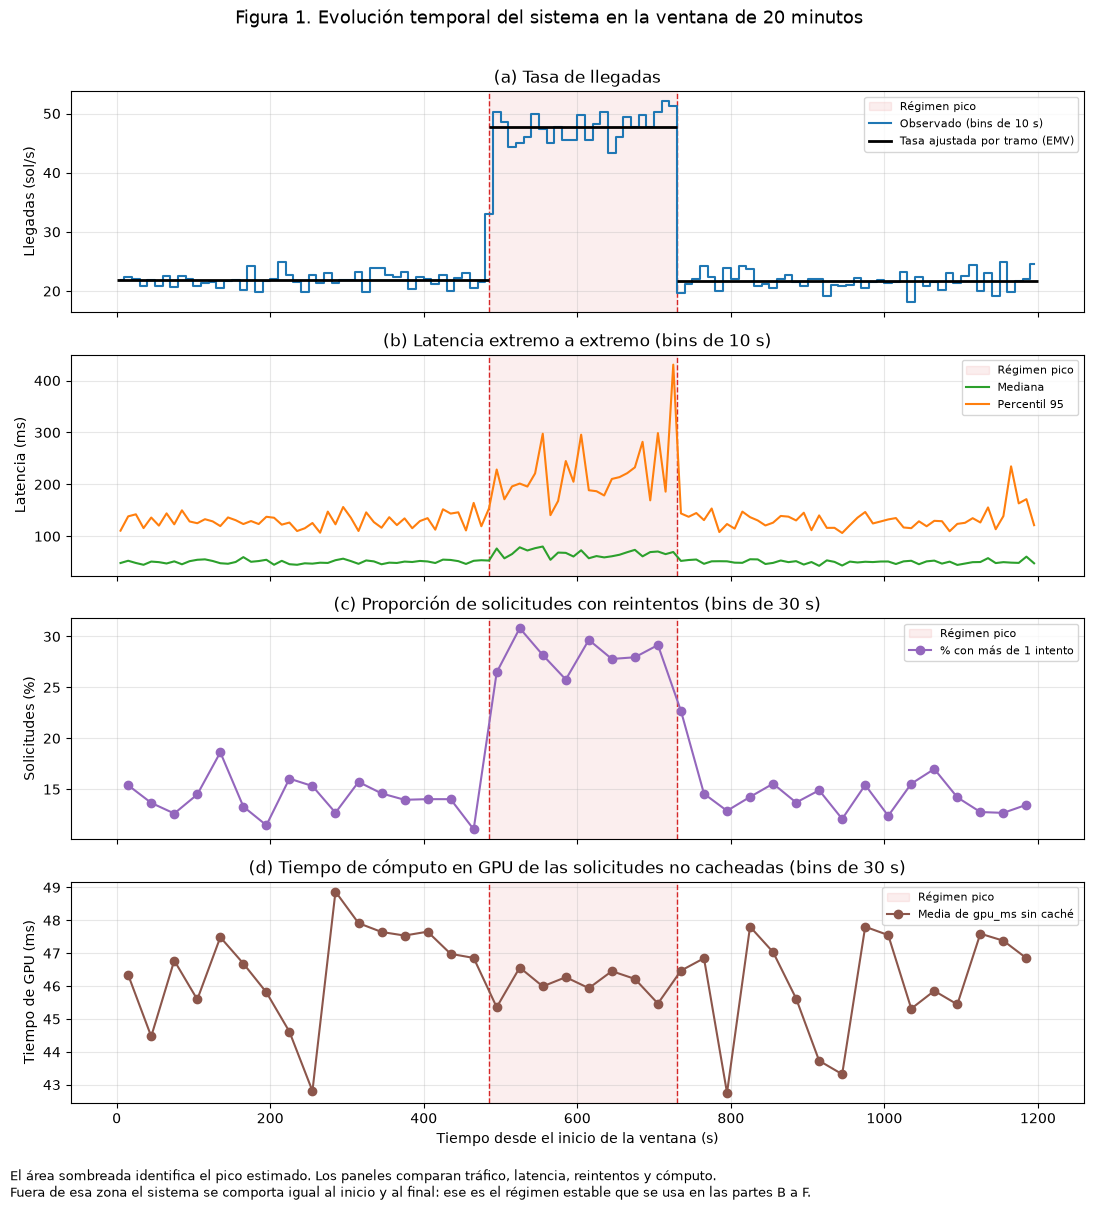

In [18]:
# Parte A · A2 — Figura 1: evolución temporal (tasa, latencia, reintentos y GPU)
# Figura 1: evolución temporal del sistema
ancho = 10
bordes = np.arange(0, T_VENTANA + 1e-9, ancho)
centros = bordes[:-1] + ancho / 2
tramo_bin = pd.cut(df.t_llegada_s, bordes, right=False)
g10 = df.groupby(tramo_bin, observed=False)
bordes30 = np.arange(0, T_VENTANA + 1e-9, 30)
centros30 = bordes30[:-1] + 15
g30 = df.groupby(pd.cut(df.t_llegada_s, bordes30, right=False), observed=False)
g30_nc = df[df.cache_hit == 0].groupby(pd.cut(df.loc[df.cache_hit == 0, "t_llegada_s"], bordes30, right=False), observed=False)

fig, ejes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
for ax in ejes:
    ax.axvspan(TAU1, TAU2, color="tab:red", alpha=0.08, label="Régimen pico")
    for c in (TAU1, TAU2):
        ax.axvline(c, color="tab:red", ls="--", lw=1)
    ax.grid(alpha=0.3)

ejes[0].step(centros, g10.size().to_numpy() / ancho, where="mid", color="tab:blue", label="Observado (bins de 10 s)")
for a, b, _ in SEGMENTOS:
    m = (t >= a) & (t < b)
    ejes[0].hlines(m.sum() / (b - a), a, b, color="black", lw=2)
ejes[0].plot([], [], color="black", lw=2, label="Tasa ajustada por tramo (EMV)")
ejes[0].set_ylabel("Llegadas (sol/s)")
ejes[0].set_title("(a) Tasa de llegadas")

ejes[1].plot(centros, g10.latencia_ms.median().to_numpy(), color="tab:green", label="Mediana")
ejes[1].plot(centros, g10.latencia_ms.quantile(0.95).to_numpy(), color="tab:orange", label="Percentil 95")
ejes[1].set_ylabel("Latencia (ms)")
ejes[1].set_title("(b) Latencia extremo a extremo (bins de 10 s)")

ejes[2].plot(centros30, 100 * g30.intentos.apply(lambda s: (s.dropna() > 1).mean()).to_numpy(), marker="o", color="tab:purple", label="% con más de 1 intento")
ejes[2].set_ylabel("Solicitudes (%)")
ejes[2].set_title("(c) Proporción de solicitudes con reintentos (bins de 30 s)")

ejes[3].plot(centros30, g30_nc.gpu_ms.mean().to_numpy(), marker="o", color="tab:brown", label="Media de gpu_ms sin caché")
ejes[3].set_ylabel("Tiempo de GPU (ms)")
ejes[3].set_title("(d) Tiempo de cómputo en GPU de las solicitudes no cacheadas (bins de 30 s)")
ejes[3].set_xlabel("Tiempo desde el inicio de la ventana (s)")

for ax in ejes:
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Figura 1. Evolución temporal del sistema en la ventana de 20 minutos", fontsize=13, y=0.995)
fig.text(0.01, 0.002,
         "El área sombreada identifica el pico estimado. Los paneles comparan tráfico, latencia, reintentos y cómputo.\n"
         "Fuera de esa zona el sistema se comporta igual al inicio y al final: ese es el régimen estable que se usa en las partes B a F.",
         fontsize=9, ha="left", va="bottom")
fig.tight_layout(rect=(0, 0.035, 1, 0.985))
plt.show()

✍️ *[Figura 1 — pie de figura: pegue aquí su texto]*

✍️ *[A2 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## A3 · Resumen descriptivo por versión y por régimen

✍️ *[A3 — planteamiento: pegue aquí su texto]*

In [19]:
# Parte A · A3 — Medidas descriptivas por variable, régimen y versión
# Cada medida usa los valores válidos de su propia columna, por eso los tamaños de muestra pueden diferir.
def describir(x):
    x = x.dropna()
    return pd.Series({"n": len(x), "media": x.mean(), "mediana": x.median(), "desv. est.": x.std(ddof=1),
                      "RIC": x.quantile(.75) - x.quantile(.25),
                      "asimetría": stats.skew(x), "curtosis (exceso)": stats.kurtosis(x)})

variables = {
    "latencia_ms": df.latencia_ms,
    "gpu_ms (todas)": df.gpu_ms,
    "gpu_ms (sin caché)": df.gpu_ms.where(df.cache_hit == 0),
    "red_ms": df.red_ms,
    "tam_kb": df.tam_kb,
}
filas = []
for nombre, serie in variables.items():
    for reg in ["estable", "pico"]:
        for ver in ["A", "B", "A+B"]:
            m = (df.regimen == reg) & ((df.version == ver) if ver != "A+B" else True)
            filas.append(describir(serie[m]).rename((nombre, reg, ver)))
tabla_A3 = pd.DataFrame(filas)
tabla_A3.index = pd.MultiIndex.from_tuples(tabla_A3.index, names=["variable", "régimen", "versión"])
tabla_A3["n"] = tabla_A3["n"].astype(int)
tabla_A3.round(2)

n   media  mediana  desv. est.     RIC  asimetría  curtosis (exceso)
variable           régimen versión                                                                          
latencia_ms        estable A        10377   58.99    51.02       39.28   51.18       1.60               4.01
                           B        10324   57.61    50.00       37.48   48.88       1.75               5.48
                           A+B      20701   58.30    50.46       38.39   50.02       1.67               4.69
                   pico    A         5784   87.18    68.56       73.25   94.58       1.67               3.97
                           B         5860   84.38    65.40       71.23   90.07       1.76               4.29
                           A+B      11644   85.77    66.94       72.25   92.86       1.72               4.13
gpu_ms (todas)     estable A        10428   32.39    25.30       35.63   48.76       1.72               5.02
                           B        10360   30.93    24.38       33.78   46.46       1.88               6.68
                           A+B      20788   31.67    24.86       34.73   47.60       1.80               5.79
                   pico    A         5804   32.68    25.57       36.04   49.70       1.84               6.28
                           B         5882   30.05    23.62       33.20   44.85       1.97               7.70
                           A+B      11686   31.36    24.52       34.66   46.96       1.91               6.95
gpu_ms (sin caché) estable A         7063   47.83    38.81       33.70   36.44       1.96               6.49
                           B         7150   44.82    36.67       32.11   34.38       2.20               8.84
                           A+B      14213   46.31    37.69       32.95   35.42       2.07               7.56
                   pico    A         3934   48.22    39.56       34.16   36.90       2.14               8.38
                           B         4025   43.92    35.77       31.65   32.51       2.32              10.30
                           A+B       7959   46.04    37.74       32.98   34.76       2.22               9.24
red_ms             estable A        10426   23.37    23.31        3.56    4.86       0.03              -0.09
                           B        10363   23.38    23.37        3.59    4.81       0.00               0.02
                           A+B      20789   23.38    23.34        3.57    4.83       0.02              -0.03
                   pico    A         5806   23.37    23.33        3.57    4.78      -0.01               0.03
                           B         5878   23.33    23.31        3.62    4.91      -0.02               0.02
                           A+B      11684   23.35    23.32        3.59    4.84      -0.02               0.03
tam_kb             estable A        10440  237.96   199.12      169.29  208.36       1.37               2.63
                           B        10373  243.75   203.20      175.32  213.45       1.43               2.82
                           A+B      20813  240.84   201.05      172.34  210.57       1.40               2.74
                   pico    A         5809  240.05   199.59      168.36  208.59       1.34               2.57
                           B         5884  240.82   203.59      168.95  208.14       1.37               2.86
                           A+B      11693  240.43   201.81      168.65  208.49       1.36               2.72

✍️ *[A3 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

# Parte B — Llegadas, fallos y reintentos

✍️ *[Parte B — introducción: pegue aquí su texto]*

In [20]:
# Parte B · Parámetros usados (vienen de la primera celda; aquí no se redefinen)
alpha_conf = alpha
k_max = kmax
print(f"tau = {tau} ms, eps = {eps:.2f}, nivel de confianza = {conf:.2f} (alpha = {alpha_conf:.2f})")
print(f"g = {g:.2f}, t1 = {t1} KB, t2 = {t2} KB, pi = {pi_prod:.4f}, k_max = {k_max}, r = {r}, N = {N}")

tau = 260 ms, eps = 0.03, nivel de confianza = 0.99 (alpha = 0.01)
g = 1.90, t1 = 90 KB, t2 = 425 KB, pi = 0.0090, k_max = 5, r = 5, N = 20


In [21]:
# Parte B · Datos depurados de la Parte A (copia en memoria) y régimen estable
df = df_limpio.copy()
df_est = df[df['regimen'] == 'estable'].copy()
print(f"Total de solicitudes en Régimen Estable: {len(df_est)}")

Total de solicitudes en Régimen Estable: 20813


## B1 · Modelo del proceso de llegadas

✍️ *[B1 — planteamiento: pegue aquí su texto]*

In [22]:
# Parte B · B1 — Tasa de llegadas por máxima verosimilitud, IC y dos vías de validación:
# (1) KS de los tiempos entre llegadas frente a la exponencial; (2) conteos por segundo frente a Poisson.
# Las diferencias de tiempo se calculan por tramo para excluir el hueco entre segmentos estables.
dt_list = []
for seg in ['estable_1', 'estable_2']:
    df_seg = df_est[df_est['segmento'] == seg].sort_values('t_llegada_s')
    dt = np.diff(df_seg['t_llegada_s'].values)
    dt_list.extend(dt[dt > 0])

dt_arr = np.array(dt_list)
n_dt = len(dt_arr)
mean_dt = np.mean(dt_arr)
lambda_hat = 1.0 / mean_dt

# Intervalo normal para la tasa de llegadas al nivel de confianza del grupo.
z_crit = stats.norm.ppf(1.0 - alpha_conf / 2.0)
se_lambda = lambda_hat / np.sqrt(n_dt)
ic_lambda = (lambda_hat - z_crit * se_lambda, lambda_hat + z_crit * se_lambda)

# Validación 1: Kolmogorov-Smirnov en tiempos entre llegadas vs Exponencial(lambda)
ks_stat, ks_pval = stats.kstest(dt_arr, 'expon', args=(0, mean_dt))

# Validación 2: Conteos en intervalos de 1 s vs Poisson(lambda * 1s)
counts_1s = []
for seg in ['estable_1', 'estable_2']:
    df_seg = df_est[df_est['segmento'] == seg]
    bins = np.arange(np.floor(df_seg['t_llegada_s'].min()), np.ceil(df_seg['t_llegada_s'].max()), 1.0)
    c, _ = np.histogram(df_seg['t_llegada_s'], bins=bins)
    counts_1s.extend(c)
counts_1s = np.array(counts_1s)
mean_c = np.mean(counts_1s)
var_c = np.var(counts_1s, ddof=1)
disp_index = var_c / mean_c

# Test Chi-cuadrado en conteos
obs_counts, bin_edges = np.histogram(counts_1s, bins=np.arange(0, int(np.percentile(counts_1s, 99.5)) + 2))
exp_probs = stats.poisson.pmf(bin_edges[:-1], mean_c)
exp_probs[-1] += 1.0 - np.sum(exp_probs)
exp_counts = exp_probs * len(counts_1s)
valid_mask = exp_counts >= 5
chi2_stat = np.sum((obs_counts[valid_mask] - exp_counts[valid_mask])**2 / exp_counts[valid_mask])
dof = np.sum(valid_mask) - 1 - 1
chi2_pval = 1.0 - stats.chi2.cdf(chi2_stat, dof)

print(f"Estimación puntual lambda = {lambda_hat:.4f} sol/s")
print(f"IC al {int(conf*100)}%: [{ic_lambda[0]:.4f}, {ic_lambda[1]:.4f}] sol/s")
print(f"Vía 1 - Test KS en delta_t: D = {ks_stat:.4f}, p-valor = {ks_pval:.4f} ")
print(f"Vía 2 - Conteos en 1s: media = {mean_c:.3f}, var = {var_c:.3f}, índice de dispersión = {disp_index:.3f}")
print(f"        Test Chi2: stat = {chi2_stat:.2f}, gl = {dof}, p-valor = {chi2_pval:.4f} ")

# KS con estimación repetida de la tasa dentro de cada réplica.
ma = 599
d_boot = np.empty(ma)
for j in range(ma):
    x_b1 = np.sort(rng.exponential(mean_dt,n_dt))
    F_b1 = stats.expon.cdf(x_b1,scale=x_b1.mean())
    d_boot[j] = max(np.max(np.arange(1,n_dt+1)/n_dt-F_b1),np.max(F_b1-np.arange(n_dt)/n_dt))
p_ks_b1 = (1+(d_boot>=ks_stat).sum())/(ma+1)
# Dispersión de conteos con sus intervalos temporales completos, sin cruzar el pico.
conteos_b1 = np.concatenate([np.histogram(tramo.t_llegada_s, bins=np.arange(np.ceil(a), np.floor(fin)+1))[0]
                            for a,fin,nom in SEGMENTOS if nom!="pico" for tramo in [df[df.segmento==nom]]])
dis_b1 = (len(conteos_b1)-1)*conteos_b1.var(ddof=1)/conteos_b1.mean()
p_dis_b1 = min(1,2*min(stats.chi2.cdf(dis_b1,len(conteos_b1)-1),stats.chi2.sf(dis_b1,len(conteos_b1)-1)))
print(f"KS calibrado (MC): p={p_ks_b1:.4f} | dispersión Poisson bilateral: p={p_dis_b1:.4f}")
print(f"Conclusión B1 (calculada): KS calibrado p = {p_ks_b1:.3f} "
      f"({'no rechaza' if p_ks_b1 > alpha else 'rechaza'} la exponencial al {alpha:.0%}); "
      f"dispersión bilateral p = {p_dis_b1:.4f} ({'no rechaza' if p_dis_b1 > alpha else 'rechaza'} Poisson al {alpha:.0%}).")

Estimación puntual lambda = 21.7681 sol/s
IC al 99%: [21.3792, 22.1571] sol/s
Vía 1 - Test KS en delta_t: D = 0.0056, p-valor = 0.5350 
Vía 2 - Conteos en 1s: media = 21.787, var = 19.712, índice de dispersión = 0.905
        Test Chi2: stat = 29.65, gl = 21, p-valor = 0.0993 


KS calibrado (MC): p=0.3233 | dispersión Poisson bilateral: p=0.0313
Conclusión B1 (calculada): KS calibrado p = 0.323 (no rechaza la exponencial al 1%); dispersión bilateral p = 0.0313 (no rechaza Poisson al 1%).


✍️ *[B1 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## B2 · Solicitudes con más de un intento por bloque de 100

✍️ *[B2 — planteamiento: pegue aquí su texto]*

In [23]:
# Parte B · B2 — Bloques consecutivos de 100 solicitudes dentro de cada tramo; X = nº con reintento.
# Se compara la varianza observada con la binomial y se calcula un valor p por Monte Carlo.
# Los grupos de cien se forman dentro de un mismo tramo para no mezclar condiciones de tráfico.
bloques = {}
filas_b2 = []
for reg, d in df.groupby("regimen"):
    grupos = []
    for _, tramo in d.groupby("segmento", sort=False):
        valores = tramo.intentos.to_numpy()
        completos = valores[:len(valores)//100*100].reshape(-1,100)
        completos = completos[~np.isnan(completos).any(axis=1)]
        grupos.extend((completos>1).sum(axis=1))
    x_b = np.asarray(grupos)
    bloques[reg] = x_b
    pb = x_b.mean()/100
    esperada = 100*pb*(1-pb)
    simulados = rng.binomial(100,pb,(4000,len(x_b)))
    pboot = simulados.mean(axis=1)/100
    obs = x_b.var(ddof=1)/esperada
    dispersion = simulados.var(axis=1,ddof=1)/(100*pboot*(1-pboot))
    p_b2 = (1+np.sum(abs(dispersion-1)>=abs(obs-1)))/(len(dispersion)+1)
    filas_b2.append((reg,len(x_b),pb,x_b.var(ddof=1),esperada,p_b2))
tabla_b2 = pd.DataFrame(filas_b2,columns=["régimen","bloques","p","var observada","var binomial","p MC"])
display(tabla_b2)
for _, fila in tabla_b2.iterrows():
    print(f"Conclusión B2 (calculada) [{fila['régimen']}]: p = {fila['p']:.4f}, var/var binomial = "
          f"{fila['var observada']/fila['var binomial']:.3f}, p MC = {fila['p MC']:.3f} -> "
          f"{'compatible con binomial' if fila['p MC'] > alpha else 'sobredispersión'} al {alpha:.0%}")

,régimen,bloques,p,var observada,var binomial,p MC
0,estable,208,0.141587,14.076157,12.153979,0.111472
1,pico,116,0.283793,19.837481,20.325458,0.866533


Conclusión B2 (calculada) [estable]: p = 0.1416, var/var binomial = 1.158, p MC = 0.111 -> compatible con binomial al 1%
Conclusión B2 (calculada) [pico]: p = 0.2838, var/var binomial = 0.976, p MC = 0.867 -> compatible con binomial al 1%


✍️ *[B2 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## B3 · Estimador de máxima verosimilitud de la variable intentos

✍️ *[B3 — planteamiento: pegue aquí su texto]*

✍️ *[B3 — deducción a mano (E3): pegue aquí su texto]*

In [24]:
# Parte B · B3 — EMV de p (fallo por intento) con K en {1,2,3}; IC con información de Fisher
# y simulación calibrada para comparar el EMV con el estimador por momentos.
k_vals = df_est['intentos'].dropna().values
n1 = np.sum(k_vals == 1)
n2 = np.sum(k_vals == 2)
n3 = np.sum(k_vals == 3)
n_tot = n1 + n2 + n3

# Llegar al tercer intento revela dos fallos previos. El conteo de intentos por sí solo no revela cómo terminó el tercero.
p_mle = (n2 + 2 * n3) / (n1 + 2 * n2 + 2 * n3)
info_fisher = (n2 + 2 * n3) / (p_mle**2) + (n1 + n2) / ((1.0 - p_mle)**2)
se_p = 1.0 / np.sqrt(info_fisher)
ic_p = (p_mle - z_crit * se_p, p_mle + z_crit * se_p)

# Simulación calibrada frente al promedio simple (B=10000 réplicas)
B_sim = 10_000
prob_geom = [1.0 - p_mle, p_mle * (1.0 - p_mle), p_mle**2]
sim_k = rng.choice([1, 2, 3], size=(B_sim, n_tot), p=prob_geom)

sn1 = np.sum(sim_k == 1, axis=1)
sn2 = np.sum(sim_k == 2, axis=1)
sn3 = np.sum(sim_k == 3, axis=1)
sim_mle = (sn2 + 2 * sn3) / (sn1 + 2 * sn2 + 2 * sn3)

skbar = (sn1 + 2 * sn2 + 3 * sn3) / n_tot
sim_mom = (-1.0 + np.sqrt(np.maximum(0.0, 1.0 - 4.0 * (1.0 - skbar)))) / 2.0

print(f"Conteos observados: n1={n1}, n2={n2}, n3={n3} (Total={n_tot})")
print(f"p_MLE = {p_mle:.5f} (SE = {se_p:.5f})")
print(f"IC al {int(conf*100)}%: [{ic_p[0]:.5f}, {ic_p[1]:.5f}]")
print(f"Simulación Calibrada ({B_sim} réplicas):")
print(f"  MLE:      Sesgo = {np.mean(sim_mle) - p_mle:.2e}, MSE = {np.mean((sim_mle - p_mle)**2):.2e}")
print(f"  Momentos: Sesgo = {np.mean(sim_mom) - p_mle:.2e}, MSE = {np.mean((sim_mom - p_mle)**2):.2e}")
print(f"  Eficiencia Relativa Var(MLE)/Var(Mom) = {np.var(sim_mle, ddof=1)/np.var(sim_mom, ddof=1):.4f}")

Conteos observados: n1=17867, n2=2502, n3=444 (Total=20813)
p_MLE = 0.14268 (SE = 0.00227)
IC al 99%: [0.13684, 0.14853]
Simulación Calibrada (10000 réplicas):
  MLE:      Sesgo = -3.38e-05, MSE = 5.07e-06
  Momentos: Sesgo = -3.32e-05, MSE = 5.08e-06
  Eficiencia Relativa Var(MLE)/Var(Mom) = 0.9994


✍️ *[B3 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## B4 · Probabilidad de al menos k solicitudes con reintento en 10 s

✍️ *[B4 — planteamiento: pegue aquí su texto]*

In [25]:
# Parte B · B4 — Adelgazamiento de Poisson: Z ~ Poisson(10·λ̂·p̂) y k = ⌈μ̂⌉ + r.
# Se verifica con Monte Carlo y se reporta su error estándar (EE) en lugar de una cota fija.
mu_hat = 10.0 * lambda_hat * p_mle
k_val = int(np.ceil(mu_hat) + r)  # desplazamiento calculado con S (r = 5)

# Probabilidad analítica
# La cola P(Z ≥ k) se calcula como 1 − F(k − 1), que incluye el conteo k.
prob_analitica = 1.0 - stats.poisson.cdf(k_val - 1, mu_hat)

# Simulación de Montecarlo (200 000 réplicas)
n_mc = 200_000
sol_10s = rng.poisson(10.0 * lambda_hat, size=n_mc)
fallos_10s = rng.binomial(sol_10s, p_mle)
prob_mc = np.mean(fallos_10s >= k_val)

# Error estándar Monte Carlo e intervalo al nivel conf
ee_mc = np.sqrt(prob_mc * (1 - prob_mc) / n_mc)
ic_mc = (prob_mc - z_crit * ee_mc, prob_mc + z_crit * ee_mc)
dif_b4 = abs(prob_analitica - prob_mc)

print(f"mu_hat = {mu_hat:.4f}")
print(f"Parámetro r = {r} -> Umbral k = {k_val}")
print(f"Probabilidad Analítica P(Z >= {k_val}) = {prob_analitica:.5f}")
print(f"Probabilidad Monte Carlo P(Z >= {k_val}) = {prob_mc:.5f}  (EE MC = {ee_mc:.5f})")
print(f"IC {conf:.0%} Monte Carlo: [{ic_mc[0]:.5f}, {ic_mc[1]:.5f}]")
print(f"Discrepancia absoluta = {dif_b4:.5f} = {dif_b4/ee_mc:.2f} EE MC -> "
      f"{'compatible' if dif_b4 <= z_crit*ee_mc else 'NO compatible'} con el valor analítico (umbral {z_crit:.3f} EE)")

mu_hat = 31.0594
Parámetro r = 5 -> Umbral k = 37
Probabilidad Analítica P(Z >= 37) = 0.16384
Probabilidad Monte Carlo P(Z >= 37) = 0.16506  (EE MC = 0.00083)
IC 99% Monte Carlo: [0.16292, 0.16719]
Discrepancia absoluta = 0.00122 = 1.47 EE MC -> compatible con el valor analítico (umbral 2.576 EE)


✍️ *[B4 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

# Parte C — Tiempo de cómputo y tiempo de red

✍️ *[Parte C — introducción: pegue aquí su texto]*

In [26]:
# Parte C · Parámetros (vienen de la primera celda; aquí solo se comprueban)
S_GRUPO = S
ES_BORRADOR = False
assert (tau, eps, conf, t1, t2, kmax, r, N) == (260, 0.03, 0.99, 90, 425, 5, 5, 20)

In [27]:
# Parte C · Datos en memoria y funciones compartidas (IC de Wilson, IC t, hessiano numérico)
import json
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize, special

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)
z_conf = stats.norm.ppf(1 - alpha / 2)

df_estable = df_limpio[df_limpio.regimen == "estable"].copy()   # régimen estable (Parte A)
df_reg1, df_reg2 = df_estable, df_limpio[df_limpio.regimen == "pico"].copy()
params = {}                                                       # parámetros de entrada del simulador de G
print("Régimen estable:", len(df_estable), "solicitudes")

# ---------- funciones compartidas ----------
def ic_wilson(x, n, conf=conf):
    # Intervalo de Wilson para una proporción x/n
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    p = x / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    semi = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return p, centro - semi, centro + semi

def ic_media(x, conf=conf):
    # Intervalo t de Student para la media
    x = np.asarray(x, float)
    n = len(x); m = x.mean(); ee = x.std(ddof=1) / np.sqrt(n)
    q = stats.t.ppf(1 - (1 - conf) / 2, n - 1)
    return m, m - q * ee, m + q * ee

def hessiano_numerico(f, x0, paso=1e-4):
    # Hessiano por diferencias finitas centrales (para los errores estándar de los EMV)
    x0 = np.asarray(x0, float); d = len(x0); H = np.zeros((d, d))
    h = paso * np.maximum(np.abs(x0), 1.0)
    for i in range(d):
        for j in range(d):
            ei = np.zeros(d); ej = np.zeros(d); ei[i] = h[i]; ej[j] = h[j]
            H[i, j] = (f(x0 + ei + ej) - f(x0 + ei - ej) - f(x0 - ei + ej) + f(x0 - ei - ej)) / (4 * h[i] * h[j])
    return H

def txt_ic(est, lo, hi, dec=3):
    return f"{est:.{dec}f}  [{lo:.{dec}f}, {hi:.{dec}f}]"

Régimen estable: 20813 solicitudes


## C1 · Distribución de G considerando todas las solicitudes

✍️ *[C1 — planteamiento: pegue aquí su texto]*

✍️ *[C1 — deducción a mano (E3): pegue aquí su texto]*

In [28]:
# Parte C · C1 — h = P(G = 0) (caché) con IC de Wilson y descripción de la parte continua G_c
# h = P(caché) y la parte continua G_c (solo filas con caché y GPU válidos)
# Los aciertos de caché aportan masa en cero; la muestra positiva determina el tiempo condicional de GPU.
validas = df_estable.dropna(subset=["cache_hit", "gpu_ms"])
assert ((validas.gpu_ms == 0) == (validas.cache_hit == 1)).all()   # G = 0 exactamente cuando hay caché
G_todas = validas.gpu_ms.to_numpy()
G_c = validas.loc[validas.cache_hit == 0, "gpu_ms"].to_numpy()
n_validas, n_cache = len(validas), int((validas.cache_hit == 1).sum())
h_hat, h_lo, h_hi = ic_wilson(n_cache, n_validas)
print(f"n = {n_validas} | caché = {n_cache}")
print(f"h = P(G = 0) = {txt_ic(h_hat, h_lo, h_hi, 4)}  (Wilson, {conf:.0%})")
print(f"Parte continua: n = {len(G_c)}, media = {G_c.mean():.3f} ms, varianza = {G_c.var(ddof=1):.2f}, "
      f"asimetría = {stats.skew(G_c):.3f}, curtosis = {stats.kurtosis(G_c):.3f}")
params["h"] = {"est": h_hat, "ic": [h_lo, h_hi], "metodo": "Wilson"}

n = 20788 | caché = 6575
h = P(G = 0) = 0.3163  [0.3080, 0.3247]  (Wilson, 99%)
Parte continua: n = 14213, media = 46.315 ms, varianza = 1085.46, asimetría = 2.072, curtosis = 7.558


✍️ *[C1 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## C2 · Máxima verosimilitud para la parte continua de G

✍️ *[C2 — planteamiento: pegue aquí su texto]*

In [29]:
# Parte C · C2 — EMV programado a mano (Gamma y Lognormal) y comparación con el método de momentos
# La minimización de la log-verosimilitud negativa produce las estimaciones de máxima verosimilitud.
def nll_gamma(par, x):
    k, th = par
    if k <= 0 or th <= 0:
        return np.inf
    n = len(x)
    return -((k - 1) * np.log(x).sum() - x.sum() / th - n * k * np.log(th) - n * special.gammaln(k))

def nll_lognorm(par, x):
    mu, s = par
    if s <= 0:
        return np.inf
    lx = np.log(x)
    return -(-lx.sum() - len(x) * np.log(s * np.sqrt(2 * np.pi)) - ((lx - mu) ** 2).sum() / (2 * s**2))

def ajustar_emv(nll, x, inicio, positivos):
    # La máscara positivos identifica los parámetros optimizados en escala logarítmica.
    positivos = np.asarray(positivos)
    def a_natural(u):
        u = np.array(u, float); u[positivos] = np.exp(u[positivos]); return u
    u0 = np.array(inicio, float); u0[positivos] = np.log(u0[positivos])
    res = optimize.minimize(lambda u: nll(a_natural(u), x), u0, method="Nelder-Mead",
                            options={"xatol": 1e-9, "fatol": 1e-9, "maxiter": 20000})
    est = a_natural(res.x)
    H = hessiano_numerico(lambda p: nll(p, x), est)
    ee = np.sqrt(np.diag(np.linalg.inv(H)))
    return est, ee, -res.fun

m_c, v_c = G_c.mean(), G_c.var(ddof=1)
# Estimación por el método de momentos a partir de la media y la varianza muestrales.
k_mm, th_mm = m_c**2 / v_c, v_c / m_c
s_mm = np.sqrt(np.log(1 + v_c / m_c**2)); mu_mm = np.log(m_c) - s_mm**2 / 2

(k_mv, th_mv), ee_gam, ll_gam = ajustar_emv(nll_gamma, G_c, [k_mm, th_mm], [True, True])
(mu_mv, s_mv), ee_ln, ll_ln = ajustar_emv(nll_lognorm, G_c, [mu_mm, s_mm], [False, True])

tabla_C2 = pd.DataFrame({
    "parámetro": ["Gamma k", "Gamma θ (ms)", "Lognormal μ", "Lognormal s"],
    "EMV": [k_mv, th_mv, mu_mv, s_mv],
    f"IC {conf:.0%} inf": [k_mv - z_conf * ee_gam[0], th_mv - z_conf * ee_gam[1], mu_mv - z_conf * ee_ln[0], s_mv - z_conf * ee_ln[1]],
    f"IC {conf:.0%} sup": [k_mv + z_conf * ee_gam[0], th_mv + z_conf * ee_gam[1], mu_mv + z_conf * ee_ln[0], s_mv + z_conf * ee_ln[1]],
    "Momentos": [k_mm, th_mm, mu_mm, s_mm],
})
print("Verificación (solo para comprobar el EMV propio): scipy.gamma.fit =", np.round(stats.gamma.fit(G_c, floc=0)[::2], 4))
print(f"AIC Gamma = {2*2 - 2*ll_gam:.1f} | AIC Lognormal = {2*2 - 2*ll_ln:.1f}  (menor es mejor)")
tabla_C2.round(4)

Verificación (solo para comprobar el EMV propio): scipy.gamma.fit = [ 2.4162 19.1686]
AIC Gamma = 132485.1 | AIC Lognormal = 132036.2  (menor es mejor)


,parámetro,EMV,IC 99% inf,IC 99% sup,Momentos
0,Gamma k,2.4162,2.3468,2.4855,1.9762
1,Gamma θ (ms),19.1686,18.5574,19.7798,23.4366
2,Lognormal μ,3.6145,3.5998,3.6291,3.6307
3,Lognormal s,0.6780,0.6676,0.6883,0.6399


In [30]:
# Parte C · C2 — Bondad de ajuste: KS con bootstrap paramétrico y chi-cuadrado con bins equiprobables
# Bondad de ajuste numérica
def ks_estadistico(x, cdf):
    x = np.sort(x); n = len(x); F = cdf(x)
    return max((np.arange(1, n + 1) / n - F).max(), (F - np.arange(0, n) / n).max())

cdf_gam = lambda x: stats.gamma.cdf(x, k_mv, scale=th_mv)
cdf_ln = lambda x: stats.lognorm.cdf(x, s_mv, scale=np.exp(mu_mv))
D_gam, D_ln = ks_estadistico(G_c, cdf_gam), ks_estadistico(G_c, cdf_ln)

# Valor p de Kolmogórov–Smirnov por bootstrap paramétrico.
# Cada réplica vuelve a ajustar los parámetros para reproducir el procedimiento aplicado a la muestra.
B_KS = 200
D_boot = np.empty(B_KS)
for b in range(B_KS):
    xb = rng.gamma(k_mv, th_mv, size=len(G_c))
    (kb, thb), _, _ = ajustar_emv(nll_gamma, xb, [k_mv, th_mv], [True, True])
    D_boot[b] = ks_estadistico(xb, lambda x: stats.gamma.cdf(x, kb, scale=thb))
p_ks_gam = (1 + (D_boot >= D_gam).sum()) / (B_KS + 1)

# Chi-cuadrado con 20 bins equiprobables bajo el modelo Gamma
bordes = stats.gamma.ppf(np.linspace(0, 1, 21), k_mv, scale=th_mv)
obs = np.histogram(G_c, bins=bordes)[0]
esp = np.full(20, len(G_c) / 20)
chi2_gam = ((obs - esp) ** 2 / esp).sum()
p_chi2_gam = stats.chi2.sf(chi2_gam, 20 - 1 - 2)

print(f"KS Gamma: D = {D_gam:.4f}, p (bootstrap paramétrico, B={B_KS}) = {p_ks_gam:.3f}")
print(f"KS Lognormal: D = {D_ln:.4f}")
print(f"Chi-cuadrado Gamma (20 bins): {chi2_gam:.1f}, gl = 17, p = {p_chi2_gam:.4f}")
print(f"Varianza: muestral = {v_c:.1f} | Gamma EMV = {k_mv*th_mv**2:.1f} | Gamma momentos = {k_mm*th_mm**2:.1f}")

KS Gamma: D = 0.0387, p (bootstrap paramétrico, B=200) = 0.005
KS Lognormal: D = 0.0113
Chi-cuadrado Gamma (20 bins): 317.0, gl = 17, p = 0.0000
Varianza: muestral = 1085.5 | Gamma EMV = 887.8 | Gamma momentos = 1085.5


In [31]:
# Parte C · C2 — Crítica del modelo marginal: Gamma condicionada al tamaño de la imagen
cond = validas[(validas.cache_hit == 0) & validas.tam_kb.notna()]
x_c, y_c = cond.tam_kb.to_numpy(), cond.gpu_ms.to_numpy()

def nll_gamma_cond(par, x, y):
    b0, b1, kap = par
    mu = b0 + b1 * x
    if kap <= 0 or np.any(mu <= 0):
        return np.inf
    return -(len(y) * (kap * np.log(kap) - special.gammaln(kap)) + ((kap - 1) * np.log(y) - kap * np.log(mu) - kap * y / mu).sum())

u0 = np.array([np.mean(y_c), 0.0, np.log(k_mv)])
res = optimize.minimize(lambda u: nll_gamma_cond([u[0], u[1], np.exp(u[2])], x_c, y_c), u0, method="Nelder-Mead",
                        options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 40000})
b0_g, b1_g, kap_g = res.x[0], res.x[1], np.exp(res.x[2])
H = hessiano_numerico(lambda p: nll_gamma_cond(p, x_c, y_c), [b0_g, b1_g, kap_g])
ee_cond = np.sqrt(np.diag(np.linalg.inv(H)))

# Marginal implicada por el modelo condicional: F(y) = promedio de las CDF Gamma de cada imagen
mu_i = b0_g + b1_g * x_c
rej = np.sort(y_c)
F_mezcla = np.array([stats.gamma.cdf(v, kap_g, scale=mu_i / kap_g).mean() for v in rej[::10]])
F_emp = np.arange(1, len(rej) + 1)[::10] / len(rej)
D_mezcla = np.abs(F_emp - F_mezcla).max()
var_mezcla = (mu_i**2 / kap_g).mean() + mu_i.var()

print(f"Modelo condicional (EMV): β0 = {b0_g:.3f} ± {ee_cond[0]:.3f}, β1 = {b1_g:.5f} ± {ee_cond[1]:.5f} ms/KB, κ = {kap_g:.3f} ± {ee_cond[2]:.3f}")
print(f"Coeficiente de variación implicado 1/√κ = {1/np.sqrt(kap_g):.3f}")
print(f"Distancia KS a los datos: una sola Gamma = {D_gam:.4f} | mezcla condicional ≈ {D_mezcla:.4f}")
print(f"Varianza: datos = {np.var(y_c, ddof=1):.1f} | una sola Gamma = {k_mv*th_mv**2:.1f} | mezcla condicional = {var_mezcla:.1f}")
params["G_dist"] = "gamma"
params["G_par"] = {"k": k_mv, "theta": th_mv, "ic_k": [k_mv - z_conf*ee_gam[0], k_mv + z_conf*ee_gam[0]],
                   "ic_theta": [th_mv - z_conf*ee_gam[1], th_mv + z_conf*ee_gam[1]], "metodo": "EMV propio"}
params["G_cond"] = {"b0": b0_g, "b1": b1_g, "kappa": kap_g, "ee": list(ee_cond),
                    "uso": "G | tam, no caché ~ Gamma(kappa, scale=(b0+b1*tam)/kappa)"}

Modelo condicional (EMV): β0 = 15.908 ± 0.246, β1 = 0.11634 ± 0.00130 ms/KB, κ = 3.997 ± 0.046
Coeficiente de variación implicado 1/√κ = 0.500
Distancia KS a los datos: una sola Gamma = 0.0387 | mezcla condicional ≈ 0.0058
Varianza: datos = 1085.5 | una sola Gamma = 887.8 | mezcla condicional = 1079.7


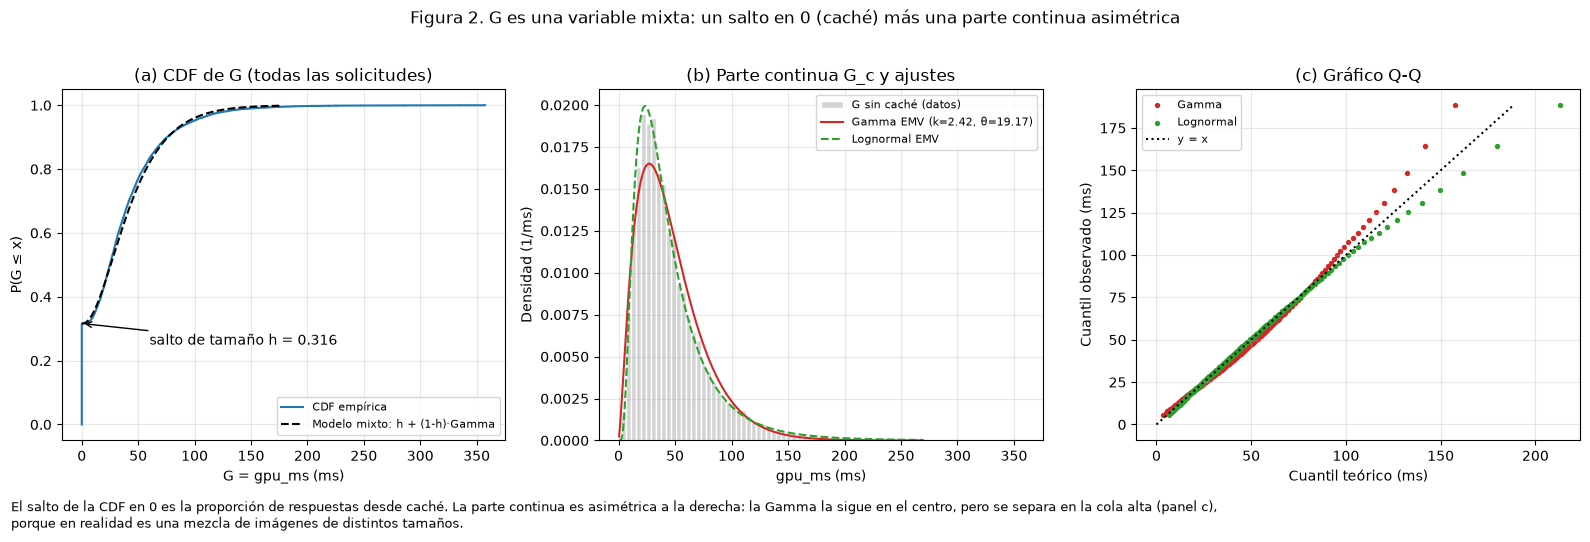

In [32]:
# Parte C · C1/C2 — Figura 2: CDF mixta, densidades ajustadas y gráfico Q-Q
# Figura 2: distribución de G
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
xs = np.linspace(0, np.quantile(G_todas, 0.995), 600)
ecdf_x = np.sort(G_todas); ecdf_y = np.arange(1, len(ecdf_x) + 1) / len(ecdf_x)
ax[0].step(ecdf_x, ecdf_y, where="post", color="tab:blue", label="CDF empírica")
ax[0].plot(xs, h_hat + (1 - h_hat) * stats.gamma.cdf(xs, k_mv, scale=th_mv), "k--", label="Modelo mixto: h + (1-h)·Gamma")
ax[0].annotate(f"salto de tamaño h = {h_hat:.3f}", xy=(0, h_hat), xytext=(60, 0.25), arrowprops=dict(arrowstyle="->"))
ax[0].set(title="(a) CDF de G (todas las solicitudes)", xlabel="G = gpu_ms (ms)", ylabel="P(G ≤ x)")
ax[1].hist(G_c, bins=80, density=True, color="lightgray", edgecolor="white", label="G sin caché (datos)")
xs2 = np.linspace(0.5, np.quantile(G_c, 0.999), 600)
ax[1].plot(xs2, stats.gamma.pdf(xs2, k_mv, scale=th_mv), "tab:red", label=f"Gamma EMV (k={k_mv:.2f}, θ={th_mv:.2f})")
ax[1].plot(xs2, stats.lognorm.pdf(xs2, s_mv, scale=np.exp(mu_mv)), "tab:green", ls="--", label="Lognormal EMV")
ax[1].set(title="(b) Parte continua G_c y ajustes", xlabel="gpu_ms (ms)", ylabel="Densidad (1/ms)")
qs = np.linspace(0.005, 0.995, 199)
ax[2].scatter(stats.gamma.ppf(qs, k_mv, scale=th_mv), np.quantile(G_c, qs), s=8, color="tab:red", label="Gamma")
ax[2].scatter(stats.lognorm.ppf(qs, s_mv, scale=np.exp(mu_mv)), np.quantile(G_c, qs), s=8, color="tab:green", label="Lognormal")
lim = [0, np.quantile(G_c, 0.995)]
ax[2].plot(lim, lim, "k:", label="y = x")
ax[2].set(title="(c) Gráfico Q-Q", xlabel="Cuantil teórico (ms)", ylabel="Cuantil observado (ms)")
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=0.3)
fig.suptitle("Figura 2. G es una variable mixta: un salto en 0 (caché) más una parte continua asimétrica", y=1.02)
fig.text(0.01, -0.06, "El salto de la CDF en 0 es la proporción de respuestas desde caché. La parte continua es asimétrica a la derecha: la Gamma la sigue "
         "en el centro, pero se separa en la cola alta (panel c),\nporque en realidad es una mezcla de imágenes de distintos tamaños.", fontsize=9)
fig.tight_layout()
plt.show()

✍️ *[Figura 2 — pie de figura: pegue aquí su texto]*

In [33]:
# Parte C · C1 — E[G] y Var(G): fórmula del modelo mixto frente a la muestra
# C1: E[G] y Var(G), modelo frente a muestra
# La variación total incluye tanto las diferencias entre tiempos positivos como el salto entre usar caché y usar GPU.
def momentos_G(h, mu_c, var_c):
    return (1 - h) * mu_c, (1 - h) * var_c + h * (1 - h) * mu_c**2

E_mv, V_mv = momentos_G(h_hat, k_mv * th_mv, k_mv * th_mv**2)
E_mm, V_mm = momentos_G(h_hat, k_mm * th_mm, k_mm * th_mm**2)
EG, EG_lo, EG_hi = ic_media(G_todas)
pd.DataFrame({
    "E[G] (ms)": [EG, E_mv, E_mm],
    "Var(G) (ms²)": [G_todas.var(ddof=1), V_mv, V_mm],
}, index=[f"Muestra (IC {conf:.0%} de la media: {EG_lo:.2f} a {EG_hi:.2f})", "Fórmula con Gamma EMV", "Fórmula con Gamma momentos"]).round(2)

,E[G] (ms),Var(G) (ms²)
Muestra (IC 99% de la media: 31.05 a 32.29),31.67,1206.02
Fórmula con Gamma EMV,31.67,1070.86
Fórmula con Gamma momentos,31.67,1206.01


✍️ *[C2 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## C3 · ¿El tiempo de red es normal?

✍️ *[C3 — planteamiento: pegue aquí su texto]*

In [34]:
# Parte C · C3 — Tres criterios de normalidad para red_ms
red = df_estable.red_ms.dropna().to_numpy()
n_red = len(red)
m_r, s_r = red.mean(), red.std(ddof=1)
print(f"n = {n_red} | media = {m_r:.3f} | desv = {s_r:.3f} | asimetría = {stats.skew(red):.3f} | curtosis exceso = {stats.kurtosis(red):.3f} | mínimo = {red.min():.2f}")
print("Criterio 1, D'Agostino-Pearson (asimetría + curtosis):", stats.normaltest(red))
print("Criterio 2, Jarque-Bera:", stats.jarque_bera(red))
import warnings
with warnings.catch_warnings():                       # Tratamiento local de la advertencia de versión de SciPy.
    warnings.simplefilter("ignore", FutureWarning)
    ad = stats.anderson(red, dist="norm")
print(f"Criterio 3, Anderson-Darling: A² = {ad.statistic:.2f} (valor crítico al 1 %: {ad.critical_values[-1]:.3f})")

n = 20789 | media = 23.376 | desv = 3.575 | asimetría = 0.018 | curtosis exceso = -0.034 | mínimo = 8.29
Criterio 1, D'Agostino-Pearson (asimetría + curtosis): NormaltestResult(statistic=np.float64(2.1105077718098926), pvalue=np.float64(0.3481040373776488))
Criterio 2, Jarque-Bera: SignificanceResult(statistic=np.float64(2.124471879707706), pvalue=np.float64(0.3456820213713023))
Criterio 3, Anderson-Darling: A² = 0.54 (valor crítico al 1 %: 1.035)


In [35]:
# Parte C · C3 — Alternativa: Gamma desplazada (EMV propio de 3 parámetros)
# Alternativa: Gamma desplazada, red = loc + Gamma(k, θ), con un piso mínimo de red. EMV propio de 3 parámetros.
def nll_gamma_desp(par, x):
    loc, k, th = par
    if k <= 0 or th <= 0 or loc >= x.min():
        return np.inf
    z = x - loc
    return -((k - 1) * np.log(z).sum() - z.sum() / th - len(x) * (k * np.log(th) + special.gammaln(k)))

gam_r = stats.skew(red)
k0 = 4 / gam_r**2; th0 = s_r / np.sqrt(k0); loc0 = min(m_r - k0 * th0, red.min() - 0.5)
u0 = [np.log(red.min() - loc0), np.log(k0), np.log(th0)]
a_nat = lambda u: [red.min() - np.exp(u[0]), np.exp(u[1]), np.exp(u[2])]
res = optimize.minimize(lambda u: nll_gamma_desp(a_nat(u), red), u0, method="Nelder-Mead",
                        options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 40000})
loc_r, k_r, th_r = a_nat(res.x)
H_r = hessiano_numerico(lambda p: nll_gamma_desp(p, red), [loc_r, k_r, th_r])
cov_r = np.linalg.inv(H_r)
ll_norm = stats.norm.logpdf(red, m_r, red.std(ddof=0)).sum()
print(f"Gamma desplazada EMV: loc = {loc_r:.3f} ms, k = {k_r:.3f}, θ = {th_r:.3f} ms")
print(f"AIC normal = {2*2 - 2*ll_norm:.1f} | AIC Gamma desplazada = {2*3 + 2*res.fun:.1f}")
print(f"KS normal: D = {ks_estadistico(red, lambda x: stats.norm.cdf(x, m_r, s_r)):.4f} | "
      f"KS Gamma desplazada: D = {ks_estadistico(red, lambda x: stats.gamma.cdf(x - loc_r, k_r, scale=th_r)):.4f}")
params["red_par"] = {"dist": "gamma desplazada", "loc": loc_r, "k": k_r, "theta": th_r, "metodo": "EMV propio"}

Gamma desplazada EMV: loc = -367.464 ms, k = 11955.691, θ = 0.033 ms
AIC normal = 111963.2 | AIC Gamma desplazada = 111964.1
KS normal: D = 0.0053 | KS Gamma desplazada: D = 0.0045


In [36]:
# Parte C · C3 — P(red > x) y percentil 99.9 % con IC (empírico, normal y Gamma desplazada)
# P(red > x) para tres valores de x: empírica (Wilson), normal y Gamma desplazada
filas = []
for x in [25, 30, 35]:
    p, lo, hi = ic_wilson((red > x).sum(), n_red)
    filas.append({"x (ms)": x, "empírica": p, f"IC {conf:.0%} Wilson": f"[{lo:.5f}, {hi:.5f}]",
                  "modelo normal": stats.norm.sf(x, m_r, s_r),
                  "Gamma desplazada": stats.gamma.sf(x - loc_r, k_r, scale=th_r)})
tabla_C3 = pd.DataFrame(filas)

# Percentil 99.9 %: (1) empírico con IC exacto por estadísticos de orden, (2) normal y (3) Gamma desplazada, ambos con IC por método delta
q = 0.999
orden = np.sort(red)
l = int(stats.binom.ppf(alpha / 2, n_red, q)); u = int(stats.binom.ppf(1 - alpha / 2, n_red, q)) + 1
p999_emp = np.quantile(red, q)
zq = stats.norm.ppf(q)
p999_norm = m_r + zq * s_r
ee_norm = s_r * np.sqrt(1 / n_red + zq**2 / (2 * n_red))
f_q = lambda p: p[0] + stats.gamma.ppf(q, p[1], scale=p[2])
theta_r = np.array([loc_r, k_r, th_r])
grad = np.array([(f_q(theta_r + e) - f_q(theta_r - e)) / (2 * e[i]) for i, e in enumerate(np.eye(3) * 1e-5 * np.maximum(np.abs(theta_r), 1))])
p999_gam = f_q(theta_r); ee_gam_q = np.sqrt(grad @ cov_r @ grad)
print(tabla_C3.round(5).to_string(index=False))
print(f"\nPercentil 99.9 % (IC {conf:.0%}):")
print(f"  empírico (estadísticos de orden): {p999_emp:.2f} ms  [{orden[l-1]:.2f}, {orden[min(u, n_red)-1]:.2f}]")
print(f"  normal (método delta):            {txt_ic(p999_norm, p999_norm - z_conf*ee_norm, p999_norm + z_conf*ee_norm, 2)} ms")
print(f"  Gamma desplazada (método delta):  {txt_ic(p999_gam, p999_gam - z_conf*ee_gam_q, p999_gam + z_conf*ee_gam_q, 2)} ms")

 x (ms)  empírica      IC 99% Wilson  modelo normal  Gamma desplazada
     25   0.32488 [0.31657, 0.33330]        0.32478           0.32391
     30   0.03127 [0.02830, 0.03453]        0.03193           0.03246
     35   0.00053 [0.00025, 0.00113]        0.00057           0.00063

Percentil 99.9 % (IC 99%):
  empírico (estadísticos de orden): 34.27 ms  [33.97, 35.20]
  normal (método delta):            34.42  [34.27, 34.58] ms
  Gamma desplazada (método delta):  34.51  [34.36, 34.67] ms


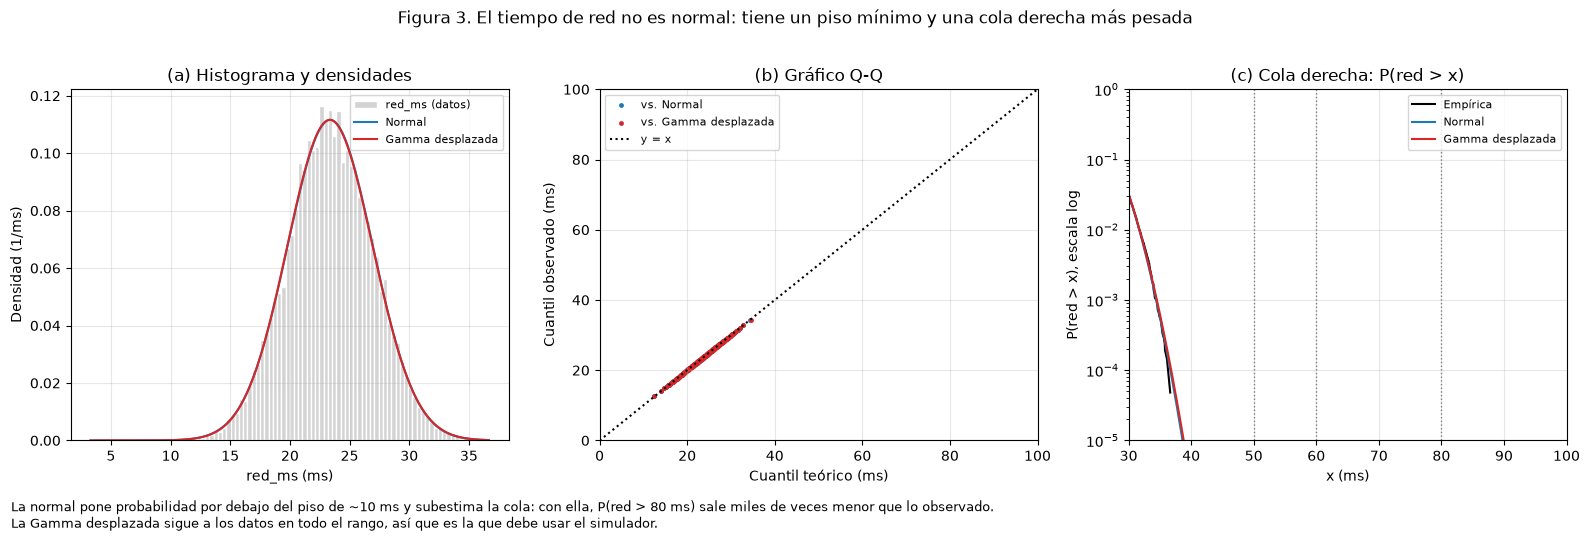

In [37]:
# Parte C · C3 — Figura 3: red_ms frente a los modelos
# Figura 3: red_ms frente al modelo normal
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
xs = np.linspace(red.min() - 5, red.max(), 500)
ax[0].hist(red, bins=80, density=True, color="lightgray", edgecolor="white", label="red_ms (datos)")
ax[0].plot(xs, stats.norm.pdf(xs, m_r, s_r), "tab:blue", label="Normal")
ax[0].plot(xs, stats.gamma.pdf(xs - loc_r, k_r, scale=th_r), "tab:red", label="Gamma desplazada")
ax[0].set(title="(a) Histograma y densidades", xlabel="red_ms (ms)", ylabel="Densidad (1/ms)")
qs = np.linspace(0.001, 0.999, 300)
ax[1].scatter(stats.norm.ppf(qs, m_r, s_r), np.quantile(red, qs), s=6, color="tab:blue", label="vs. Normal")
ax[1].scatter(loc_r + stats.gamma.ppf(qs, k_r, scale=th_r), np.quantile(red, qs), s=6, color="tab:red", label="vs. Gamma desplazada")
ax[1].plot([0, 100], [0, 100], "k:", label="y = x")
ax[1].set(title="(b) Gráfico Q-Q", xlabel="Cuantil teórico (ms)", ylabel="Cuantil observado (ms)", xlim=(0, 100), ylim=(0, 100))
xs3 = np.linspace(30, 100, 300)
ax[2].semilogy(np.sort(red), 1 - np.arange(1, n_red + 1) / (n_red + 1), color="black", label="Empírica")
ax[2].semilogy(xs3, stats.norm.sf(xs3, m_r, s_r), "tab:blue", label="Normal")
ax[2].semilogy(xs3, stats.gamma.sf(xs3 - loc_r, k_r, scale=th_r), "tab:red", label="Gamma desplazada")
for x in [50, 60, 80]:
    ax[2].axvline(x, color="gray", ls=":", lw=1)
ax[2].set(title="(c) Cola derecha: P(red > x)", xlabel="x (ms)", ylabel="P(red > x), escala log", xlim=(30, 100), ylim=(1e-5, 1))
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=0.3)
fig.suptitle("Figura 3. El tiempo de red no es normal: tiene un piso mínimo y una cola derecha más pesada", y=1.02)
fig.text(0.01, -0.06, "La normal pone probabilidad por debajo del piso de ~10 ms y subestima la cola: con ella, P(red > 80 ms) sale miles de veces menor que lo observado.\n"
         "La Gamma desplazada sigue a los datos en todo el rango, así que es la que debe usar el simulador.", fontsize=9)
fig.tight_layout()
plt.show()

✍️ *[Figura 3 — pie de figura: pegue aquí su texto]*

✍️ *[C3 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## C4 · Tiempo total de GPU de N solicitudes consecutivas

✍️ *[C4 — planteamiento: pegue aquí su texto]*

In [38]:
# Parte C · C4 — P(T_N > N(m̂ + 15)) con TLC, Gamma exacta y Edgeworth, frente a simulación
# (remuestreo) y bloques reales de N = 20 solicitudes consecutivas.
m_hat, s_hat, gam_hat = G_c.mean(), G_c.std(ddof=1), stats.skew(G_c)
R_MC = 100_000

# Bloques reales de N consecutivas no cacheadas, dentro de cada tramo estable y en orden de llegada
# La suma de tiempos de solicitudes consecutivas permite contrastar la aproximación con bloques observados.
def bloques_reales(n_bloque):
    sumas = []
    for _, seg in df_estable.sort_values("t_llegada_s").groupby("segmento"):
        v = seg.loc[seg.cache_hit == 0, "gpu_ms"].dropna().to_numpy()
        nb = len(v) // n_bloque
        sumas.append(v[:nb * n_bloque].reshape(nb, n_bloque).sum(axis=1))
    return np.concatenate(sumas)

def prob_C4(n_):
    umbral = n_ * (m_hat + 15)
    z = 15 * np.sqrt(n_) / s_hat
    tlc = stats.norm.sf(z)
    gamma_exacta = stats.gamma.sf(umbral, n_ * k_mm, scale=th_mm)
    edgeworth = stats.norm.sf(z) + stats.norm.pdf(z) * gam_hat / (6 * np.sqrt(n_)) * (z**2 - 1)
    sim = (rng.choice(G_c, size=(R_MC, n_)).sum(axis=1) > umbral).mean()
    sb = bloques_reales(n_)
    return {"N": n_, "TLC": tlc, "Gamma exacta": gamma_exacta, "Edgeworth": edgeworth,
            "Simulación (remuestreo)": sim, "Bloques reales": (sb > umbral).mean(), "n bloques": len(sb)}

res_N = prob_C4(N)
sb = bloques_reales(N)
pb, pb_lo, pb_hi = ic_wilson((sb > N * (m_hat + 15)).sum(), len(sb))
ee_sim = np.sqrt(res_N["Simulación (remuestreo)"] * (1 - res_N["Simulación (remuestreo)"]) / R_MC)
print(f"N = {N}, m̂ = {m_hat:.3f} ms, umbral = {N*(m_hat+15):.1f} ms")
for k_, v in res_N.items():
    if k_ not in ("N", "n bloques"):
        print(f"  {k_:<24} {v:.5f}")
print(f"  error estándar de la simulación: {ee_sim:.5f} | bloques reales: IC {conf:.0%} Wilson [{pb_lo:.4f}, {pb_hi:.4f}] con {len(sb)} bloques")

N = 20, m̂ = 46.315 ms, umbral = 1226.3 ms
  TLC                      0.02087
  Gamma exacta             0.02858
  Edgeworth                0.03306
  Simulación (remuestreo)  0.03167
  Bloques reales           0.02958
  error estándar de la simulación: 0.00055 | bloques reales: IC 99% Wilson [0.0171, 0.0508] con 710 bloques


In [39]:
# Parte C · C4 — Sensibilidad a N (10 a 20)
# Sensibilidad a N (10 a 20): cómo se acercan las aproximaciones al aumentar N
tabla_C4 = pd.DataFrame([res_N if n_ == N else prob_C4(n_) for n_ in range(10, 21)]).set_index("N")
for col in ["TLC", "Gamma exacta", "Edgeworth"]:
    tabla_C4[f"error {col} (%)"] = 100 * (tabla_C4[col] / tabla_C4["Simulación (remuestreo)"] - 1)
print(f"Error relativo medio frente a la simulación (N = 10 a 20): "
      f"TLC {tabla_C4['error TLC (%)'].abs().mean():.1f} % | Gamma {tabla_C4['error Gamma exacta (%)'].abs().mean():.1f} % | "
      f"Edgeworth {tabla_C4['error Edgeworth (%)'].abs().mean():.1f} %")
print(f"Asimetría real de G = {gam_hat:.3f} | asimetría que impone la Gamma de momentos = 2/√k = {2/np.sqrt(k_mm):.3f}")
tabla_C4.round(5)

Error relativo medio frente a la simulación (N = 10 a 20): TLC 23.8 % | Gamma 6.0 % | Edgeworth 6.3 %
Asimetría real de G = 2.072 | asimetría que impone la Gamma de momentos = 2/√k = 1.423


,TLC,Gamma exacta,Edgeworth,Simulación (remuestreo),Bloques reales,n bloques,error TLC (%),error Gamma exacta (%),error Edgeworth (%)
N,,,,,,,,,
10,0.07497,0.08355,0.09155,0.08389,0.08163,1421,-10.63239,-0.40722,9.13065
11,0.06552,0.07465,0.08253,0.07687,0.07204,1291,-14.76496,-2.89297,7.35662
12,0.05738,0.06680,0.07443,0.06857,0.07095,1184,-16.31938,-2.58464,8.55264
13,0.05034,0.05986,0.06717,0.06255,0.06038,1093,-19.51877,-4.30414,7.38951
14,0.04424,0.05371,0.06065,0.05673,0.04631,1015,-22.02523,-5.33158,6.90226
15,0.03892,0.04824,0.05477,0.05137,0.04863,946,-24.22862,-6.09502,6.62783
16,0.03429,0.04337,0.04949,0.04669,0.04510,887,-26.55267,-7.10547,5.99472
17,0.03025,0.03903,0.04473,0.04319,0.04192,835,-29.97003,-9.62638,3.55738
18,0.02670,0.03516,0.04043,0.03816,0.03549,789,-30.02204,-7.87288,5.95550


✍️ *[C4 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

# Parte D — Dependencias y esperanza condicional

✍️ *[Parte D — introducción: pegue aquí su texto]*

## D1 · Distribución conjunta de (clase de tamaño, cache_hit)

✍️ *[D1 — planteamiento: pegue aquí su texto]*

In [40]:
# Parte D · D1 — Clases con t1 = 90 KB y t2 = 425 KB; conteos y distribución conjunta
clases = ["pequeña", "mediana", "grande"]
d1 = df_estable.dropna(subset=["tam_kb", "cache_hit"]).copy()
# La clase se decide por el tamaño en KB. Los valores iguales a cada corte pasan a la clase siguiente.
d1["clase"] = pd.cut(d1.tam_kb, [-np.inf, t1, t2, np.inf], right=False, labels=clases)
d1["cache"] = d1.cache_hit.astype(int)
conteos = pd.crosstab(d1.clase, d1.cache, margins=True, margins_name="Total")
conjunta = pd.crosstab(d1.clase, d1.cache, normalize="all", margins=True, margins_name="Total")
print(f"Clases: pequeña < {t1} KB ≤ mediana < {t2} KB ≤ grande")
print("Conteos:\n", conteos, "\n\nConjunta P(clase, caché) con sus marginales:\n", conjunta.round(4))

Clases: pequeña < 90 KB ≤ mediana < 425 KB ≤ grande
Conteos:
 cache        0     1  Total
clase                      
pequeña   1848  1863   3711
mediana   9966  4312  14278
grande    2411   413   2824
Total    14225  6588  20813 

Conjunta P(clase, caché) con sus marginales:
 cache         0       1   Total
clase                          
pequeña  0.0888  0.0895  0.1783
mediana  0.4788  0.2072  0.6860
grande   0.1158  0.0198  0.1357
Total    0.6835  0.3165  1.0000


In [41]:
# Parte D · D1 — Condicionales con IC de Wilson y prueba de independencia chi-cuadrado
# Condicionales con IC de Wilson
filas = []
for c in clases:
    sub = d1[d1.clase == c]
    p, lo, hi = ic_wilson(sub.cache.sum(), len(sub))
    filas.append({"clase": c, "n": len(sub), "P(caché | clase)": p, "IC inf": lo, "IC sup": hi})
cond_cache = pd.DataFrame(filas)
print(cond_cache.round(4).to_string(index=False))
print("\nP(clase | caché) por columnas:\n", pd.crosstab(d1.clase, d1.cache, normalize="columns").round(4))

# Prueba de independencia chi-cuadrado y V de Cramér
tab = pd.crosstab(d1.clase, d1.cache).to_numpy()
chi2, p_ind, gl, esperados = stats.chi2_contingency(tab)
V = np.sqrt(chi2 / (tab.sum() * (min(tab.shape) - 1)))
print(f"\nChi-cuadrado = {chi2:.1f}, gl = {gl}, p = {p_ind:.3g}, V de Cramér = {V:.3f}, mínimo esperado = {esperados.min():.0f}")
# IC de la diferencia P(caché|pequeña) - P(caché|grande) (Wald)
a_, b_ = d1[d1.clase == "pequeña"].cache, d1[d1.clase == "grande"].cache
dif = a_.mean() - b_.mean(); ee = np.sqrt(a_.mean()*(1-a_.mean())/len(a_) + b_.mean()*(1-b_.mean())/len(b_))
print(f"P(caché|pequeña) - P(caché|grande) = {txt_ic(dif, dif - z_conf*ee, dif + z_conf*ee, 4)}  (Wald, {conf:.0%})")
params["p_cache_clase"] = {c: float(v) for c, v in zip(cond_cache.clase, cond_cache["P(caché | clase)"])}

p_ind_tam = p_ind

  clase     n  P(caché | clase)  IC inf  IC sup
pequeña  3711            0.5020  0.4809  0.5231
mediana 14278            0.3020  0.2922  0.3120
 grande  2824            0.1462  0.1299  0.1642

P(clase | caché) por columnas:
 cache         0       1
clase                  
pequeña  0.1299  0.2828
mediana  0.7006  0.6545
grande   0.1695  0.0627

Chi-cuadrado = 982.6, gl = 2, p = 4.2e-214, V de Cramér = 0.217, mínimo esperado = 894
P(caché|pequeña) - P(caché|grande) = 0.3558  [0.3286, 0.3830]  (Wald, 99%)


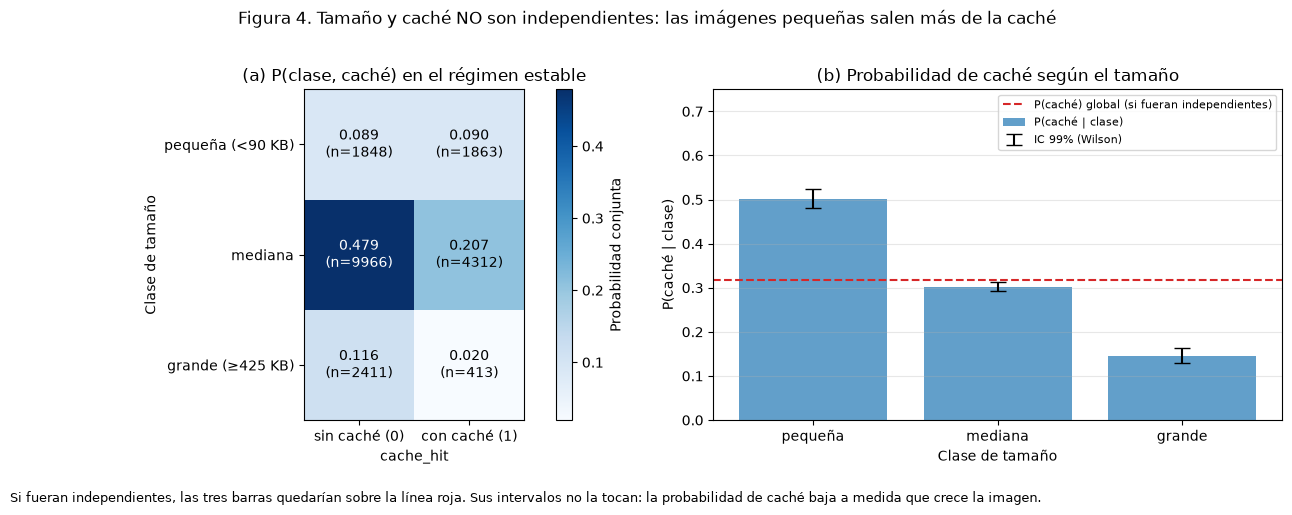

In [42]:
# Parte D · D1 — Figura 4: mapa de calor y P(caché | clase)
# Figura 4: mapa de calor de la distribución conjunta
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
M = pd.crosstab(d1.clase, d1.cache, normalize="all").to_numpy()
im = ax[0].imshow(M, cmap="Blues")
for i in range(3):
    for j in range(2):
        ax[0].text(j, i, f"{M[i, j]:.3f}\n(n={tab[i, j]})", ha="center", va="center",
                   color="white" if M[i, j] > M.max() * 0.6 else "black", fontsize=10)
ax[0].set_xticks([0, 1], ["sin caché (0)", "con caché (1)"])
ax[0].set_yticks(range(3), [f"pequeña (<{t1} KB)", f"mediana", f"grande (≥{t2} KB)"])
ax[0].set(title="(a) P(clase, caché) en el régimen estable", xlabel="cache_hit", ylabel="Clase de tamaño")
fig.colorbar(im, ax=ax[0], label="Probabilidad conjunta")
ax[1].bar(clases, cond_cache["P(caché | clase)"], color="tab:blue", alpha=0.7, label="P(caché | clase)")
ax[1].errorbar(clases, cond_cache["P(caché | clase)"],
               yerr=[cond_cache["P(caché | clase)"] - cond_cache["IC inf"], cond_cache["IC sup"] - cond_cache["P(caché | clase)"]],
               fmt="none", color="black", capsize=6, label=f"IC {conf:.0%} (Wilson)")
ax[1].axhline(d1.cache.mean(), color="tab:red", ls="--", label="P(caché) global (si fueran independientes)")
ax[1].set(title="(b) Probabilidad de caché según el tamaño", xlabel="Clase de tamaño", ylabel="P(caché | clase)", ylim=(0, 0.75))
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, axis="y")
fig.suptitle("Figura 4. Tamaño y caché NO son independientes: las imágenes pequeñas salen más de la caché", y=1.02)
fig.text(0.01, -0.05, "Si fueran independientes, las tres barras quedarían sobre la línea roja. Sus intervalos no la tocan: "
         "la probabilidad de caché baja a medida que crece la imagen.", fontsize=9)
fig.tight_layout()
plt.show()

✍️ *[Figura 4 — pie de figura: pegue aquí su texto]*

✍️ *[D1 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## D2 · Esperanzas condicionales y leyes de la esperanza y la varianza total

✍️ *[D2 — planteamiento: pegue aquí su texto]*

In [43]:
# Parte D · D2 — E[G | clase, no caché] con IC t y E[G | tam_kb] no paramétrica (Nadaraya-Watson)
d2 = df_estable.dropna(subset=["tam_kb", "cache_hit", "gpu_ms"]).copy()
d2["clase"] = pd.cut(d2.tam_kb, [-np.inf, t1, t2, np.inf], right=False, labels=clases)
# E[G | clase, no caché] con IC t
filas = []
for c in clases:
    m, lo, hi = ic_media(d2.loc[(d2.clase == c) & (d2.cache_hit == 0), "gpu_ms"])
    filas.append({"clase": c, "E[G | clase, no caché] (ms)": m, "IC inf": lo, "IC sup": hi})
print(pd.DataFrame(filas).round(3).to_string(index=False))

# Estimación de E[G | tamaño] por suavizado de Nadaraya–Watson con núcleo gaussiano.
def nadaraya_watson(x, y, rejilla, ancho):
    w = np.exp(-0.5 * ((rejilla[:, None] - x[None, :]) / ancho) ** 2)
    return (w * y).sum(axis=1) / w.sum(axis=1)

x_all, g_all = d2.tam_kb.to_numpy(), d2.gpu_ms.to_numpy()
ancho_nw = 1.06 * min(x_all.std(), stats.iqr(x_all) / 1.34) * len(x_all) ** (-1 / 5)   # regla de Silverman
rejilla_nw = np.linspace(np.quantile(x_all, 0.01), np.quantile(x_all, 0.99), 150)
EG_tam = nadaraya_watson(x_all, g_all, rejilla_nw, ancho_nw)                             # incluye ceros de caché
nc2 = d2.cache_hit == 0
EG_tam_nc = nadaraya_watson(x_all[nc2], g_all[nc2], rejilla_nw, ancho_nw)
print(f"\nAncho de banda (Silverman) = {ancho_nw:.1f} KB")
print("E[G | tam_kb] en algunos tamaños (ms):")
print(pd.DataFrame({"tam_kb": rejilla_nw, "E[G|tam] (con caché)": EG_tam, "E[G|tam, no caché]": EG_tam_nc}).iloc[::25].round(2).to_string(index=False))

  clase  E[G | clase, no caché] (ms)  IC inf  IC sup
pequeña                       22.468  21.751  23.185
mediana                       41.904  41.288  42.520
 grande                       82.804  80.400  85.208

Ancho de banda (Silverman) = 22.8 KB
E[G | tam_kb] en algunos tamaños (ms):
 tam_kb  E[G|tam] (con caché)  E[G|tam, no caché]
  17.74                  9.66               19.75
 150.77                 22.89               33.13
 283.80                 34.78               48.81
 416.82                 48.05               63.88
 549.85                 66.35               77.96
 682.88                 85.85               97.16


In [44]:
# Parte D · D2 — Verificación numérica de las leyes de la esperanza total y de la varianza total
# Leyes de la esperanza total y de la varianza total (varianzas poblacionales, ddof=0, para que la identidad sea exacta)
# El peso de cada grupo es su proporción de solicitudes en la muestra.
def descomponer(df_, grupos):
    G = df_.gpu_ms
    p = df_.groupby(grupos, observed=True).size() / len(df_)
    media_g = df_.groupby(grupos, observed=True).gpu_ms.mean()
    var_g = df_.groupby(grupos, observed=True).gpu_ms.var(ddof=0)
    dentro = (p * var_g).sum()
    entre = (p * (media_g - G.mean()) ** 2).sum()
    return {"E[G]": G.mean(), "Σ P·E[G|grupo]": (p * media_g).sum(), "Var(G)": G.var(ddof=0),
            "E[Var(G|grupo)]": dentro, "Var(E[G|grupo])": entre, "suma": dentro + entre,
            "fracción explicada": entre / G.var(ddof=0)}

tabla_D2 = pd.DataFrame({
    "G (todas) | clase": descomponer(d2, "clase"),
    "G (todas) | clase y caché": descomponer(d2, ["clase", "cache_hit"]),
    "G (sin caché) | clase": descomponer(d2[nc2], "clase"),
}).T
tabla_D2.round(4)

,E[G],Σ P·E[G|grupo],Var(G),E[Var(G|grupo)],Var(E[G|grupo]),suma,fracción explicada
G (todas) | clase,31.6659,31.6659,1205.9586,920.2176,285.7410,1205.9586,0.2369
G (todas) | clase y caché,31.6659,31.6659,1205.9586,527.9117,678.0469,1205.9586,0.5622
G (sin caché) | clase,46.3147,46.3147,1085.3850,772.1261,313.2589,1085.3850,0.2886


✍️ *[D2 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## D3 · Modelo lineal para E[G | tam_kb, no caché]

✍️ *[D3 — planteamiento: pegue aquí su texto]*

✍️ *[D3 — deducción a mano (E3): pegue aquí su texto]*

In [45]:
# Parte D · D3 — Mínimos cuadrados resolviendo las ecuaciones normales (X'X)β = X'y
d3 = validas[(validas.cache_hit == 0) & validas.tam_kb.notna()]
x, y = d3.tam_kb.to_numpy(), d3.gpu_ms.to_numpy()
n3 = len(y)
# La primera columna estima el intercepto (ms) y la segunda, la pendiente (ms/KB).
X = np.column_stack([np.ones(n3), x])
XtX, Xty = X.T @ X, X.T @ y
beta = np.linalg.solve(XtX, Xty)                     # solución del sistema de ecuaciones normales
e = y - X @ beta
sigma2 = (e @ e) / (n3 - 2)
cov_ols = sigma2 * np.linalg.inv(XtX)
ee_ols = np.sqrt(np.diag(cov_ols))
tq = stats.t.ppf(1 - alpha / 2, n3 - 2)
R2 = 1 - (e @ e) / ((y - y.mean()) @ (y - y.mean()))
print("Números para escribir a mano:")
print(f"  n = {n3}, Σx = {x.sum():.2f}, Σx² = {(x**2).sum():.2f}, Σy = {y.sum():.2f}, Σxy = {(x*y).sum():.2f}")
print(f"  x̄ = {x.mean():.4f}, ȳ = {y.mean():.4f}, Sxx = {((x-x.mean())**2).sum():.2f}, Sxy = {((x-x.mean())*(y-y.mean())).sum():.2f}")
print("X'X =\n", XtX.round(2), "\nX'y =", Xty.round(2))
print(f"\nMCO: β0 = {txt_ic(beta[0], beta[0]-tq*ee_ols[0], beta[0]+tq*ee_ols[0], 3)} ms")
print(f"     β1 = {txt_ic(beta[1], beta[1]-tq*ee_ols[1], beta[1]+tq*ee_ols[1], 5)} ms/KB   (IC t {conf:.0%})")
print(f"     σ̂ = {np.sqrt(sigma2):.3f} ms, R² = {R2:.4f}")

Números para escribir a mano:
  n = 14213, Σx = 3712955.41, Σx² = 1426385938.41, Σy = 658271.38, Σxy = 225433347.44
  x̄ = 261.2366, ȳ = 46.3147, Sxx = 456426191.94, Sxy = 53468788.12
X'X =
 [[1.42130000e+04 3.71295541e+06]
 [3.71295541e+06 1.42638594e+09]] 
X'y = [6.58271380e+05 2.25433347e+08]

MCO: β0 = 15.712  [14.742, 16.682] ms
     β1 = 0.11715  [0.11408, 0.12021] ms/KB   (IC t 99%)
     σ̂ = 25.392 ms, R² = 0.4060


In [46]:
# Parte D · D3 — Análisis de residuos: Breusch-Pagan y función de varianza
# Análisis de residuos
y_hat = X @ beta
# Si el tamaño explica parte del residuo al cuadrado, la dispersión del error cambia a lo largo de la recta.
def breusch_pagan(residuos, X_):
    # Regresión auxiliar de e² sobre X: LM = n·R²_aux ~ chi2(gl = columnas - 1) si hay homocedasticidad
    e2 = residuos**2
    b_aux = np.linalg.solve(X_.T @ X_, X_.T @ e2)
    r_aux = e2 - X_ @ b_aux
    R2_aux = 1 - (r_aux @ r_aux) / ((e2 - e2.mean()) @ (e2 - e2.mean()))
    LM = len(e2) * R2_aux
    return LM, stats.chi2.sf(LM, X_.shape[1] - 1)

LM, p_bp = breusch_pagan(e, X)
# Función de varianza: varianza de G por deciles de la media ajustada
dec = pd.qcut(y_hat, 10, labels=False)
fv = pd.DataFrame({"mu": y_hat, "y": y}).groupby(dec).agg(media=("y", "mean"), var=("y", "var"))
pendiente_var = np.polyfit(np.log(fv.media), np.log(fv["var"]), 1)[0]
print(f"Breusch-Pagan: LM = {LM:.1f}, p = {p_bp:.3g}  → la varianza de los residuos NO es constante")
print(f"Asimetría de los residuos = {stats.skew(e):.3f} (normal = 0)")
print(f"Pendiente de log Var(G|x) contra log E[G|x] = {pendiente_var:.2f}  (2 = coeficiente de variación constante, como una Gamma)")

Breusch-Pagan: LM = 1675.4, p = 0  → la varianza de los residuos NO es constante
Asimetría de los residuos = 1.311 (normal = 0)
Pendiente de log Var(G|x) contra log E[G|x] = 2.01  (2 = coeficiente de variación constante, como una Gamma)


In [47]:
# Parte D · D3 — Corrección: mínimos cuadrados ponderados (w = 1/μ²) y errores robustos HC3
# Corrección: mínimos cuadrados ponderados iterados con w = 1/μ², por la estructura Gamma (CV constante)
beta_w = beta.copy()
for it in range(100):
    mu = X @ beta_w
    # Los puntos con mayor variabilidad esperada reciben menos peso al volver a ajustar la recta.
    w = 1 / mu**2
    XtWX, XtWy = X.T @ (w[:, None] * X), X.T @ (w * y)
    nuevo = np.linalg.solve(XtWX, XtWy)
    if np.max(np.abs(nuevo - beta_w)) < 1e-12:
        beta_w = nuevo
        break
    beta_w = nuevo
mu = X @ beta_w; w = 1 / mu**2
phi = (w * (y - mu) ** 2).sum() / (n3 - 2)          # = CV² estimado
cov_wls = phi * np.linalg.inv(X.T @ (w[:, None] * X))
ee_wls = np.sqrt(np.diag(cov_wls))
r_std = np.sqrt(w) * (y - mu)                        # residuos ponderados
LM_w, p_bp_w = breusch_pagan(r_std, X)

# Errores robustos HC3 para MCO (otra corrección posible, solo cambia los errores estándar)
inv = np.linalg.inv(XtX)
hii = np.einsum("ij,jk,ik->i", X, inv, X)
cov_hc3 = inv @ (X.T @ ((e**2 / (1 - hii) ** 2)[:, None] * X)) @ inv
ee_hc3 = np.sqrt(np.diag(cov_hc3))

tabla_D3 = pd.DataFrame({
    "β0": [beta[0], beta[0], beta_w[0], b0_g],
    "ee β0": [ee_ols[0], ee_hc3[0], ee_wls[0], ee_cond[0]],
    "β1": [beta[1], beta[1], beta_w[1], b1_g],
    "ee β1": [ee_ols[1], ee_hc3[1], ee_wls[1], ee_cond[1]],
}, index=["MCO (supone varianza constante)", "MCO + errores robustos HC3", "MC ponderados, w = 1/μ² (corrección)", "EMV Gamma condicional (C2)"])
tabla_D3[f"IC β1 {conf:.0%}"] = [f"[{b - tq*s:.5f}, {b + tq*s:.5f}]" for b, s in zip(tabla_D3["β1"], tabla_D3["ee β1"])]
print(f"Iteraciones = {it + 1} | CV estimado = {np.sqrt(phi):.3f} | Breusch-Pagan de los residuos ponderados: LM = {LM_w:.1f}, p = {p_bp_w:.3f}")
params["beta"] = {"b0": [beta_w[0], beta_w[0] - tq*ee_wls[0], beta_w[0] + tq*ee_wls[0]],
                  "b1": [beta_w[1], beta_w[1] - tq*ee_wls[1], beta_w[1] + tq*ee_wls[1]],
                  "cv": float(np.sqrt(phi)), "metodo": "MC ponderados iterados, w = 1/mu^2"}
tabla_D3.round(5)

Iteraciones = 6 | CV estimado = 0.502 | Breusch-Pagan de los residuos ponderados: LM = 0.5, p = 0.470


,β0,ee β0,β1,ee β1,IC β1 99%
MCO (supone varianza constante),15.71176,0.37653,0.11715,0.00119,"[0.11408, 0.12021]"
MCO + errores robustos HC3,15.71176,0.42586,0.11715,0.00197,"[0.11206, 0.12223]"
"MC ponderados, w = 1/μ² (corrección)",15.90834,0.24650,0.11634,0.00130,"[0.11300, 0.11968]"
EMV Gamma condicional (C2),15.90834,0.24608,0.11634,0.00130,"[0.11300, 0.11968]"


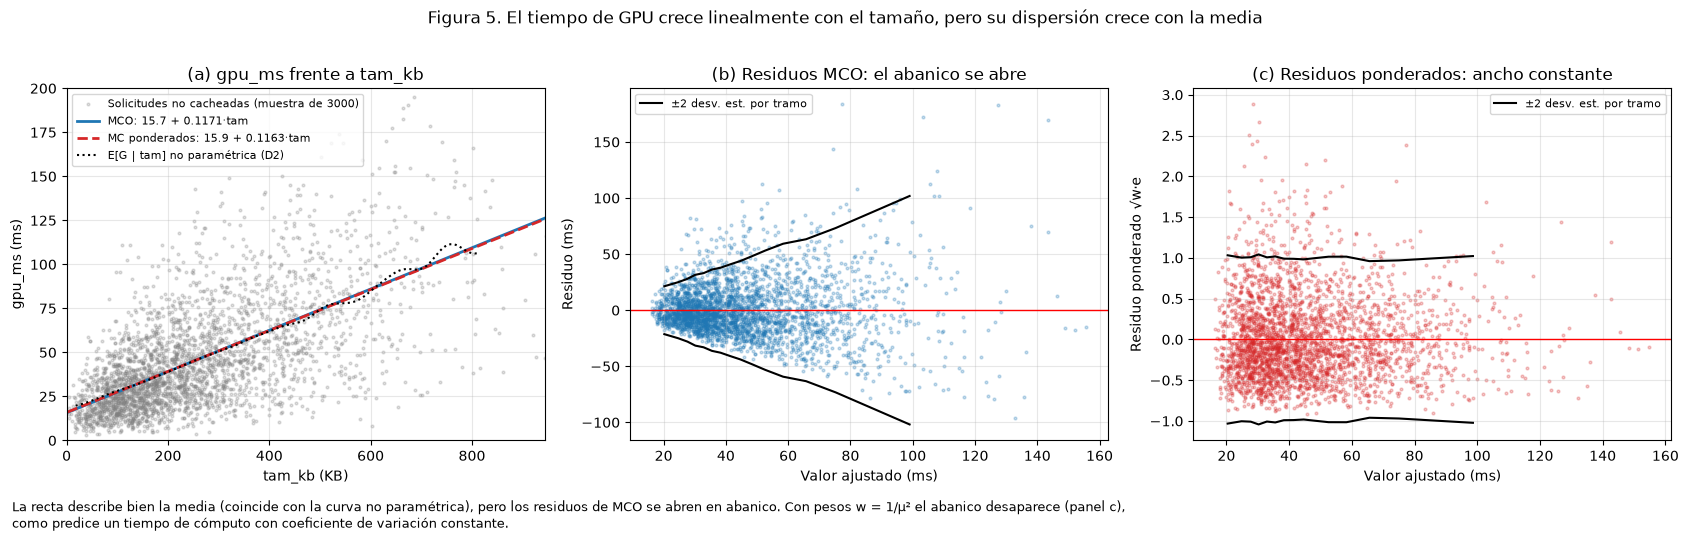

In [48]:
# Parte D · D3 — Figura 5: recta ajustada y residuos
# Figura 5: regresión y residuos
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
idx = rng.choice(n3, size=min(3000, n3), replace=False)          # submuestra aleatoria para el gráfico de dispersión
ax[0].scatter(x[idx], y[idx], s=4, alpha=0.25, color="gray", label="Solicitudes no cacheadas (muestra de 3000)")
xs = np.linspace(x.min(), np.quantile(x, 0.995), 200)
ax[0].plot(xs, beta[0] + beta[1] * xs, "tab:blue", lw=2, label=f"MCO: {beta[0]:.1f} + {beta[1]:.4f}·tam")
ax[0].plot(xs, beta_w[0] + beta_w[1] * xs, "tab:red", lw=2, ls="--", label=f"MC ponderados: {beta_w[0]:.1f} + {beta_w[1]:.4f}·tam")
ax[0].plot(rejilla_nw, EG_tam_nc, "black", lw=1.5, ls=":", label="E[G | tam] no paramétrica (D2)")
ax[0].set(title="(a) gpu_ms frente a tam_kb", xlabel="tam_kb (KB)", ylabel="gpu_ms (ms)", xlim=(0, np.quantile(x, 0.995)), ylim=(0, 200))
ax[1].scatter(y_hat[idx], e[idx], s=4, alpha=0.25, color="tab:blue")
cort = pd.qcut(y_hat, 15, labels=False)
banda = pd.DataFrame({"f": y_hat, "e": e}).groupby(cort).agg(f=("f", "mean"), sd=("e", "std"))
ax[1].plot(banda.f, 2 * banda.sd, "k-", label="±2 desv. est. por tramo")
ax[1].plot(banda.f, -2 * banda.sd, "k-")
ax[1].axhline(0, color="red", lw=1)
ax[1].set(title="(b) Residuos MCO: el abanico se abre", xlabel="Valor ajustado (ms)", ylabel="Residuo (ms)")
ax[2].scatter(mu[idx], r_std[idx], s=4, alpha=0.25, color="tab:red")
banda_w = pd.DataFrame({"f": mu, "r": r_std}).groupby(pd.qcut(mu, 15, labels=False)).agg(f=("f", "mean"), sd=("r", "std"))
ax[2].plot(banda_w.f, 2 * banda_w.sd, "k-", label="±2 desv. est. por tramo")
ax[2].plot(banda_w.f, -2 * banda_w.sd, "k-")
ax[2].axhline(0, color="red", lw=1)
ax[2].set(title="(c) Residuos ponderados: ancho constante", xlabel="Valor ajustado (ms)", ylabel="Residuo ponderado √w·e")
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=0.3)
fig.suptitle("Figura 5. El tiempo de GPU crece linealmente con el tamaño, pero su dispersión crece con la media", y=1.02)
fig.text(0.01, -0.06, "La recta describe bien la media (coincide con la curva no paramétrica), pero los residuos de MCO se abren en abanico. "
         "Con pesos w = 1/μ² el abanico desaparece (panel c),\ncomo predice un tiempo de cómputo con coeficiente de variación constante.", fontsize=9)
fig.tight_layout()
plt.show()

✍️ *[Figura 5 — pie de figura: pegue aquí su texto]*

✍️ *[D3 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## D4 · Covarianza y correlación entre tam_kb y gpu_ms (sin caché)

✍️ *[D4 — planteamiento: pegue aquí su texto]*

In [49]:
# Parte D · D4 — Covarianza, Pearson con IC (z de Fisher) y Spearman
cov_xy = np.cov(x, y, ddof=1)[0, 1]
r_xy = np.corrcoef(x, y)[0, 1]
zf = np.arctanh(r_xy); ee_z = 1 / np.sqrt(n3 - 3)
r_lo, r_hi = np.tanh(zf - z_conf * ee_z), np.tanh(zf + z_conf * ee_z)
rho_s = stats.spearmanr(x, y)[0]
eta2_nc = tabla_D2.loc["G (sin caché) | clase", "fracción explicada"]
print(f"Cov(tam, gpu) = {cov_xy:.2f} KB·ms")
print(f"Correlación de Pearson r = {txt_ic(r_xy, r_lo, r_hi, 4)}  (IC {conf:.0%}, transformación z de Fisher)")
print(f"Correlación de Spearman = {rho_s:.4f}")
print(f"Comprobación: Cov/Var(tam) = {cov_xy/np.var(x, ddof=1):.5f} = β1 de MCO ({beta[1]:.5f})")
print(f"Comprobación: r² = {r_xy**2:.4f} = R² de MCO ({R2:.4f})")
print(f"Fracción de Var(G sin caché) que explica la CLASE (D2) = {eta2_nc:.4f}  frente a r² = {r_xy**2:.4f} con el tamaño continuo")

Cov(tam, gpu) = 3762.23 KB·ms
Correlación de Pearson r = 0.6372  [0.6242, 0.6499]  (IC 99%, transformación z de Fisher)
Correlación de Spearman = 0.6147
Comprobación: Cov/Var(tam) = 0.11715 = β1 de MCO (0.11715)
Comprobación: r² = 0.4060 = R² de MCO (0.4060)
Fracción de Var(G sin caché) que explica la CLASE (D2) = 0.2886  frente a r² = 0.4060 con el tamaño continuo


In [50]:
# Parte D · Parámetros ajustados para el simulador y momentos de las deducciones a mano (diccionario en memoria)
def a_json(o):
    if isinstance(o, dict): return {k: a_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)): return [a_json(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
salida = {"S": S, "borrador": ES_BORRADOR, "conf": conf, "t1": t1, "t2": t2, "N": N, "params": a_json(params),
          "deducciones": a_json({"h": h_hat, "k": k_mv, "theta": th_mv, "k_mm": k_mm, "theta_mm": th_mm,
                                  "E_G_formula": E_mv, "Var_G_formula": V_mv, "E_G_muestra": G_todas.mean(), "Var_G_muestra": G_todas.var(ddof=1),
                                  "n": n3, "sum_x": x.sum(), "sum_x2": (x**2).sum(), "sum_y": y.sum(), "sum_xy": (x*y).sum(),
                                  "xbar": x.mean(), "ybar": y.mean(), "Sxx": ((x-x.mean())**2).sum(), "Sxy": ((x-x.mean())*(y-y.mean())).sum(),
                                  "b0": beta[0], "b1": beta[1], "ee_b0": ee_ols[0], "ee_b1": ee_ols[1], "sigma": np.sqrt(sigma2), "tq": tq,
                                  "b0_w": beta_w[0], "b1_w": beta_w[1], "cv": np.sqrt(phi)})}

✍️ *[D4 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

# Parte E — Monitoreo y decisión de alertas

✍️ *[Parte E — introducción: pegue aquí su texto]*

In [51]:
# Parte E · Carga de monitoreo (desde los datos incrustados) y reglas combinadas
# Prevalencia en pruebas ≠ prevalencia en producción (pi_prod de la primera celda).
mon = pd.read_csv(io.BytesIO(abrir_csv("monitoreo")))
mon["D1_y_D2"] = (mon["D1"] & mon["D2"]).astype(int)
mon["D1_o_D2"] = (mon["D1"] | mon["D2"]).astype(int)
reglas = ["D1", "D2", "D1_y_D2", "D1_o_D2"]
inc = mon["incidente"] == 1
print(f"Minutos: {len(mon)}, con incidente: {inc.sum()} ({inc.mean():.3%})  "
      f"<- prevalencia del entorno de PRUEBAS, no de producción (π = {pi_prod})")

  monitoreo (1).csv: 70,917 bytes, SHA-256 verificado (e24fc592ef74d540…)
Minutos: 6000, con incidente: 538 (8.967%)  <- prevalencia del entorno de PRUEBAS, no de producción (π = 0.009)


## E1 · Sensibilidad y tasa de falsos positivos de las cuatro reglas

✍️ *[E1 — planteamiento: pegue aquí su texto]*

In [52]:
# Parte E · E1 — Sensibilidad = P(alerta | incidente), FPR = P(alerta | sin incidente), IC de Wilson
filas = []
# La sensibilidad usa como denominador los minutos con incidente; los falsos positivos usan los minutos sin incidente.
for regla in reglas:
    x_s, n_s = mon.loc[inc, regla].sum(), inc.sum()
    x_f, n_f = mon.loc[~inc, regla].sum(), (~inc).sum()
    s, sl, su = ic_wilson(x_s, n_s)
    f, fl, fu = ic_wilson(x_f, n_f)
    filas.append({"regla": regla, "x_sens": x_s, "n_sens": n_s, "x_fp": x_f, "n_fp": n_f,
                  "sens": s, "sens_lo": sl, "sens_hi": su, "fpr": f, "fpr_lo": fl, "fpr_hi": fu})
e1 = pd.DataFrame(filas).set_index("regla")
print(e1[["sens", "sens_lo", "sens_hi", "fpr", "fpr_lo", "fpr_hi"]].round(4))

           sens  sens_lo  sens_hi     fpr  fpr_lo  fpr_hi
regla                                                    
D1       0.9052   0.8676   0.9330  0.0092  0.0064  0.0131
D2       0.7565   0.7059   0.8009  0.0077  0.0052  0.0114
D1_y_D2  0.6877   0.6342   0.7366  0.0022  0.0011  0.0045
D1_o_D2  0.9740   0.9497   0.9867  0.0146  0.0110  0.0195


✍️ *[E1 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## E2 · Probabilidad de incidente real dada una alerta, en producción

✍️ *[E2 — planteamiento: pegue aquí su texto]*

In [53]:
# Parte E · E2 — Teorema de Bayes con π de producción; IC por Monte Carlo con Beta de Jeffreys
# Bayes combina el rendimiento medido en pruebas con la frecuencia de incidentes prevista en producción.
def vpp(sens, fpr, prev):
    return sens * prev / (sens * prev + fpr * (1 - prev))


M = 20_000
prev_pruebas = inc.mean()
e2 = []
for regla, f in e1.iterrows():
    s_sim = rng.beta(f.x_sens + 0.5, f.n_sens - f.x_sens + 0.5, M)
    f_sim = rng.beta(f.x_fp + 0.5, f.n_fp - f.x_fp + 0.5, M)
    v_sim = vpp(s_sim, f_sim, pi_prod)
    lo, hi = np.quantile(v_sim, [alpha / 2, 1 - alpha / 2])
    e2.append({"regla": regla, "VPP_produccion": vpp(f.sens, f.fpr, pi_prod),
               "lo": lo, "hi": hi, "VPP_en_monitoreo.csv": vpp(f.sens, f.fpr, prev_pruebas)})
e2 = pd.DataFrame(e2).set_index("regla")
print(e2.round(4))

         VPP_produccion      lo      hi  VPP_en_monitoreo.csv
regla                                                        
D1               0.4731  0.3885  0.5699                0.9069
D2               0.4719  0.3781  0.5741                0.9065
D1_y_D2          0.7398  0.5937  0.8666                0.9686
D1_o_D2          0.3765  0.3132  0.4488                0.8675


✍️ *[E2 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## E3 · ¿Son D1 y D2 condicionalmente independientes dado el estado?

✍️ *[E3 — planteamiento: pegue aquí su texto]*

In [54]:
# Parte E · E3 — Tablas D1×D2 dentro de cada estado (Fisher exacta) y efecto sobre el VPP
for nombre, mask in [("con incidente", inc), ("sin incidente", ~inc)]:
    sub = mon[mask]
    tabla = pd.crosstab(sub["D1"], sub["D2"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    odds, p_f = stats.fisher_exact(tabla.values)
    p11 = (sub["D1"] & sub["D2"]).mean()
    p_ind = sub["D1"].mean() * sub["D2"].mean()
    print(f"[{nombre}] tabla D1×D2:\n{tabla}\n  P(ambas)={p11:.4f}  producto={p_ind:.4f}  "
          f"odds ratio={odds:.2f}  Fisher p={p_f:.4g}")

s_ind = e1.loc["D1", "sens"] * e1.loc["D2", "sens"]
f_ind = e1.loc["D1", "fpr"] * e1.loc["D2", "fpr"]
print(f"\nVPP de 'D1 y D2' en producción: real={e2.loc['D1_y_D2','VPP_produccion']:.4f}  "
      f"suponiendo independencia={vpp(s_ind, f_ind, pi_prod):.4f}")
# La dependencia positiva aumenta la frecuencia de falsos positivos conjuntos
# respecto al producto de las tasas marginales.

[con incidente] tabla D1×D2:
D2    0    1
D1          
0    14   37
1   117  370
  P(ambas)=0.6877  producto=0.6848  odds ratio=1.20  Fisher p=0.6079
[sin incidente] tabla D1×D2:
D2     0   1
D1          
0   5382  30
1     38  12
  P(ambas)=0.0022  producto=0.0001  odds ratio=56.65  Fisher p=7.603e-16

VPP de 'D1 y D2' en producción: real=0.7398  suponiendo independencia=0.9888


✍️ *[E3 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## E4 · Falsas alarmas por día y elección de la regla

✍️ *[E4 — planteamiento: pegue aquí su texto]*

kmax = 5, minutos sin incidente por día = 1427
         FA_esperadas_dia  P(X<=kmax) puntual  P(X<=kmax) peor caso  P(cumple)    sens  cumple
regla                                                                                         
D1                13.0630              0.0101                0.0003     0.0000  0.9052   False
D2                10.9729              0.0376                0.0021     0.0000  0.7565   False
D1_y_D2            3.1351              0.9021                0.4714     0.4948  0.6877   False
D1_o_D2           20.9008              0.0000                0.0000     0.0000  0.9740   False
NINGUNA regla cumple la exigencia. La más cercana es D1_y_D2 (P = 0.902); hay que reportarlo así.


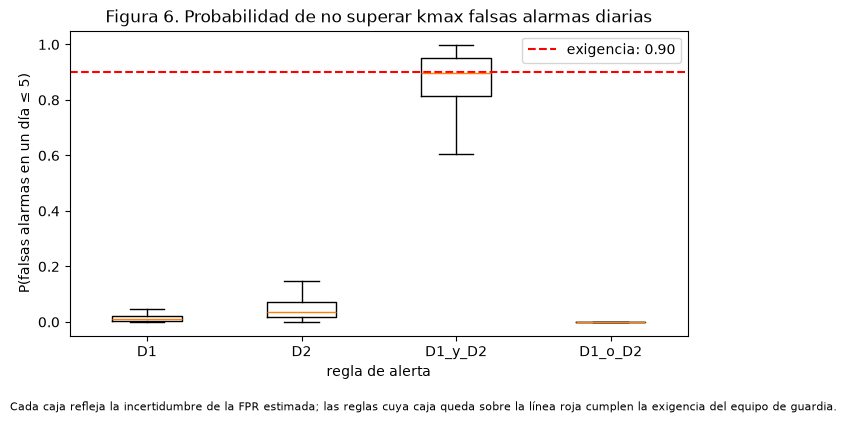

In [55]:
# Parte E · E4 — X ~ Binomial(n0, FPR) falsas alarmas por día; exigencia P(X ≤ kmax) ≥ 0.90
# con criterio conservador (percentil alpha de la incertidumbre de la FPR).
n0 = int(round(1440 * (1 - pi_prod)))
e4 = []
dist_prob = {}
for regla, f in e1.iterrows():
    # Con pocos falsos positivos, la tasa real es incierta. Cada tasa simulada produce una probabilidad diaria distinta.
    f_sim = rng.beta(f.x_fp + 0.5, f.n_fp - f.x_fp + 0.5, M)
    prob_sim = stats.binom.cdf(kmax, n0, f_sim)
    dist_prob[regla] = prob_sim
    e4.append({"regla": regla, "FA_esperadas_dia": n0 * f.fpr,
               "P(X<=kmax) puntual": stats.binom.cdf(kmax, n0, f.fpr),
               "P(X<=kmax) peor caso": np.quantile(prob_sim, alpha),
               "P(cumple)": np.mean(prob_sim >= 0.90),
               "sens": f.sens})
e4 = pd.DataFrame(e4).set_index("regla")
e4["cumple"] = e4["P(X<=kmax) peor caso"] >= 0.90
print(f"kmax = {kmax}, minutos sin incidente por día = {n0}")
candidatas = e4[e4["cumple"]]
pd.set_option("display.width", 200)
print(e4.round(4).to_string())
if len(candidatas):
    recomendada = candidatas["sens"].idxmax()
    print(f"Regla recomendada (cumple y detecta más incidentes): {recomendada}")
else:
    # Si el conjunto de reglas admisibles está vacío, se selecciona la de mayor probabilidad puntual.
    recomendada = e4["P(X<=kmax) puntual"].idxmax()
    print(f"NINGUNA regla cumple la exigencia. La más cercana es {recomendada} "
          f"(P = {e4.loc[recomendada, 'P(X<=kmax) puntual']:.3f}); hay que reportarlo así.")
params["regla_alerta"] = recomendada

# Figura 6
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([dist_prob[r] for r in reglas], showfliers=False)
ax.set_xticks(range(1, len(reglas) + 1), reglas)
ax.axhline(0.90, color="red", ls="--", label="exigencia: 0.90")
ax.set_ylabel(f"P(falsas alarmas en un día ≤ {kmax})")
ax.set_xlabel("regla de alerta")
ax.set_title("Figura 6. Probabilidad de no superar kmax falsas alarmas diarias")
ax.legend()
plt.figtext(0.01, -0.04, "Cada caja refleja la incertidumbre de la FPR estimada; las reglas cuya "
            "caja queda sobre la línea roja cumplen la exigencia del equipo de guardia.", fontsize=8)
plt.tight_layout()
plt.show()
# El modelo binomial diario supone independencia entre minutos.
# La correlación temporal positiva puede aumentar la varianza del conteo diario.

✍️ *[Figura 6 — pie de figura: pegue aquí su texto]*

✍️ *[E4 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

# Parte F — Inferencia, distribuciones muestrales y comparación de versiones

✍️ *[Parte F — introducción: pegue aquí su texto]*

In [56]:
# Parte F · Cuantil normal al nivel conf (los demás parámetros vienen de la primera celda)
z = stats.norm.ppf(1 - alpha / 2)

In [57]:
# Parte F · Funciones de intervalos compartidas por E, F y G (t, Wald, Wilson, Newcombe, Welch)
def ic_media_t(x, conf=conf):
    """IC t clásico para la media: x̄ ± t * s/√n. Supone datos independientes."""
    x = np.asarray(x, float)
    n = x.size
    m, s = x.mean(), x.std(ddof=1)
    t = stats.t.ppf(1 - (1 - conf) / 2, n - 1)
    return m, m - t * s / np.sqrt(n), m + t * s / np.sqrt(n)


def ic_wald(x, n, conf=conf):
    """IC de Wald para una proporción: p̂ ± z √(p̂(1-p̂)/n)."""
    zz = stats.norm.ppf(1 - (1 - conf) / 2)
    p = x / n
    se = np.sqrt(p * (1 - p) / n)
    return p, p - zz * se, p + zz * se


def ic_wilson(x, n, conf=conf):
    """IC de Wilson (score) para una proporción. Funciona bien con p pequeña."""
    zz = stats.norm.ppf(1 - (1 - conf) / 2)
    p = x / n
    centro = (p + zz**2 / (2 * n)) / (1 + zz**2 / n)
    semi = zz * np.sqrt(p * (1 - p) / n + zz**2 / (4 * n**2)) / (1 + zz**2 / n)
    return p, centro - semi, centro + semi


def ic_dif_newcombe(x1, n1, x2, n2, conf=conf):
    """IC para p2 - p1 (método híbrido de Newcombe, construido con dos Wilson)."""
    p1, l1, u1 = ic_wilson(x1, n1, conf)
    p2, l2, u2 = ic_wilson(x2, n2, conf)
    d = p2 - p1
    return d, d - np.sqrt((p2 - l2) ** 2 + (u1 - p1) ** 2), d + np.sqrt((u2 - p2) ** 2 + (p1 - l1) ** 2)


def ic_dif_welch(xA, xB, conf=conf):
    """IC para media(B) - media(A) con varianzas distintas (Welch)."""
    xA, xB = np.asarray(xA, float), np.asarray(xB, float)
    vA, vB = xA.var(ddof=1) / xA.size, xB.var(ddof=1) / xB.size
    gl = (vA + vB) ** 2 / (vA**2 / (xA.size - 1) + vB**2 / (xB.size - 1))
    d = xB.mean() - xA.mean()
    t = stats.t.ppf(1 - (1 - conf) / 2, gl)
    return d, d - t * np.sqrt(vA + vB), d + t * np.sqrt(vA + vB)

## F1 · Distribución muestral de la media de la latencia

✍️ *[F1 — planteamiento: pegue aquí su texto]*

Población: media=58.30 ms, sd=38.39, asimetría=1.67, curtosis exceso=4.69


      n   sd(x̄)     σ/√n  asimetría  curtosis_exceso  cobertura
0     5  16.9277  17.1701     0.7048           0.7231     0.9077
1    30   6.9996   7.0097     0.2953           0.1948     0.9709
2   200   2.7369   2.7148     0.0822           0.0739     0.9854
3  2000   0.8651   0.8585     0.0482           0.0031     0.9885
n=    5  cobertura=0.9025
n=   10  cobertura=0.9367
n=   15  cobertura=0.9555
n=   20  cobertura=0.9654
n=   30  cobertura=0.9723
n=   40  cobertura=0.9746
n=   50  cobertura=0.9783
n=   75  cobertura=0.9801
Menor n con cobertura >= 0.98: n = 75


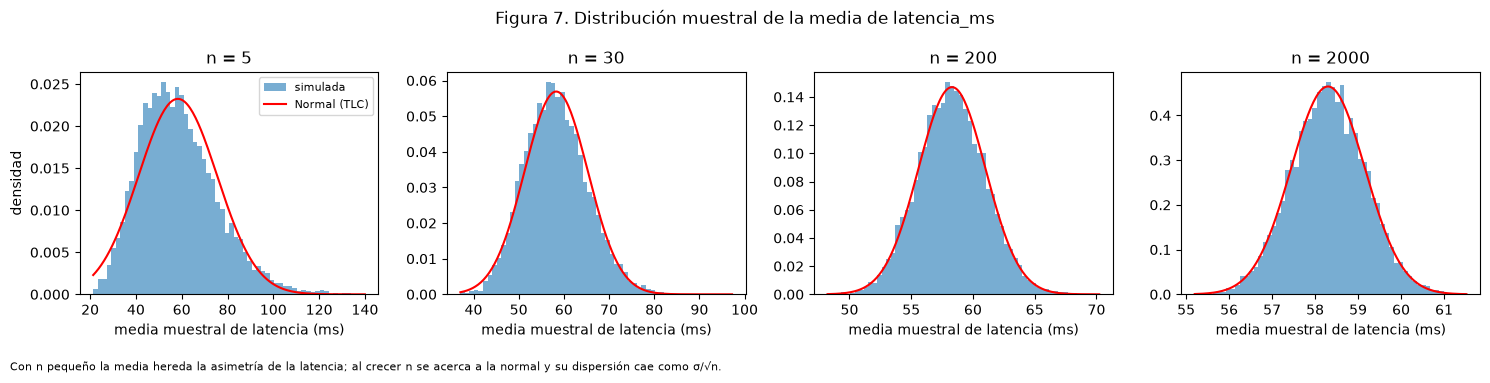

In [58]:
# Parte F · F1 — Medias muestrales por remuestreo, cobertura efectiva y menor n con cobertura ≥ conf − 0.01
poblacion = df_estable["latencia_ms"].dropna().to_numpy()   # NaN = campo dañado (Parte A)
mu_pob, sd_pob = poblacion.mean(), poblacion.std()
print(f"Población: media={mu_pob:.2f} ms, sd={sd_pob:.2f}, "
      f"asimetría={stats.skew(poblacion):.2f}, curtosis exceso={stats.kurtosis(poblacion):.2f}")

M = 10_000


def medias_y_cobertura(n, M=M, bloque=1000):
    """Devuelve las M medias muestrales y la cobertura del IC normal (z)."""
    medias, cubre = [], 0
    for _ in range(M // bloque):                       # remuestreo por lotes para limitar la memoria utilizada
        muestras = rng.choice(poblacion, size=(bloque, n), replace=True)
        xb = muestras.mean(axis=1)
        s = muestras.std(axis=1, ddof=1)
        cubre += np.sum(np.abs(xb - mu_pob) <= z * s / np.sqrt(n))
        medias.append(xb)
    return np.concatenate(medias), cubre / M


tabla_f1 = []
medias_por_n = {}
for n in [5, 30, 200, 2000]:
    xb, cob = medias_y_cobertura(n)
    medias_por_n[n] = xb
    tabla_f1.append({"n": n, "sd(x̄)": xb.std(), "σ/√n": sd_pob / np.sqrt(n),
                     "asimetría": stats.skew(xb), "curtosis_exceso": stats.kurtosis(xb),
                     "cobertura": cob})
print(pd.DataFrame(tabla_f1).round(4))

# Menor n con cobertura >= conf - 0.01
objetivo = conf - 0.01
n_min = None
for n in [5, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200, 300, 500, 1000, 2000]:
    _, cob = medias_y_cobertura(n)
    print(f"n={n:5d}  cobertura={cob:.4f}")
    if cob >= objetivo:
        n_min = n
        break
print(f"Menor n con cobertura >= {objetivo:.2f}: n = {n_min}")

# Figura 7
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, n in zip(axs, [5, 30, 200, 2000]):
    xb = medias_por_n[n]
    ax.hist(xb, bins=60, density=True, alpha=0.6, label="simulada")
    xs = np.linspace(xb.min(), xb.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu_pob, sd_pob / np.sqrt(n)), "r", label="Normal (TLC)")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("media muestral de latencia (ms)")
axs[0].set_ylabel("densidad")
axs[0].legend(fontsize=8)
fig.suptitle("Figura 7. Distribución muestral de la media de latencia_ms")
plt.figtext(0.01, -0.05, "Con n pequeño la media hereda la asimetría de la latencia; "
            "al crecer n se acerca a la normal y su dispersión cae como σ/√n.", fontsize=8)
plt.tight_layout()
plt.show()

✍️ *[Figura 7 — pie de figura: pegue aquí su texto]*

✍️ *[F1 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## F2 · Intervalo para la latencia media y revisión de supuestos

✍️ *[F2 — planteamiento: pegue aquí su texto]*

In [59]:
# Parte F · F2 — IC t clásico frente a medias por lotes (corrige la autocorrelación)
# Las medias por lotes se calculan dentro de cada tramo estable.
# El pico se excluye antes de agrupar las observaciones.
# Las solicitudes consecutivas pueden compartir la misma cola. El intervalo por lotes conserva parte de esa dependencia.
lat_t = df_estable.sort_values("t_llegada_s")["latencia_ms"].dropna().to_numpy()

m_cl, lo_cl, hi_cl = ic_media_t(lat_t)


def autocorr(x, lag):
    x = x - x.mean()
    return np.sum(x[:-lag] * x[lag:]) / np.sum(x * x)


acf = {k: autocorr(lat_t, k) for k in [1, 2, 5, 10, 50]}
banda = z / np.sqrt(lat_t.size)          # banda aprox. si no hubiera autocorrelación
print("Autocorrelación:", {k: round(v, 3) for k, v in acf.items()}, f" banda ±{banda:.3f}")

k_lotes = 30
lotes = []
for _, tramo in df_estable.sort_values("t_llegada_s").groupby("segmento"):
    x = tramo["latencia_ms"].dropna().to_numpy()
    k_tramo = max(2, round(k_lotes * len(x) / len(lat_t)))   # lotes proporcionales al tramo
    lotes += np.array_split(x, k_tramo)
medias_lote = np.array([b.mean() for b in lotes])
print(f"Autocorrelación lag-1 entre medias de lote: {autocorr(medias_lote, 1):.3f}")
m_bm, lo_bm, hi_bm = ic_media_t(medias_lote)

print(f"IC clásico  {conf:.0%}: {m_cl:.2f} [{lo_cl:.2f}, {hi_cl:.2f}]  ancho={hi_cl-lo_cl:.2f}")
print(f"IC por lotes {conf:.0%}: {m_bm:.2f} [{lo_bm:.2f}, {hi_bm:.2f}]  ancho={hi_bm-lo_bm:.2f}")
print(f"El IC corregido es {(hi_bm-lo_bm)/(hi_cl-lo_cl):.2f} veces más ancho")

Autocorrelación: {1: np.float64(0.092), 2: np.float64(0.091), 5: np.float64(0.042), 10: np.float64(0.002), 50: np.float64(0.004)}  banda ±0.018
Autocorrelación lag-1 entre medias de lote: 0.114
IC clásico  99%: 58.30 [57.61, 58.99]  ancho=1.37
IC por lotes 99%: 58.30 [57.19, 59.41]  ancho=2.23
El IC corregido es 1.62 veces más ancho


✍️ *[F2 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## F3 · Comparación de la versión B con la A

✍️ *[F3 — planteamiento: pegue aquí su texto]*

In [60]:
# Parte F · F3 — Balance de la asignación y tres diferencias B − A con IC Bonferroni (1 − alpha/3)
A = df_estable[df_estable["version"] == "A"]
B_ = df_estable[df_estable["version"] == "B"]

# Balance de las covariables entre las versiones A y B.
def dif_estandarizada(a, b):
    return (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)

print("Balance entre versiones (|dif. estandarizada| < 0.1 = comparables):")
for col in ["tam_kb", "red_ms", "cache_hit"]:
    print(f"  {col:10s} SMD = {dif_estandarizada(A[col], B_[col]):+.3f}")
x_prop = stats.binomtest(len(B_), len(df_estable), 0.5)
print(f"  Proporción asignada a B = {len(B_)/len(df_estable):.3f} (p-valor vs 0.5: {x_prop.pvalue:.3f})")

# Bonferroni distribuye el error familiar entre los tres intervalos de la comparación A/B.
conf_bonf = 1 - alpha / 3
gA = A.loc[A["cache_hit"] == 0, "gpu_ms"].dropna()
gB = B_.loc[B_["cache_hit"] == 0, "gpu_ms"].dropna()
A_i, A_l = A.dropna(subset=["intentos"]), A.dropna(subset=["latencia_ms"])      # para (ii) y (iii)
B_i, B_l = B_.dropna(subset=["intentos"]), B_.dropna(subset=["latencia_ms"])
f3 = {
    "(i) GPU media (ms)": ic_dif_welch(gA, gB, conf_bonf),
    "(ii) P(intentos>1)": ic_dif_newcombe((A_i["intentos"] > 1).sum(), len(A_i),
                                         (B_i["intentos"] > 1).sum(), len(B_i), conf_bonf),
    "(iii) P(L>tau)": ic_dif_newcombe((A_l["latencia_ms"] > tau).sum(), len(A_l),
                                     (B_l["latencia_ms"] > tau).sum(), len(B_l), conf_bonf),
}
print(f"\nDiferencias B − A, IC Bonferroni (cada uno al {conf_bonf:.4f}):")
for nombre, (d, lo, hi) in f3.items():
    veredicto = "B menor (mejor)" if hi < 0 else ("B mayor (peor)" if lo > 0 else "sin diferencia clara")
    print(f"  {nombre:20s} {d:+.4f}  [{lo:+.4f}, {hi:+.4f}]  -> {veredicto}")
params["F3"] = f3
# La regla de adopción requiere al menos una mejora con intervalo negativo
# y ningún intervalo que indique un deterioro.
mejora_F3 = [n for n, (d, lo, hi) in f3.items() if hi < 0]
empeora_F3 = [n for n, (d, lo, hi) in f3.items() if lo > 0]
decision_F3 = "adoptar B" if (mejora_F3 and not empeora_F3) else ("no adoptar B" if empeora_F3 else "sin evidencia para cambiar a B")
print(f"Decisión F3 (calculada): {decision_F3} | mejora con evidencia en: {mejora_F3} | empeora en: {empeora_F3}")

Balance entre versiones (|dif. estandarizada| < 0.1 = comparables):
  tam_kb     SMD = +0.034
  red_ms     SMD = +0.002
  cache_hit  SMD = -0.028
  Proporción asignada a B = 0.498 (p-valor vs 0.5: 0.647)

Diferencias B − A, IC Bonferroni (cada uno al 0.9967):
  (i) GPU media (ms)   -3.0080  [-4.6295, -1.3866]  -> B menor (mejor)
  (ii) P(intentos>1)   -0.0012  [-0.0154, +0.0130]  -> sin diferencia clara
  (iii) P(L>tau)       -0.0003  [-0.0022, +0.0016]  -> sin diferencia clara
Decisión F3 (calculada): adoptar B | mejora con evidencia en: ['(i) GPU media (ms)'] | empeora en: []


✍️ *[F3 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## F4 · Cobertura de intervalos para una proporción (Wald frente a Wilson)

✍️ *[F4 — planteamiento: pegue aquí su texto]*

       Wald                      Wilson                     
n       10     30     100    500    10     30     100    500
p                                                           
0.01  0.096  0.264  0.643  0.961  0.904  0.964  0.981  0.986
0.02  0.180  0.452  0.872  0.974  0.986  0.978  0.984  0.993
0.05  0.394  0.783  0.960  0.979  0.989  0.986  0.988  0.990
0.10  0.653  0.957  0.974  0.984  0.987  0.991  0.988  0.991
0.30  0.960  0.969  0.986  0.990  0.988  0.990  0.988  0.990
0.50  0.979  0.982  0.987  0.989  0.998  0.995  0.987  0.989


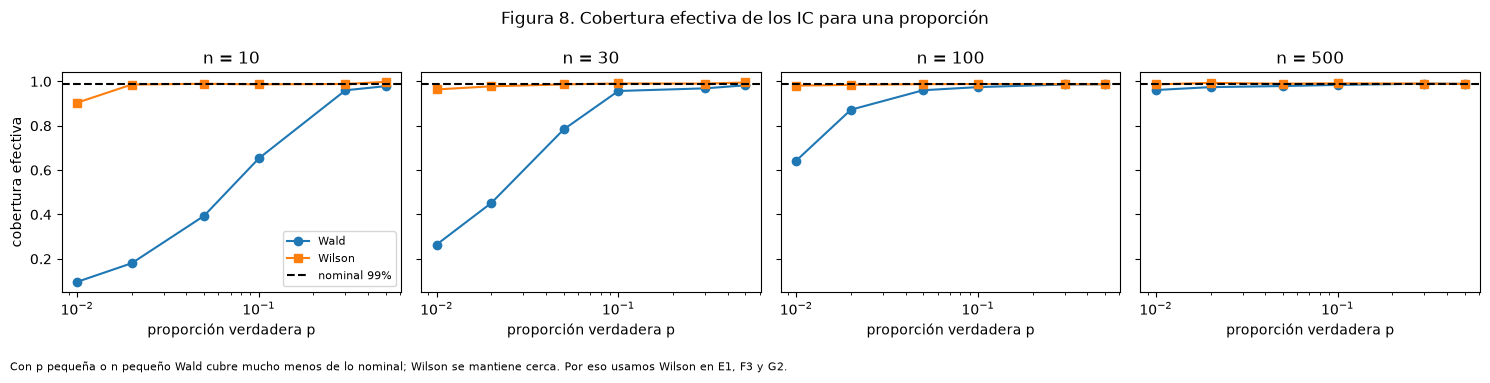

In [61]:
# Parte F · F4 — Cobertura real de Wald y Wilson con 10⁴ réplicas binomiales por escenario
R4 = 10_000
ns = [10, 30, 100, 500]
ps = [0.01, 0.02, 0.05, 0.10, 0.30, 0.50]
filas = []
for n in ns:
    for p in ps:
        X = rng.binomial(n, p, R4)
        _, lw, uw = ic_wald(X, n)
        _, ls, us = ic_wilson(X, n)
        filas.append({"n": n, "p": p,
                      "Wald": np.mean((lw <= p) & (p <= uw)),
                      "Wilson": np.mean((ls <= p) & (p <= us))})
tabla_f4 = pd.DataFrame(filas)
print(tabla_f4.pivot(index="p", columns="n", values=["Wald", "Wilson"]).round(3))

fig, axs = plt.subplots(1, len(ns), figsize=(15, 3.5), sharey=True)
for ax, n in zip(axs, ns):
    t = tabla_f4[tabla_f4["n"] == n]
    ax.plot(t["p"], t["Wald"], "o-", label="Wald")
    ax.plot(t["p"], t["Wilson"], "s-", label="Wilson")
    ax.axhline(conf, color="k", ls="--", label=f"nominal {conf:.0%}")
    ax.set_xscale("log")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("proporción verdadera p")
axs[0].set_ylabel("cobertura efectiva")
axs[0].legend(fontsize=8)
fig.suptitle("Figura 8. Cobertura efectiva de los IC para una proporción")
plt.figtext(0.01, -0.05, "Con p pequeña o n pequeño Wald cubre mucho menos de lo nominal; "
            "Wilson se mantiene cerca. Por eso usamos Wilson en E1, F3 y G2.", fontsize=8)
plt.tight_layout()
plt.show()
params["metodo_ic_prop"] = "wilson"

✍️ *[Figura 8 — pie de figura: pegue aquí su texto]*

✍️ *[F4 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## F5 · Tamaño de muestra para un semiancho de 1 ms en F3(i)

✍️ *[F5 — planteamiento: pegue aquí su texto]*

✍️ *[F5 — deducción a mano: pegue aquí su texto]*

In [62]:
# Parte F · F5 — n por versión = ⌈z² (sA² + sB²) / 1²⌉ con z de Bonferroni; verificación por simulación
z_bonf = stats.norm.ppf(1 - (alpha / 3) / 2)
sA2, sB2 = gA.var(ddof=1), gB.var(ddof=1)
# El semiancho debe ser de 1 ms como máximo en el cálculo de planificación. Se redondea hacia arriba por versión.
n_req = int(np.ceil(z_bonf**2 * (sA2 + sB2) / 1.0**2))
print(f"sA² = {sA2:.1f}, sB² = {sB2:.1f}, z = {z_bonf:.4f}  ->  n por versión = {n_req}")

# Cada réplica remuestrea n_req observaciones por versión y calcula el semiancho del intervalo.
semis = []
for _ in range(2000):
    a = rng.choice(gA.to_numpy(), n_req)
    b = rng.choice(gB.to_numpy(), n_req)
    d, lo, hi = ic_dif_welch(a, b, conf_bonf)
    semis.append((hi - lo) / 2)
semis = np.array(semis)
print(f"Semiancho simulado: mediana={np.median(semis):.3f} ms, "
      f"P(semiancho <= 1) = {np.mean(semis <= 1):.3f}")

sA² = 1135.9, sB² = 1031.3, z = 2.9352  ->  n por versión = 18672


Semiancho simulado: mediana=1.000 ms, P(semiancho <= 1) = 0.516


✍️ *[F5 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## F6 · Validación con solicitudes_validacion.csv

✍️ *[F6 — planteamiento: pegue aquí su texto]*

In [63]:
# Parte F · F6 — ÚNICO acceso a la ventana de validación (se descomprime y verifica aquí)
# Se aplica exactamente la misma limpieza de A1 y se compara cada parámetro con su IC.
# F6 es el único acceso al CSV de validación. Se usa exactamente la limpieza de A1.
# La auditoría de la segunda ventana reutiliza la función de limpieza de A1.
df_val = limpiar(pd.read_csv(io.BytesIO(abrir_validacion("F6"))))
tv = df_val.t_llegada_s.to_numpy()
cuentas_val = np.histogram(tv,bins=np.arange(0,1200+10,10))[0]
d_val = ((cuentas_val-cuentas_val.mean())**2/cuentas_val.mean()).sum()
p_disp_val = stats.chi2.sf(d_val,len(cuentas_val)-1)
print(f"Dispersión por 10 s p={p_disp_val:.4f}. Ventana de validación completa de 1200 s.")
def f6_datos(d, dur):
    gpu = d.loc[d.cache_hit.eq(0),"gpu_ms"].dropna()
    red = d.red_ms.dropna()
    lat = d.latencia_ms.dropna()
    intentos = d.intentos.dropna()
    cache_d = d.cache_hit.dropna()
    return {"tasa":len(d)/dur,"gpu":gpu,"red":red,"lat":lat,"reintentos":intentos.gt(1),
            "cache":cache_d.eq(1),"violaciones":lat.gt(tau)}
ve, vv = f6_datos(df_estable,dur_estable), f6_datos(df_val,1200)
f6_cambios = {}
for metrica in ["gpu","red","lat"]:
    a_f6,b_f6 = ve[metrica],vv[metrica]
    f6_cambios[metrica] = ic_dif_welch(a_f6,b_f6,conf)
    print(metrica, "cambio (IC Welch)",f6_cambios[metrica],"p KS",stats.ks_2samp(a_f6,b_f6).pvalue)
for metrica in ["reintentos","cache","violaciones"]:
    a_f6,b_f6 = ve[metrica],vv[metrica]
    f6_cambios[metrica] = ic_dif_newcombe(a_f6.sum(),len(a_f6),b_f6.sum(),len(b_f6),conf)
    print(metrica,"cambio (IC Newcombe)",f6_cambios[metrica])
dif_tasa = vv["tasa"]-ve["tasa"]
ee_tasa = np.sqrt(len(df_val)/1200**2+len(df_estable)/dur_estable**2)
f6_cambios["tasa"] = (dif_tasa,dif_tasa-z*ee_tasa,dif_tasa+z*ee_tasa)
carga_validacion = vv["tasa"]*(1-vv["cache"].mean())*vv["gpu"].mean()/1000
carga_referencia = ve["tasa"]*(1-ve["cache"].mean())*ve["gpu"].mean()/1000
print("Tasas de ambas ventanas (sol/s), diferencia e IC:",ve["tasa"],vv["tasa"],f6_cambios["tasa"])
print(f"Carga ofrecida {carga_referencia:.4f} → {carga_validacion:.4f} GPUs equivalentes. F6 solo evalúa sensibilidad, G se calibra con producción.")
cambiaron_F6 = [m for m, (d, lo, hi) in f6_cambios.items() if lo > 0 or hi < 0]
print(f"Conclusión F6 (calculada): parámetros con cambio significativo al {conf:.0%}: {cambiaron_F6 or 'ninguno'}")

  solicitudes_validacion (1).csv: 1,226,875 bytes, SHA-256 verificado (cd9f744ee210ac62…)
Dispersión por 10 s p=0.4797. Ventana de validación completa de 1200 s.
gpu cambio (IC Welch) (np.float64(0.09398840405920339), np.float64(-0.8643913155054015), np.float64(1.0523681236238083)) p KS 0.4468171609008975
red cambio (IC Welch) (np.float64(-0.021759631974699545), np.float64(-0.10765364957516159), np.float64(0.0641343856257625)) p KS 0.7143417371780447
lat cambio (IC Welch) (np.float64(-0.2797846720920347), np.float64(-1.20352264090642), np.float64(0.6439532967223505)) p KS 0.5567746609180546
reintentos cambio (IC Newcombe) (np.float64(0.04428013365666483), np.float64(0.03544133121155679), np.float64(0.053072162844436103))
cache cambio (IC Newcombe) (np.float64(0.0028802440142224883), np.float64(-0.008308817315463023), np.float64(0.014044666430195665))
violaciones cambio (IC Newcombe) (np.float64(2.5395996912228004e-05), np.float64(-0.0010393688634215913), np.float64(0.001026792418319539

✍️ *[F6 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

# Parte G — Simulación de Montecarlo y decisión de capacidad

✍️ *[Parte G — introducción: pegue aquí su texto]*

In [64]:
# Parte G · Constantes del escenario (alias de la primera celda; nada se recalcula)
import heapq, json
from scipy import optimize, special
C0 = 2               # GPUs actuales
g_grupo = g          # crecimiento del tráfico (1.9)
tau_grupo = tau      # umbral del SLO (260 ms)
eps_grupo = eps      # tolerancia del SLO (0.03)
conf_grupo = conf    # nivel de confianza (0.99)

In [65]:
# Parte G · Ajuste de los parámetros del simulador (modelo marginal y estructural de C y D)
est = df_estable.copy()
DUR_ESTABLE = dur_estable

def mle_gamma(x):
    """MLE de Gamma(k, theta): resuelve log k − digamma(k) = log(media) − media(log x)."""
    x = np.asarray(x, float)
    s = np.log(x.mean()) - np.log(x).mean()
    k = optimize.brentq(lambda k: np.log(k) - special.digamma(k) - s, 1e-3, 1e4)
    return k, x.mean() / k

def mle_lognormal(x):
    lx = np.log(np.asarray(x, float))
    return lx.mean(), lx.std(ddof=0)

CORTES_TAM = None  # deciles de tam_kb para P(caché | tam); se fijan con los datos originales

def mle_gamma_condicional(x, medias):
    """MLE de la forma kappa de G | tam ~ Gamma(kappa, media_i/kappa), con medias lineales fijas."""
    x, m = np.asarray(x, float), np.asarray(medias, float)
    nll = lambda lk: -np.sum(stats.gamma.logpdf(x, np.exp(lk), scale=m / np.exp(lk)))
    return float(np.exp(optimize.minimize_scalar(nll, bounds=(-3, 6), method="bounded").x))

def ajustar(d, n_llegadas=None):
    """Parámetros del simulador. Incluye el modelo marginal (h, Gamma, Lognormal) y el estructural
    de las Partes C y D: tam -> P(caché | tam) -> G | tam ~ Gamma con media lineal en tam;
    red = desplazamiento + Gamma."""
    global CORTES_TAM
    n = len(d) if n_llegadas is None else n_llegadas
    h = d["cache_hit"].dropna().mean()
    gnc = d.loc[d["cache_hit"] == 0, "gpu_ms"].dropna()
    k, th = mle_gamma(gnc)
    mu, sg = mle_lognormal(d["red_ms"].dropna())
    # --- estructural ---
    dd = d.dropna(subset=["tam_kb", "cache_hit"])
    if CORTES_TAM is None:
        CORTES_TAM = np.quantile(dd.tam_kb, np.linspace(0, 1, 11)[1:-1])
    p_cache = dd.groupby(np.digitize(dd.tam_kb, CORTES_TAM)).cache_hit.mean().reindex(range(10)).fillna(h).to_numpy()
    nc = d[(d.cache_hit == 0)].dropna(subset=["tam_kb", "gpu_ms"])
    X = np.column_stack([np.ones(len(nc)), nc.tam_kb])
    a, b = np.linalg.solve(X.T @ X, X.T @ nc.gpu_ms.to_numpy())       # media lineal de G | tam
    kappa = mle_gamma_condicional(nc.gpu_ms, a + b * nc.tam_kb)
    kr, loc_r, th_r = stats.gamma.fit(d["red_ms"].dropna())             # red = loc + Gamma
    return dict(lam=n / DUR_ESTABLE, h=h, k=k, theta=th, mu_red=mu, sd_red=sg,
                p_cache=p_cache, a=a, b=b, kappa=kappa, kr=kr, loc_r=loc_r, th_r=th_r,
                tam=dd.tam_kb.to_numpy())

param_g = ajustar(est)
EG = param_g["k"] * param_g["theta"]
rho_base = param_g["lam"] * (1 - param_g["h"]) * EG / 1000 / C0
print("Parámetros del simulador:", {k: (round(float(v), 5) if np.isscalar(v) else "array")
                                    for k, v in param_g.items()})
print(f"E[G | no caché] = {EG:.2f} ms;  carga por GPU con c=2: rho = {rho_base:.3f}")

evid = est.assign(espera=est.latencia_ms - est.red_ms - est.gpu_ms) \
          .groupby("intentos")[["gpu_ms", "latencia_ms", "espera"]].mean().round(2)
evid["n"] = est["intentos"].value_counts().sort_index()
print("Evidencia sobre reintentos (medias por número de intentos):\n", evid)

Parámetros del simulador: {'lam': 21.79372, 'h': 0.31653, 'k': 2.41618, 'theta': 19.16861, 'mu_red': 3.13959, 'sd_red': 0.15751, 'p_cache': 'array', 'a': 15.71176, 'b': 0.11715, 'kappa': 3.99693, 'kr': 12482.27503, 'loc_r': -375.97215, 'th_r': 0.03199, 'tam': 'array'}
E[G | no caché] = 46.31 ms;  carga por GPU con c=2: rho = 0.345
Evidencia sobre reintentos (medias por número de intentos):
           gpu_ms  latencia_ms  espera      n
intentos                                    
1.0        31.72        58.33    3.24  17867
2.0        31.52        58.37    3.47   2502
3.0        30.14        56.68    3.06    444


In [66]:
# Parte G · Simulador FIFO con c GPUs programado a mano. Cada réplica recibe su propio
# generador hijo de rng (rng.spawn), así las réplicas son independientes y reproducibles.
def simular(c, lam, p, T, rng_rep, warmup=300.0, muestras=None, modelo="estructural"):
    """Una réplica independiente. Devuelve el arreglo de latencias L (ms) tras el calentamiento.
    modelo='estructural' (Partes C y D) o 'marginal' (h, Gamma y Lognormal sin tamaño).
    muestras: si se pasa (dict con arrays 'gpu' y 'red'), remuestrea datos reales en lugar del modelo."""
    n = rng_rep.poisson(lam * T)
    llegadas = np.sort(rng_rep.uniform(0.0, T, n))             # Poisson condicionado a n
    if muestras is None and modelo == "estructural":
        tam = rng_rep.choice(p["tam"], n)
        cache = rng_rep.random(n) < p["p_cache"][np.digitize(tam, CORTES_TAM)]
        gpu = rng_rep.gamma(p["kappa"], (p["a"] + p["b"] * tam) / p["kappa"])
        red = p["loc_r"] + rng_rep.gamma(p["kr"], p["th_r"], n)
    elif muestras is None:
        cache = rng_rep.random(n) < p["h"]
        red = rng_rep.lognormal(p["mu_red"], p["sd_red"], n)
        gpu = rng_rep.gamma(p["k"], p["theta"], n)
    else:
        cache = rng_rep.random(n) < p["h"]
        red = rng_rep.choice(muestras["red"], n)
        gpu = rng_rep.choice(muestras["gpu"], n)
    espera = np.zeros(n)
    libres = [0.0] * c                                         # instante (s) en que cada GPU queda libre
    idx = np.flatnonzero(~cache)
    llg, srv = llegadas[idx], gpu[idx] / 1000.0
    esp = np.empty(len(idx))
    for j in range(len(idx)):                                  # cola FIFO, c servidores
        primera = libres[0]
        # El servicio empieza en el mayor de dos instantes: llegada y disponibilidad de la primera GPU.
        inicio = llg[j] if llg[j] > primera else primera
        esp[j] = inicio - llg[j]
        # La cola de prioridad se actualiza con el instante en que la GPU completará el servicio.
        heapq.heapreplace(libres, inicio + srv[j])
    espera[idx] = esp * 1000.0
    L = np.where(cache, red + rng_rep.uniform(1.0, 3.0, n), red + espera + gpu)
    return L[llegadas >= warmup]

def muestras_g(d):
    return {"gpu":d.loc[d.cache_hit.eq(0),"gpu_ms"].dropna().to_numpy(),
            "red":d.red_ms.dropna().to_numpy()}

## G1 · Simulador y validación con dos GPUs

✍️ *[G1 — planteamiento: pegue aquí su texto]*

,real,estructural,empírico
p50,50.460000,50.261979,50.401503
p90,108.100000,107.744293,108.180000
p95,133.040000,131.609681,132.460000
p99,187.020000,188.108106,188.374006
p99.9,282.127000,272.352297,280.380478
P(L>tau),0.001691,0.001405,0.001480


Modelo para proyección por error absoluto de cola G1: empírico {'estructural': np.float64(0.0002858704333446257), 'empírico': np.float64(0.00021067697502260793)}


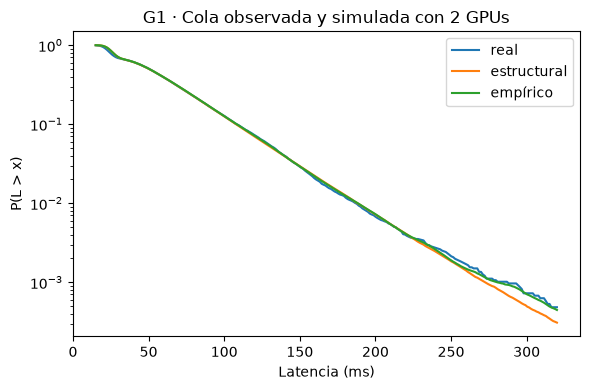

In [67]:
# Parte G · G1 — Validación con c = 2: cuantiles y P(L > tau) reales frente a simulados
rep_g1 = 30
reales = est.latencia_ms.dropna().to_numpy()
mues_g = muestras_g(est)
g1 = {"real":reales}
for tipo in ("estructural","empírico"):
    g1[tipo] = np.concatenate([simular(2,param_g["lam"],param_g,1800,h,warmup=180,
                              muestras=mues_g if tipo=="empírico" else None) for h in rng.spawn(rep_g1)])
valid_g = pd.DataFrame({k:[*np.quantile(v,[.5,.9,.95,.99,.999]),np.mean(v>tau_grupo)]
                        for k,v in g1.items()},index=["p50","p90","p95","p99","p99.9","P(L>tau)"])
display(valid_g)
# Selección del modelo con menor error absoluto en la proporción de latencias sobre el umbral.
e_real = valid_g.loc["P(L>tau)","real"]
dist = {k:abs(valid_g.loc["P(L>tau)",k]-e_real) for k in ("estructural","empírico")}
modelo_g = min(dist,key=dist.get)
print("Modelo para proyección por error absoluto de cola G1:",modelo_g,dist)
fig,ax=plt.subplots(figsize=(6,4))
for k,v in g1.items():
    xx=np.linspace(15,320,250)
    ax.plot(xx,1-np.searchsorted(np.sort(v),xx,side="right")/len(v),label=k)
ax.set(xlabel="Latencia (ms)",ylabel="P(L > x)",yscale="log",title="G1 · Cola observada y simulada con 2 GPUs")
ax.legend()
fig.tight_layout()
plt.show()

✍️ *[Figura G1 — pie de figura: pegue aquí su texto]*

✍️ *[G1 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## G2 · Escenario de crecimiento (tasa × g) y número de GPUs

✍️ *[G2 — planteamiento: pegue aquí su texto]*

,rho,p,lo,hi,R
GPUs,,,,,
1,1.310756,NaN,NaN,NaN,0
2,0.655378,0.011944,0.011369,0.012519,40
3,0.436919,0.001268,0.001216,0.001320,40
4,0.327689,0.001048,0.001001,0.001096,40
5,0.262151,0.001022,0.000979,0.001066,40


c* por extremo superior: 2


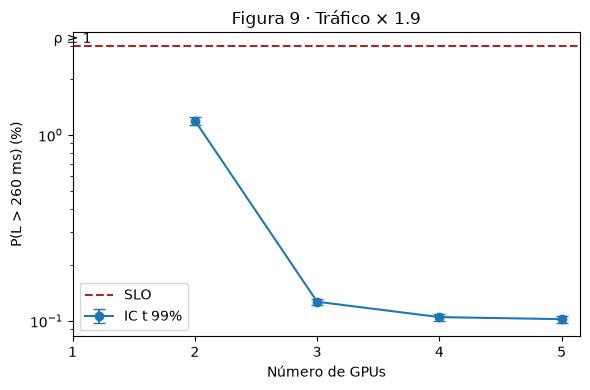

Conclusión G2 (calculada): con tráfico × 1.9 se necesitan c* = 2 GPUs: P(L > 260 ms) = 1.1944% [1.1369%, 1.2519%] ≤ ε = 3%


In [68]:
# Parte G · G2 — P(L > tau) para c = 1..5 con tráfico × g, IC t sobre 40 réplicas independientes;
# c* = menor c cuyo extremo superior del IC queda por debajo de eps.
def replicar_g(c, p, muestras, cantidad, horizonte):
    return np.asarray([np.mean(simular(c,p["lam"]*g_grupo,p,horizonte,h,warmup=180,
                          muestras=muestras if modelo_g=="empírico" else None)>tau_grupo)
                       for h in rng.spawn(cantidad)])

candidatos_g = range(1,6)
filas_g = []
for c in candidatos_g:
    rho = g_grupo*param_g["lam"]*(1-param_g["h"])*EG/(1000*c)
    # Una carga de 1 o más deja a las GPUs sin margen para vaciar la cola en el modelo estacionario.
    if rho >= 1:
        filas_g.append((c,rho,np.nan,np.nan,np.nan,0))
        continue
    # Réplicas independientes y horizonte que deja 42 min útiles por réplica.
    pro = replicar_g(c,param_g,mues_g,40,2700)
    mg,lo_g,hi_g = ic_media(pro,conf_grupo)
    filas_g.append((c,rho,mg,max(0,lo_g),min(1,hi_g),len(pro)))
g2 = pd.DataFrame(filas_g,columns=["GPUs","rho","p","lo","hi","R"]).set_index("GPUs")
# Se selecciona el menor número de GPUs cuyo límite superior del intervalo cumple el SLO.
c_g = next(iter(g2.index[g2.hi.le(eps_grupo)]),None)
display(g2)
print("c* por extremo superior:",c_g)
fig,ax=plt.subplots(figsize=(6,4))
g2_ok=g2.dropna()
ax.errorbar(g2_ok.index,100*g2_ok.p,yerr=100*np.array([g2_ok.p-g2_ok.lo,g2_ok.hi-g2_ok.p]),
            fmt="o-",capsize=4,label=f"IC t {conf_grupo:.0%}")
ax.axhline(100*eps_grupo,color="firebrick",ls="--",label="SLO")
ax.set(xlabel="Número de GPUs",ylabel=f"P(L > {tau_grupo} ms) (%)",xticks=list(candidatos_g),
       title=f"Figura 9 · Tráfico × {g_grupo:.1f}")
for c in g2.index[g2.R.eq(0)]:
    ax.text(c,100*eps_grupo,"ρ ≥ 1",ha="center",va="bottom")
ax.set_yscale('log')
ax.legend()
fig.tight_layout()
plt.show()
if c_g is not None:
    print(f"Conclusión G2 (calculada): con tráfico × {g_grupo} se necesitan c* = {c_g} GPUs: "
          f"P(L > {tau_grupo} ms) = {g2.loc[c_g, 'p']:.4%} [{g2.loc[c_g, 'lo']:.4%}, {g2.loc[c_g, 'hi']:.4%}] ≤ ε = {eps_grupo:.0%}")
else:
    print("Conclusión G2 (calculada): ningún c entre 1 y 5 cumple el SLO con confianza")

✍️ *[Figura 9 — pie de figura: pegue aquí su texto]*

✍️ *[G2 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## G3 · Incertidumbre paramétrica y referencia M/M/c

✍️ *[G3 — planteamiento: pegue aquí su texto]*

In [69]:
# Parte G · G3 — Bootstrap de los parámetros (100 muestras) para la distribución de c*
# y modelo analítico M/M/c (Erlang C) como referencia.
# Remuestreo por filas para ajustar marcas y por Poisson para estimar la tasa.
# c* bootstrap usa estimaciones puntuales condicionales. La dispersión incorpora error interior.
# Cada remuestra produce una nueva estimación de la capacidad mínima.
conteo_c = {}
diferencias_mc = []
for _ in range(100):
    muestra = est.iloc[rng.integers(0,len(est),len(est))]
    pb_g = ajustar(muestra,rng.poisson(len(est)))
    marcas_b = muestras_g(muestra)
    numero = None
    for c in candidatos_g:
        if g_grupo*pb_g["lam"]*(1-pb_g["h"])*pb_g["k"]*pb_g["theta"]/(1000*c)>=1:
            continue
        prop_b = replicar_g(c,pb_g,marcas_b,8,1800)
        if prop_b.mean()<=eps_grupo:
            numero = c
            break
    clave = str(numero) if numero is not None else ">5"
    conteo_c[clave]=conteo_c.get(clave,0)+1
print("Distribución de c* bootstrap (100 muestras):",conteo_c)

def mmc(c):
    mu=1000/EG
    lam_nc=g_grupo*param_g["lam"]*(1-param_g["h"])
    a=lam_nc/mu
    if a>=c:
        return np.nan
    cola=a**c/special.factorial(c)*c/(c-a)
    C=cola/(sum(a**k/special.factorial(k) for k in range(c))+cola)
    beta=c*mu-lam_nc
    tt=(tau_grupo-est.red_ms.mean())/1000
    suma=np.exp(-mu*tt)*(1+mu*tt) if abs(beta-mu)<1e-9 else (beta*np.exp(-mu*tt)-mu*np.exp(-beta*tt))/(beta-mu)
    return (1-param_g["h"])*((1-C)*np.exp(-mu*tt)+C*suma)
g2["p_MMc"]=[mmc(c) for c in g2.index]
display(g2)
print("M/M/c impone servicio exponencial y red constante. La cola empírica preserva la distribución observada de servicio, sin modelar cambios bajo saturación.")
c_mmc = next((int(c) for c in g2.index if pd.notna(g2.loc[c, "p_MMc"]) and g2.loc[c, "p_MMc"] <= eps_grupo), None)
frac_c = conteo_c.get(str(c_g), 0) / sum(conteo_c.values())
print(f"Conclusión G3 (calculada): c* = {c_g} en {frac_c:.0%} de las muestras bootstrap; "
      f"M/M/c daría c* = {c_mmc} (P M/M/c con {c_g} GPUs = {g2.loc[c_g, 'p_MMc']:.4f} frente a ε = {eps_grupo})")

Distribución de c* bootstrap (100 muestras): {'2': 100}


,rho,p,lo,hi,R,p_MMc
GPUs,,,,,,
1,1.310756,NaN,NaN,NaN,0,NaN
2,0.655378,0.011944,0.011369,0.012519,40,0.030970
3,0.436919,0.001268,0.001216,0.001320,40,0.005140
4,0.327689,0.001048,0.001001,0.001096,40,0.004249
5,0.262151,0.001022,0.000979,0.001066,40,0.004147


M/M/c impone servicio exponencial y red constante. La cola empírica preserva la distribución observada de servicio, sin modelar cambios bajo saturación.
Conclusión G3 (calculada): c* = 2 en 100% de las muestras bootstrap; M/M/c daría c* = 3 (P M/M/c con 2 GPUs = 0.0310 frente a ε = 0.03)


✍️ *[G3 — conclusión: pegue aquí su texto (las cifras están en la salida de arriba)]*

## Resumen reproducible A–G

✍️ *[Resumen — texto opcional]*

In [70]:
# Resumen reproducible de A a G (se guarda en memoria como JSON; no se escribe ningún archivo)
def nativo(o):
    if isinstance(o,dict): return {str(k):nativo(v) for k,v in o.items()}
    if isinstance(o,(tuple,list)): return [nativo(v) for v in o]
    if isinstance(o,np.generic): return o.item()
    return o
resumen_final = dict(
    datos=[len(crudo),len(mon),len(df_val)],
    a=dict(limpios=len(est)+len(df_reg2),estable=len(est),cortes=[TAU1,TAU2],dur=dur_estable,
           tasas=[len(df[df.segmento==s])/(fin-a) for a,fin,s in SEGMENTOS],
           bic=modelos.BIC.tolist(),auditoria=tabla_A1["filas"].to_dict(),pearson_sens=comparacion_tam),
    b=dict(tasa=lambda_hat,ic=ic_lambda,pks=p_ks_b1,pdisp=p_dis_b1, bloques=tabla_b2.to_dict("records"),
           p=p_mle,ic_p=ic_p,k=k_val,prob=prob_analitica,mc=prob_mc),
    c=dict(h=h_hat,gpu=G_c.mean(),gamma=[k_mv,th_mv],media_mixta=G_todas.mean(),
           red=p999_emp,ic_red=[orden[l-1],orden[min(u,n_red)-1]],c4=res_N,ks=p_ks_gam),
    d=dict(pearson=r_xy,ic=[r_lo,r_hi],pendiente=beta[1],pendiente_hc3=[beta[1]-stats.t.ppf(1-alpha/2,n3-2)*ee_hc3[1],beta[1]+stats.t.ppf(1-alpha/2,n3-2)*ee_hc3[1]],explicada=tabla_D2.iloc[0]["fracción explicada"],v=V,p=p_ind_tam),
    e=dict(regla=recomendada,prob=e4.loc[recomendada,"P(X<=kmax) puntual"],peor=e4.loc[recomendada,"P(X<=kmax) peor caso"],
           sensibilidad=e1.loc[recomendada,"sens"],cumple=bool(e4.cumple.any()),max=kmax),
    f=dict(diferencias=f3,latencia=[m_bm,lo_bm,hi_bm],n_f5=n_req,n_tlc=n_min,validacion=f6_cambios,disp_validacion=p_disp_val),
    g=dict(c=c_g,crecimiento=g_grupo,tau=tau_grupo,eps=eps_grupo,conf=conf_grupo,
           modelo=modelo_g,validacion=valid_g.to_dict(),tabla=g2.replace({np.nan:None}).to_dict("index"),bootstrap=conteo_c))
resumen_final = nativo(resumen_final)
resumen_json = json.dumps(resumen_final, ensure_ascii=False, indent=2, allow_nan=False)
print(f"Resumen JSON en memoria: {len(resumen_json):,} caracteres")
display(pd.DataFrame(g2))

Resumen JSON en memoria: 6,095 caracteres


,rho,p,lo,hi,R,p_MMc
GPUs,,,,,,
1,1.310756,NaN,NaN,NaN,0,NaN
2,0.655378,0.011944,0.011369,0.012519,40,0.030970
3,0.436919,0.001268,0.001216,0.001320,40,0.005140
4,0.327689,0.001048,0.001001,0.001096,40,0.004249
5,0.262151,0.001022,0.000979,0.001066,40,0.004147


## G4 · Memorando ejecutivo para el CTO

✍️ *[G4 — planteamiento: pegue aquí su texto]*

In [71]:
# Parte G · G4 — Cifras del memorando: cada número sale de una celda anterior (trazabilidad)
def nf(x, d=2):
    """Número con coma decimal (formato en español)."""
    return f"{x:,.{d}f}".replace(",", "§").replace(".", ",").replace("§", " ")

def pc(x, d=1):
    """Proporción como porcentaje con coma decimal."""
    return nf(100 * x, d) + " %"

def ic_txt(est, lo, hi, d=2, pct=False):
    f = (lambda v: pc(v, d)) if pct else (lambda v: nf(v, d))
    return f"{f(est)} [{f(lo)}; {f(hi)}]"

# Parte A: régimen y pico
tasa_pico = len(s2) / (TAU2 - TAU1)
lat_pico, lat_est = s2.latencia_ms.mean(), estable.latencia_ms.mean()
# Hoy (G1): proporción real de violaciones con IC de Wilson
p_hoy, p_hoy_lo, p_hoy_hi = ic_wilson((reales > tau).sum(), len(reales))
# Capacidad (G2/G3)
fila_c = g2.loc[c_g] if c_g is not None else None
carga_g = g_grupo * param_g["lam"] * (1 - param_g["h"]) * EG / 1000      # Erlangs en el escenario × g
carga_pico_g = g_grupo * tasa_pico * (1 - param_g["h"]) * EG / 1000     # Erlangs si el pico crece × g
gpus_pico = int(np.floor(carga_pico_g)) + 1
# Alertas (E)
regla_txt = recomendada.replace("_y_", " y ").replace("_o_", " o ")
# Versión B (F3)
d_gpu, lo_gpu, hi_gpu = f3["(i) GPU media (ms)"]
d_rei, lo_rei, hi_rei = f3["(ii) P(intentos>1)"]
d_lat, lo_lat, hi_lat = f3["(iii) P(L>tau)"]
# Validación (F6)
d_rv, lo_rv, hi_rv = f6_cambios["reintentos"]

cifras_memo = pd.DataFrame([
    ("A2", "cambios de régimen (s)", f"{nf(TAU1,1)} y {nf(TAU2,1)}"),
    ("A2", "tasa en el pico (sol/s)", nf(tasa_pico, 2)),
    ("B1", f"tasa estable λ (sol/s), IC {conf:.0%}", ic_txt(lambda_hat, *ic_lambda, d=3)),
    ("B3", f"p fallo por intento, IC {conf:.0%}", ic_txt(p_mle, *ic_p, d=4)),
    ("C1", f"h = P(caché), IC {conf:.0%}", ic_txt(h_hat, h_lo, h_hi, d=4)),
    ("F2", f"latencia media (ms), IC {conf:.0%} por lotes", ic_txt(m_bm, lo_bm, hi_bm)),
    ("G1", f"P(L > {tau} ms) hoy, Wilson {conf:.0%}", ic_txt(p_hoy, p_hoy_lo, p_hoy_hi, d=3, pct=True)),
    ("F3", "GPU B − A (ms), Bonferroni", ic_txt(d_gpu, lo_gpu, hi_gpu)),
    ("F3", "decisión", decision_F3),
    ("F5", "n por versión (semiancho 1 ms)", f"{n_req:,}".replace(",", " ")),
    ("G2", f"c* (tráfico × {g_grupo})", str(c_g)),
    ("G2", f"P(L > {tau} ms) con c*", ic_txt(fila_c.p, fila_c.lo, fila_c.hi, d=3, pct=True) if fila_c is not None else "—"),
    ("G3", "c* bootstrap", str(conteo_c)),
    ("G3", "c* según M/M/c", str(c_mmc)),
    ("E4", "regla recomendada", regla_txt),
    ("E4", f"P(FA ≤ {kmax}) puntual / peor caso", f"{nf(e4.loc[recomendada,'P(X<=kmax) puntual'],4)} / {nf(e4.loc[recomendada,'P(X<=kmax) peor caso'],4)}"),
    ("F6", "cambio en P(intentos>1), validación − original", ic_txt(d_rv, lo_rv, hi_rv, d=2, pct=True)),
], columns=["ítem", "cifra", "valor"])
display(cifras_memo)

,ítem,cifra,valor
0,A2,cambios de régimen (s),"485,0 y 730,0"
1,A2,tasa en el pico (sol/s),"47,73"
2,B1,"tasa estable λ (sol/s), IC 99%","21,768 [21,379; 22,157]"
3,B3,"p fallo por intento, IC 99%","0,1427 [0,1368; 0,1485]"
4,C1,"h = P(caché), IC 99%","0,3163 [0,3080; 0,3247]"
5,F2,"latencia media (ms), IC 99% por lotes","58,30 [57,19; 59,41]"
6,G1,"P(L > 260 ms) hoy, Wilson 99%","0,169 % [0,110 %; 0,260 %]"
7,F3,"GPU B − A (ms), Bonferroni","-3,01 [-4,63; -1,39]"
8,F3,decisión,adoptar B
9,F5,n por versión (semiancho 1 ms),18 672


In [72]:
# Parte G · G4 — Memorando ejecutivo generado con las cifras calculadas.
# El texto se reconstruye en cada ejecución a partir de las variables de A–G y de las constantes del grupo.
from IPython.display import Markdown

cumple_E = bool(e4.cumple.any())
frase_E = (f"La regla **{regla_txt}** cumple la exigencia y es la que más incidentes detecta."
           if cumple_E else
           f"**Ninguna regla cumple** la exigencia con el criterio conservador. La más cercana es **{regla_txt}**: "
           f"P(≤ {kmax} falsas alarmas al día) = {nf(e4.loc[recomendada,'P(X<=kmax) puntual'],3)} en la estimación puntual, "
           f"pero solo {nf(e4.loc[recomendada,'P(X<=kmax) peor caso'],3)} en el peor caso razonable al {pc(conf,0)}.")
frase_B = {"adoptar B": "**Sí, recomendamos adoptar la versión B.**",
           "no adoptar B": "**No recomendamos adoptar la versión B.**",
           "sin evidencia para cambiar a B": "**No hay evidencia suficiente para cambiar a B.**"}[decision_F3]
frase_pico = (f"Una ráfaga como la observada ({nf(tasa_pico,1)} sol/s), crecida × {nf(g_grupo,1)}, ofrecería {nf(carga_pico_g,2)} Erlangs: "
              f"con {c_g} GPUs ρ = {nf(carga_pico_g/c_g,2)}"
              + (", es decir, la cola **crecería sin límite** durante la ráfaga" if carga_pico_g / c_g >= 1 else "")
              + f". Solo para que esa ráfaga sea estable harían falta {gpus_pico} GPUs.")

frase_hoy = ("muy por debajo" if p_hoy_hi < eps / 2 else ("por debajo" if p_hoy_hi <= eps else "por encima")) + f" del límite de {pc(eps,0)}"
def _sin_dif(lo, hi):
    return "no hay diferencia demostrable" if lo <= 0 <= hi else ("B es mejor" if hi < 0 else "B es peor")
frase_c1 = (f"una sola GPU sería inestable (ρ = {nf(g2.loc[1,'rho'],2)})" if g2.loc[1, "rho"] >= 1
            else f"con una sola GPU ρ = {nf(g2.loc[1,'rho'],2)}")
frase_mmc = ("coincide con el simulador" if c_mmc == c_g else
             ("es más pesimista" if (c_mmc is None or c_mmc > c_g) else "es más optimista"))
_tab_fp = pd.crosstab(mon.loc[~inc, "D1"], mon.loc[~inc, "D2"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
odds_fp, p_fp = stats.fisher_exact(_tab_fp.values)
frase_dep = (f"Las falsas alarmas de D1 y D2 no son independientes (odds ratio {nf(odds_fp,1)}, Fisher p = {f"{p_fp:.1e}".replace(".", ",")}), "
             "así que combinar reglas rinde menos de lo que sugeriría el producto de probabilidades."
             if p_fp < alpha else "No hay evidencia de dependencia entre las falsas alarmas de D1 y D2.")

NOMBRES_F6 = {"gpu": "el tiempo de GPU", "red": "el tiempo de red", "lat": "la latencia", "reintentos": "la proporción de solicitudes con reintento",
              "cache": "la proporción de caché", "violaciones": f"P(L > {tau} ms)", "tasa": "la tasa de llegadas"}
def _lista(cl):
    nombres = [NOMBRES_F6[c] for c in cl]
    return nombres[0] if len(nombres) == 1 else ", ".join(nombres[:-1]) + " y " + nombres[-1]
estables_F6 = [m for m in NOMBRES_F6 if m not in cambiaron_F6]
frase_F6 = (f"En la ventana de validación no cambian de forma significativa {_lista(estables_F6)}" if estables_F6 else "En la ventana de validación cambian todos los parámetros")
if cambiaron_F6:
    frase_F6 += "; sí cambia " + "; ".join(
        f"{NOMBRES_F6[m]} ({(pc(f6_cambios[m][0],2) if m in ('reintentos','cache','violaciones') else nf(f6_cambios[m][0],3))}; "
        f"IC {(pc(f6_cambios[m][1],2) if m in ('reintentos','cache','violaciones') else nf(f6_cambios[m][1],3))} a "
        f"{(pc(f6_cambios[m][2],2) if m in ('reintentos','cache','violaciones') else nf(f6_cambios[m][2],3))})" for m in cambiaron_F6) + "."
    if "reintentos" in cambiaron_F6 and "tasa" not in cambiaron_F6 and "gpu" not in cambiaron_F6:
        frase_F6 += " Como la tasa y la GPU no cambian, el aumento apunta a errores del servicio y no a carga; conviene investigarlo."
    if not {"tasa", "gpu", "cache"} & set(cambiaron_F6):
        frase_F6 += " Los parámetros que alimentan el simulador no cambian, así que la decisión de capacidad se mantiene."
else:
    frase_F6 += ". Los modelos ajustados siguen describiendo el sistema."

memo = f"""
**MEMORANDO**

**Para:** Dirección Técnica (CTO), AndesVision AI
**De:** Juan Pablo Vásquez y Juan Sebastián García
**Asunto:** Confiabilidad del servicio de inferencia, versión B y capacidad para un crecimiento × {nf(g_grupo,1)}
**Base:** {nf(len(crudo),0)} registros de producción (20 min; {nf(len(df_limpio),0)} tras la limpieza), {nf(len(mon),0)} minutos de monitoreo y una ventana de validación de {nf(len(df_val),0)} solicitudes. Nivel de confianza: {pc(conf,0)}. SLO: P(L > {tau} ms) ≤ {pc(eps,0)}.

**1. ¿Cómo se comporta hoy el servicio?**
En operación normal llegan **{nf(lambda_hat,2)} solicitudes por segundo** (IC {pc(conf,0)}: {nf(ic_lambda[0],2)} a {nf(ic_lambda[1],2)}), como un proceso de Poisson estable. Entre los segundos {nf(TAU1,0)} y {nf(TAU2,0)} hubo una ráfaga de {nf(tasa_pico,1)} sol/s ({nf(tasa_pico/lambda_hat,2)} veces lo normal) que llevó la latencia media de {nf(lat_est,1)} a {nf(lat_pico,1)} ms; se excluyó para medir el régimen normal. El {pc(h_hat)} de las solicitudes sale de caché; el resto usa en promedio {nf(G_c.mean(),1)} ms de GPU, unos {nf(beta_w[1]*100,1)} ms más por cada 100 KB de imagen. La probabilidad de fallo por intento es {pc(p_mle,2)} ({pc(ic_p[0],2)} a {pc(ic_p[1],2)}). La latencia media es **{nf(m_bm,1)} ms** ({nf(lo_bm,1)} a {nf(hi_bm,1)}) y hoy, con {C0} GPUs, solo el **{pc(p_hoy,2)}** de las solicitudes supera {tau} ms (IC {pc(p_hoy_lo,2)} a {pc(p_hoy_hi,2)}), {frase_hoy}.

**2. ¿La versión B es mejor?**
{frase_B} En el experimento aleatorizado (grupos balanceados), B usa **{nf(abs(d_gpu),2)} ms {'menos' if d_gpu < 0 else 'más'} de GPU** por solicitud sin caché (IC Bonferroni {pc(conf,0)} conjunto: {nf(lo_gpu,2)} a {nf(hi_gpu,2)} ms; {pc(abs(d_gpu)/gA.mean())} {'menos' if d_gpu < 0 else 'más'}). En reintentos ({pc(d_rei,2)}; IC {pc(lo_rei,2)} a {pc(hi_rei,2)}) {_sin_dif(lo_rei, hi_rei)}, y en la proporción de solicitudes por encima de {tau} ms ({pc(d_lat,2)}; IC {pc(lo_lat,2)} a {pc(hi_lat,2)}) {_sin_dif(lo_lat, hi_lat)}. Para medir la ventaja de GPU con ±1 ms harían falta {nf(n_req,0)} solicitudes sin caché por versión.

**3. ¿Cuántas GPUs se necesitan si el tráfico crece × {nf(g_grupo,1)}?**
**{c_g} GPUs.** Con unas {nf(g_grupo*param_g['lam'],1)} sol/s la carga ofrecida es {nf(carga_g,2)} Erlangs: {frase_c1}. Con {c_g} GPUs (ρ = {nf(fila_c.rho,2)}) el simulador validado da P(L > {tau} ms) = **{pc(fila_c.p,2)}** (IC {pc(conf,0)}: {pc(fila_c.lo,2)} a {pc(fila_c.hi,2)}), por debajo de {pc(eps,0)}. La decisión es robusta: en {sum(conteo_c.values())} réplicas bootstrap de los parámetros, c* = {c_g} en el {pc(frac_c,0)} de los casos. El modelo M/M/c, que supone servicio exponencial, {frase_mmc} (c* = {c_mmc}; con {c_g} GPUs da {pc(g2.loc[c_g,'p_MMc'],2)}), porque su cola del tiempo de GPU es más pesada que la observada.

**4. Alertas para el equipo de guardia**
Se exigen a lo sumo {kmax} falsas alarmas diarias con probabilidad ≥ 0,90. {frase_E} En producción (prevalencia {pc(pi_prod,1)}), una alerta de {regla_txt} corresponde a un incidente real con probabilidad {nf(e2.loc[recomendada,'VPP_produccion'],3)} ({nf(e2.loc[recomendada,'lo'],3)} a {nf(e2.loc[recomendada,'hi'],3)}) y detecta el {pc(e1.loc[recomendada,'sens'])} de los incidentes. {frase_dep}

**5. ¿Siguen valiendo los resultados con datos nuevos?**
{frase_F6}

**6. Riesgos y recomendaciones**
{frase_pico} Recomendamos: (a) {'adoptar la versión B' if decision_F3 == 'adoptar B' else 'mantener la versión A mientras no haya evidencia a favor de B'}; (b) provisionar {c_g} GPUs para el crecimiento y un plan de escalado para ráfagas; (c) usar la regla {regla_txt} {'' if cumple_E else 'revisando el umbral de falsas alarmas con el equipo de guardia'}; (d) vigilar el aumento de reintentos visto en la validación.
"""
display(Markdown(memo))


**MEMORANDO**

**Para:** Dirección Técnica (CTO), AndesVision AI
**De:** Juan Pablo Vásquez y Juan Sebastián García
**Asunto:** Confiabilidad del servicio de inferencia, versión B y capacidad para un crecimiento × 1,9
**Base:** 32 603 registros de producción (20 min; 32 506 tras la limpieza), 6 000 minutos de monitoreo y una ventana de validación de 25 766 solicitudes. Nivel de confianza: 99 %. SLO: P(L > 260 ms) ≤ 3 %.

**1. ¿Cómo se comporta hoy el servicio?**
En operación normal llegan **21,77 solicitudes por segundo** (IC 99 %: 21,38 a 22,16), como un proceso de Poisson estable. Entre los segundos 485 y 730 hubo una ráfaga de 47,7 sol/s (2,19 veces lo normal) que llevó la latencia media de 58,3 a 85,8 ms; se excluyó para medir el régimen normal. El 31,6 % de las solicitudes sale de caché; el resto usa en promedio 46,3 ms de GPU, unos 11,6 ms más por cada 100 KB de imagen. La probabilidad de fallo por intento es 14,27 % (13,68 % a 14,85 %). La latencia media es **58,3 ms** (57,2 a 59,4) y hoy, con 2 GPUs, solo el **0,17 %** de las solicitudes supera 260 ms (IC 0,11 % a 0,26 %), muy por debajo del límite de 3 %.

**2. ¿La versión B es mejor?**
**Sí, recomendamos adoptar la versión B.** En el experimento aleatorizado (grupos balanceados), B usa **3,01 ms menos de GPU** por solicitud sin caché (IC Bonferroni 99 % conjunto: -4,63 a -1,39 ms; 6,3 % menos). En reintentos (-0,12 %; IC -1,54 % a 1,30 %) no hay diferencia demostrable, y en la proporción de solicitudes por encima de 260 ms (-0,03 %; IC -0,22 % a 0,16 %) no hay diferencia demostrable. Para medir la ventaja de GPU con ±1 ms harían falta 18 672 solicitudes sin caché por versión.

**3. ¿Cuántas GPUs se necesitan si el tráfico crece × 1,9?**
**2 GPUs.** Con unas 41,4 sol/s la carga ofrecida es 1,31 Erlangs: una sola GPU sería inestable (ρ = 1,31). Con 2 GPUs (ρ = 0,66) el simulador validado da P(L > 260 ms) = **1,19 %** (IC 99 %: 1,14 % a 1,25 %), por debajo de 3 %. La decisión es robusta: en 100 réplicas bootstrap de los parámetros, c* = 2 en el 100 % de los casos. El modelo M/M/c, que supone servicio exponencial, es más pesimista (c* = 3; con 2 GPUs da 3,10 %), porque su cola del tiempo de GPU es más pesada que la observada.

**4. Alertas para el equipo de guardia**
Se exigen a lo sumo 5 falsas alarmas diarias con probabilidad ≥ 0,90. **Ninguna regla cumple** la exigencia con el criterio conservador. La más cercana es **D1 y D2**: P(≤ 5 falsas alarmas al día) = 0,902 en la estimación puntual, pero solo 0,471 en el peor caso razonable al 99 %. En producción (prevalencia 0,9 %), una alerta de D1 y D2 corresponde a un incidente real con probabilidad 0,740 (0,594 a 0,867) y detecta el 68,8 % de los incidentes. Las falsas alarmas de D1 y D2 no son independientes (odds ratio 56,7, Fisher p = 7,6e-16), así que combinar reglas rinde menos de lo que sugeriría el producto de probabilidades.

**5. ¿Siguen valiendo los resultados con datos nuevos?**
En la ventana de validación no cambian de forma significativa el tiempo de GPU, el tiempo de red, la latencia, la proporción de caché, P(L > 260 ms) y la tasa de llegadas; sí cambia la proporción de solicitudes con reintento (4,43 %; IC 3,54 % a 5,31 %). Como la tasa y la GPU no cambian, el aumento apunta a errores del servicio y no a carga; conviene investigarlo. Los parámetros que alimentan el simulador no cambian, así que la decisión de capacidad se mantiene.

**6. Riesgos y recomendaciones**
Una ráfaga como la observada (47,7 sol/s), crecida × 1,9, ofrecería 2,87 Erlangs: con 2 GPUs ρ = 1,44, es decir, la cola **crecería sin límite** durante la ráfaga. Solo para que esa ráfaga sea estable harían falta 3 GPUs. Recomendamos: (a) adoptar la versión B; (b) provisionar 2 GPUs para el crecimiento y un plan de escalado para ráfagas; (c) usar la regla D1 y D2 revisando el umbral de falsas alarmas con el equipo de guardia; (d) vigilar el aumento de reintentos visto en la validación.


✍️ *[G4 — comentario opcional sobre el memorando (el texto oficial es la salida de arriba)]*

## Validación final del notebook

✍️ *[Validación — texto opcional]*

In [73]:
# Validación final: constantes, resultados, memo G4, fuente aleatoria única y portabilidad.
# La revisión de código recorre todas las celdas ejecutadas antes de esta (historial In de IPython).
import re
historial = [c for c in In[1:-1] if c.strip()]
codigo = "\n".join(historial)
fallos = []
def revisar(condicion, mensaje):
    print(("OK    " if condicion else "FALLA ") + mensaje)
    if not condicion:
        fallos.append(mensaje)

# 1) Constantes del grupo
revisar(S == C1 + C2 == 2159739251, "S = C1 + C2 = 2159739251")
revisar(all(abs(globals()[k] - v) < 1e-12 for k, v in ESPERADOS.items()), f"constantes = {ESPERADOS}")
revisar((tau_grupo, eps_grupo, conf_grupo, g_grupo) == (tau, eps, conf, g), "Parte G usa tau, eps, conf y g de la primera celda")

# 2) Los resultados se calcularon con esas constantes
revisar(np.isclose(z_crit, stats.norm.ppf(1 - alpha / 2)) and np.isclose(z, z_crit), "cuantil z de todos los IC = nivel 99 %")
revisar(k_val == int(np.ceil(mu_hat)) + r, f"B4: k = ⌈μ̂⌉ + r = {k_val}")
revisar(res_N["N"] == N and np.isclose(res_N["TLC"], stats.norm.sf(15 * np.sqrt(N) / s_hat)), f"C4: N = {N}")
revisar(list(pd.cut([t1 - 0.01, t1, t2 - 0.01, t2], [-np.inf, t1, t2, np.inf], right=False, labels=clases))
        == ["pequeña", "mediana", "mediana", "grande"], f"D1: cortes t1 = {t1} KB y t2 = {t2} KB")
revisar(n0 == int(round(1440 * (1 - pi_prod))) and
        np.isclose(e4.loc["D1_y_D2", "P(X<=kmax) puntual"], stats.binom.cdf(kmax, n0, e1.loc["D1_y_D2", "fpr"])),
        f"E4: kmax = {kmax} y pi = {pi_prod}")
revisar(np.isclose(conf_bonf, 1 - alpha / 3), "F3/F5: Bonferroni 1 − alpha/3")
revisar(np.isclose(f3["(iii) P(L>tau)"][0], (B_l.latencia_ms > tau).mean() - (A_l.latencia_ms > tau).mean()), f"F3(iii): umbral tau = {tau} ms")
revisar(np.allclose(g2.rho, g * param_g["lam"] * (1 - param_g["h"]) * EG / (1000 * g2.index.to_numpy())), f"G2: carga con g = {g}")
revisar(c_g == next(iter(g2.index[g2.hi.le(eps)]), None), f"G2: c* = {c_g} con eps = {eps}")
revisar(np.isclose(valid_g.loc["P(L>tau)", "real"], np.mean(reales > tau)), "G1: P(L > tau) real con tau = 260")

# 3) El memorando G4 está completo y refleja las constantes y resultados
secciones = ["**MEMORANDO**", "**1.", "**2.", "**3.", "**4.", "**5.", "**6."]
revisar(all(s in memo for s in secciones), "G4: memorando con encabezado y las seis secciones")
fragmentos = [f"{tau} ms", pc(eps, 0), pc(conf, 0), f"× {nf(g, 1)}", f"{kmax} falsas alarmas", pc(pi_prod, 1),
              f"**{c_g} GPUs.**", nf(lambda_hat, 2), pc(p_hoy, 2), nf(abs(d_gpu), 2), nf(n_req, 0), regla_txt]
faltan = [f for f in fragmentos if f not in memo]
revisar(not faltan, f"G4: el memo contiene las constantes y cifras clave {'' if not faltan else faltan}")
ajenas = re.findall(r"180 ms|× 1,7|≤ 1 %|\b90 %|\b95 %|r = 3\b", memo)
revisar(not ajenas, f"G4: sin constantes de otros parámetros {ajenas if ajenas else ''}")

# 4) La única fuente aleatoria es rng
revisar(rng is _RNG_ORIGINAL and rng.bit_generator.seed_seq.entropy == S, "rng es el generador original creado con S")
revisar(len(re.findall(r"default_rng\(", codigo)) == 1, "un solo default_rng(S) en todo el notebook (primera celda)")
prohibidos = {r"np\.random\.(?!default_rng)": "np.random.*", r"^\s*(import random|from random)": "módulo random",
              r"\.rvs\(": "scipy .rvs (usa el generador global)", r"random_state": "random_state", r"\.seed\(": "seed()"}
for patron, nombre in prohibidos.items():
    revisar(not re.search(patron, codigo, flags=re.M), f"sin {nombre}")

# 5) Portabilidad: sin rutas absolutas, sin archivos de entrada ni de salida, sin descargas
patrones_io = {r"read_csv\((?!io\.BytesIO)": "lectura de archivos externos", r"\.to_csv\(": "escritura CSV",
               r"savefig\(": "figuras a disco", r"write_text\(|\.mkdir\(|\bopen\(": "escritura de archivos",
               r"(?<![A-Za-z0-9])[A-Za-z]:[\\/]|[\\/]Users[\\/]|/home/|/content|Downloads|Descargas": "rutas absolutas", r"urlopen|requests\.|wget|curl": "descargas"}
for patron, nombre in patrones_io.items():
    revisar(not re.search(patron, codigo), f"sin {nombre}")
revisar(APERTURAS_VALIDACION == ["F6"], "la ventana de validación se abrió una sola vez, en F6")

print("\nRESULTADO:", "TODO CORRECTO" if not fallos else f"{len(fallos)} FALLAS: {fallos}")
assert not fallos, fallos

OK    S = C1 + C2 = 2159739251
OK    constantes = {'tau': 260, 'eps': 0.03, 'conf': 0.99, 'g': 1.9, 't1': 90, 't2': 425, 'pi_prod': 0.009, 'kmax': 5, 'r': 5, 'N': 20}
OK    Parte G usa tau, eps, conf y g de la primera celda
OK    cuantil z de todos los IC = nivel 99 %
OK    B4: k = ⌈μ̂⌉ + r = 37
OK    C4: N = 20
OK    D1: cortes t1 = 90 KB y t2 = 425 KB
OK    E4: kmax = 5 y pi = 0.009
OK    F3/F5: Bonferroni 1 − alpha/3
OK    F3(iii): umbral tau = 260 ms
OK    G2: carga con g = 1.9
OK    G2: c* = 2 con eps = 0.03
OK    G1: P(L > tau) real con tau = 260
OK    G4: memorando con encabezado y las seis secciones
OK    G4: el memo contiene las constantes y cifras clave 
OK    G4: sin constantes de otros parámetros 
OK    rng es el generador original creado con S
OK    un solo default_rng(S) en todo el notebook (primera celda)
OK    sin np.random.*
OK    sin módulo random
OK    sin scipy .rvs (usa el generador global)
OK    sin random_state
OK    sin seed()
OK    sin lectura de archivos exter

OK    sin escritura de archivos


OK    sin rutas absolutas
OK    sin descargas
OK    la ventana de validación se abrió una sola vez, en F6

RESULTADO: TODO CORRECTO


## Cifras para redactar los textos

✍️ *[Cifras — esta tabla es solo de apoyo para sus narraciones]*

In [74]:
# Tabla de apoyo: una línea por ítem con los valores e intervalos que citan las narraciones.
cifras_textos = pd.DataFrame([
    ("A1", "filas crudas / limpias", f"{len(crudo)} / {len(df_limpio)}"),
    ("A2", "cambios t1, t2 (s); mejor por BIC", f"{TAU1}, {TAU2}; {int(modelos.loc[modelos.BIC.idxmin(),'cambios'])} cambios"),
    ("B1", "λ̂ (sol/s) IC 99 %", ic_txt(lambda_hat, *ic_lambda, d=4)),
    ("B1", "p KS calibrado / p dispersión", f"{p_ks_b1:.4f} / {p_dis_b1:.4f}"),
    ("B2", "p MC estable / pico", f"{tabla_b2.loc[0,'p MC']:.4f} / {tabla_b2.loc[1,'p MC']:.4f}"),
    ("B3", "n1, n2, n3", f"{int((k_vals == 1).sum())}, {int((k_vals == 2).sum())}, {int((k_vals == 3).sum())}"),
    ("B3", "p̂ EMV (EE) IC 99 %", f"{p_mle:.5f} ({se_p:.5f}) [{ic_p[0]:.5f}; {ic_p[1]:.5f}]"),
    ("B4", "μ̂, k, P analítica, P MC ± EE", f"{mu_hat:.4f}, {k_val}, {prob_analitica:.5f}, {prob_mc:.5f} ± {ee_mc:.5f}"),
    ("C1", "h IC 99 %", f"{h_hat:.4f} [{h_lo:.4f}; {h_hi:.4f}]"),
    ("C1", "E[G] muestra IC 99 % / fórmula EMV / fórmula momentos", f"{EG_lo:.2f}–{EG_hi:.2f} (media {G_todas.mean():.2f}) / {E_mv:.2f} / {E_mm:.2f}"),
    ("C1", "Var(G) muestra / EMV / momentos", f"{G_todas.var(ddof=1):.2f} / {V_mv:.2f} / {V_mm:.2f}"),
    ("C2", "Gamma k, θ (EMV)", f"{k_mv:.4f}, {th_mv:.4f}"),
    ("C3", "p99.9 red empírico IC 99 %", f"{p999_emp:.2f} [{orden[l-1]:.2f}; {orden[min(u, n_red)-1]:.2f}]"),
    ("C4", f"P(T_N > N(m̂+15)), N = {N}: TLC / Gamma / Edgeworth / sim / bloques",
     " / ".join(f"{res_N[k]:.5f}" for k in ["TLC", "Gamma exacta", "Edgeworth", "Simulación (remuestreo)", "Bloques reales"])),
    ("D1", "chi² / p / V de Cramér", f"{chi2:.1f} / {p_ind_tam:.3g} / {V:.3f}"),
    ("D3", "MCO β0 IC 99 %", f"{beta[0]:.3f} [{beta[0]-tq*ee_ols[0]:.3f}; {beta[0]+tq*ee_ols[0]:.3f}]"),
    ("D3", "MCO β1 IC 99 %", f"{beta[1]:.5f} [{beta[1]-tq*ee_ols[1]:.5f}; {beta[1]+tq*ee_ols[1]:.5f}]"),
    ("D3", "MCP β0, β1 IC 99 % (corrección)", f"{beta_w[0]:.3f} [{beta_w[0]-tq*ee_wls[0]:.3f}; {beta_w[0]+tq*ee_wls[0]:.3f}], "
                                                f"{beta_w[1]:.5f} [{beta_w[1]-tq*ee_wls[1]:.5f}; {beta_w[1]+tq*ee_wls[1]:.5f}]"),
    ("D3", "R² / Breusch-Pagan MCO / ponderado", f"{R2:.4f} / LM {LM:.1f} / LM {LM_w:.1f} (p {p_bp_w:.3f})"),
    ("D4", "Pearson IC 99 %", f"{r_xy:.4f} [{r_lo:.4f}; {r_hi:.4f}]"),
    ("E4", "regla, P puntual, P peor caso, cumple", f"{recomendada}, {e4.loc[recomendada,'P(X<=kmax) puntual']:.4f}, "
                                                   f"{e4.loc[recomendada,'P(X<=kmax) peor caso']:.4f}, {bool(e4.cumple.any())}"),
    ("F1", "menor n con cobertura ≥ 0.98", str(n_min)),
    ("F2", "IC clásico / por lotes", f"[{lo_cl:.2f}; {hi_cl:.2f}] / [{lo_bm:.2f}; {hi_bm:.2f}]"),
    *[("F3", k, f"{d:+.4f} [{lo:+.4f}; {hi:+.4f}]") for k, (d, lo, hi) in f3.items()],
    ("F3", "decisión", decision_F3),
    ("F5", "sA², sB², z Bonferroni, n por versión", f"{sA2:.1f}, {sB2:.1f}, {z_bonf:.4f}, {n_req}"),
    ("F6", "parámetros que cambiaron", str(cambiaron_F6)),
    ("G1", "modelo elegido; P(L>τ) real / estructural / empírico",
     f"{modelo_g}; " + " / ".join(f"{valid_g.loc['P(L>tau)', k]:.5f}" for k in ["real", "estructural", "empírico"])),
    ("G2", "c*; P(L>τ) con c* IC 99 %", f"{c_g}; {g2.loc[c_g,'p']:.5f} [{g2.loc[c_g,'lo']:.5f}; {g2.loc[c_g,'hi']:.5f}]"),
    ("G3", "c* bootstrap; c* M/M/c", f"{conteo_c}; {c_mmc}"),
], columns=["ítem", "cifra", "valor"])
with pd.option_context("display.max_colwidth", 200, "display.max_rows", 100):
    display(cifras_textos)

,ítem,cifra,valor
0,A1,filas crudas / limpias,32603 / 32506
1,A2,"cambios t1, t2 (s); mejor por BIC","485.0, 730.0; 2 cambios"
2,B1,λ̂ (sol/s) IC 99 %,"21,7681 [21,3792; 22,1571]"
3,B1,p KS calibrado / p dispersión,0.3233 / 0.0313
4,B2,p MC estable / pico,0.1115 / 0.8665
5,B3,"n1, n2, n3","17867, 2502, 444"
6,B3,p̂ EMV (EE) IC 99 %,0.14268 (0.00227) [0.13684; 0.14853]
7,B4,"μ̂, k, P analítica, P MC ± EE","31.0594, 37, 0.16384, 0.16506 ± 0.00083"
8,C1,h IC 99 %,0.3163 [0.3080; 0.3247]
9,C1,E[G] muestra IC 99 % / fórmula EMV / fórmula momentos,31.05–32.29 (media 31.67) / 31.67 / 31.67
